# ============================================================
# [PART 1] 데이터 전처리
# ============================================================
이 파트는 원천 데이터(trial_register, trial_visit_info, trial_access_log, trial_payment, site_area)를 수집, 정제, 결측치 대체 및 이상치 필터링하여 1차 `master_table.csv`를 생성하는 단계입니다.

# **중급 2 프로젝트**

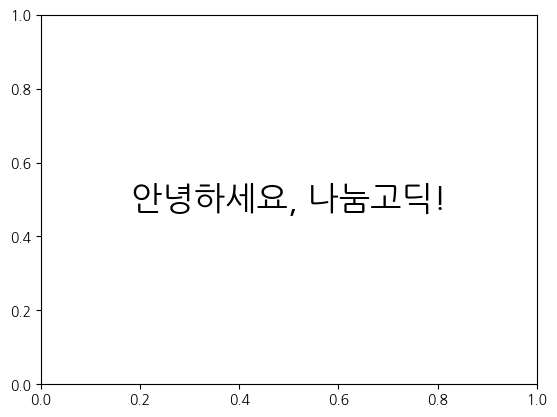

In [ ]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


!apt-get install -y fonts-nanum
!fc-cache -fv


font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'NanumGothic'


plt.text(0.5, 0.5, '안녕하세요, 나눔고딕!', ha='center', va='center', size=24)
plt.show()

import seaborn as sns
from matplotlib import rc

sns.set(style="whitegrid")


rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
trial_register_df = pd.read_csv('data/trial_register.csv',
                                parse_dates=['trial_date']


)
trial_visit_info_df = pd.read_csv('data/trial_visit_info.csv',
                                  parse_dates=['date', 'first_enter_time', 'last_leave_time'], date_format='mixed'





)
trial_access_log_df = pd.read_csv('data/trial_access_log.csv',
                                  parse_dates=['cdate'])
trial_payment_df = pd.read_csv('data/trial_payment.csv')
site_area_df = pd.read_csv('data/site_area.csv')

# access 테이블 단위 변환

In [ ]:
trial_access_log_df.head()

In [ ]:
trial_access_log_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63708 entries, 0 to 63707
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   id         63708 non-null  int64         
 1   checkin    63708 non-null  int64         
 2   cdate      63708 non-null  datetime64[ns]
 3   site_id    63708 non-null  int64         
 4   user_uuid  63708 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 2.4+ MB


In [ ]:
trial_visit_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11477 entries, 0 to 11476
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   site_id           11477 non-null  int64         
 1   date              11477 non-null  datetime64[ns]
 2   stay_time         11477 non-null  object        
 3   stay_time_second  11477 non-null  int64         
 4   first_enter_time  10922 non-null  datetime64[ns]
 5   last_leave_time   10922 non-null  datetime64[ns]
 6   user_uuid         11477 non-null  object        
dtypes: datetime64[ns](3), int64(2), object(2)
memory usage: 627.8+ KB


In [ ]:
access = trial_access_log_df.copy()
access['KST_cdate'] = access['cdate'] + pd.Timedelta(hours=9)

In [ ]:
access.head()

# 중복치 제거

In [ ]:
# 중복값 불러오기
print('trial_register_df:')
display(trial_register_df.duplicated().sum())
print('\ntrial_visit_info_df:')
display(trial_visit_info_df.duplicated().sum())
print('\ntrial_access_log_df:')
display(trial_access_log_df.duplicated().sum())
print('\ntrial_payment_df:')
display(trial_payment_df.duplicated().sum())
print('\nsite_area_df:')
display(site_area_df.duplicated().sum())

trial_register_df:


np.int64(28)


trial_visit_info_df:


np.int64(48)


trial_access_log_df:


np.int64(359)


trial_payment_df:


np.int64(35)


site_area_df:


np.int64(0)

In [ ]:
register = trial_register_df.copy()
visit = trial_visit_info_df.copy()
payment = trial_payment_df.copy()
site = site_area_df.copy()

In [ ]:
register = register.drop_duplicates()
visit = visit.drop_duplicates()
payment = payment.drop_duplicates()
access = access.drop_duplicates()
site = site.drop_duplicates()

print('register:')
display(register.duplicated().sum())
print('\nvisit:')
display(visit.duplicated().sum())
print('\naccess:')
display(access.duplicated().sum())
print('\npayment:')
display(payment.duplicated().sum())
print('\nsite:')
display(site.duplicated().sum())

register:


np.int64(0)


visit:


np.int64(0)


access:


np.int64(0)


payment:


np.int64(0)


site:


np.int64(0)

# Visit 테이블 이상치 제거 (1분 미만 제거)

In [ ]:
visit.head()

In [ ]:
# visit 테이블

len(visit[visit['stay_time_second'] < 60])

26

In [ ]:
visit[visit['stay_time_second'] < 60].value_counts().head()

In [ ]:
visit_cleaned = visit[visit['stay_time_second'] >= 60]
visit_cleaned.head()

In [ ]:
len(visit_cleaned[visit_cleaned['stay_time_second'] < 60])

0

In [ ]:
visit_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11403 entries, 0 to 11476
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   site_id           11403 non-null  int64         
 1   date              11403 non-null  datetime64[ns]
 2   stay_time         11403 non-null  object        
 3   stay_time_second  11403 non-null  int64         
 4   first_enter_time  10848 non-null  datetime64[ns]
 5   last_leave_time   10848 non-null  datetime64[ns]
 6   user_uuid         11403 non-null  object        
dtypes: datetime64[ns](3), int64(2), object(2)
memory usage: 970.7+ KB


In [ ]:
len(visit_cleaned[visit_cleaned['last_leave_time']-visit_cleaned['first_enter_time']< pd.Timedelta(seconds=60)])

0

In [ ]:
len(visit_cleaned[visit_cleaned['first_enter_time'] > visit_cleaned['last_leave_time']])

0

In [ ]:
# access

access.head()

In [ ]:
access['date_only'] = access['KST_cdate'].dt.date
access.head()

In [ ]:
# 입실
enter_access = access[access['checkin'] == 1].groupby(['user_uuid', 'site_id', 'date_only'])['KST_cdate'].min().reset_index()
enter_access.rename(columns={'KST_cdate': 'enter_cdate'}, inplace=True)

# 퇴실
leave_access = access[access['checkin'] == 2].groupby(['user_uuid', 'site_id', 'date_only'])['KST_cdate'].max().reset_index()
leave_access.rename(columns={'KST_cdate': 'leave_cdate'}, inplace=True)

# 입실 + 퇴실 테이블 병합
summary_access = pd.merge(enter_access, leave_access, on=['user_uuid', 'site_id', 'date_only'], how='outer')

summary_access.head()

In [ ]:
summary_access['duration_minutes'] = (summary_access['leave_cdate'] - summary_access['enter_cdate']).dt.total_seconds() / 60
summary_access['outliers'] = summary_access['duration_minutes'] < 1

print(summary_access.head())
print(len(summary_access))

9119


In [ ]:
summary_access[summary_access['duration_minutes'] < 1]

In [ ]:
len(summary_access[summary_access['duration_minutes'] < 1])

45

In [ ]:
summary_access[summary_access['duration_minutes'] < 0]

In [ ]:
len(summary_access[summary_access['duration_minutes'] < 0])

22

# 이상치 세부 분석

In [ ]:
# 예시 1
access[access['user_uuid'] == 'USER_ID_1'].sort_values(by='KST_cdate')

In [ ]:
# 예시 2
access[access['user_uuid'] == 'USER_ID_2'].sort_values(by='KST_cdate')

In [ ]:
# 예시 3
access[access['user_uuid'] == 'USER_ID_3'].sort_values(by='KST_cdate')

access에서 이상치(1분 미만 잔실)로 분류된 행의 수는 총 45개였다. 그 중 22개는 음수의 값으로 조회되어 추가 분석을 진행했다. 추가 분석한 결과, 예시 1, 2, 3과 같이 같은 날짜에 입실 혹은 퇴실이 찍히지 않은 값들이 존재했다. 그 외 늦은 밤 10시~11시에 입실 후 자정이 넘어 새로운 날짜로 넘어가 퇴실이 다음 날 오전으로 찍힌 데이터들이 존재했으며 이로 인해 해당 날짜의 duration_minutes이 음수로 나온 것을 확인했다.

음수 이상치 22행을 분석한 결과 총 4행만 정상적인 데이터로 판단되어 해당 행들의 유저는 유지하였다. 그 외 나머지 18행은 삭제를 했다.

* 1분 미만 잔실 - 23행 삭제
* 음수 이상치 - 18행 삭제
* 총 9,119 행에서 41행 삭제 진행. 9,078행이 잔여.

In [ ]:
target_uuids = [
    'USER_ID_4',
    'USER_ID_5',
    'USER_ID_6',
    'USER_ID_7'
]

summary_access_cleaned = summary_access[
    (summary_access['outliers'] == False) |
    (summary_access['user_uuid'].isin(target_uuids))
]

len(summary_access_cleaned)

9078

# 결측치 대체 (visit 테이블)

In [ ]:
visit_cleaned.head()

In [ ]:
summary_access_cleaned.head()

In [ ]:
summary_access_cleaned = summary_access_cleaned.rename(columns={'date_only':'date'})
summary_access_cleaned.head()

In [ ]:
summary_access_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9078 entries, 0 to 9118
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_uuid         9078 non-null   object        
 1   site_id           9078 non-null   int64         
 2   date              9078 non-null   object        
 3   enter_cdate       8941 non-null   datetime64[ns]
 4   leave_cdate       8952 non-null   datetime64[ns]
 5   duration_minutes  8815 non-null   float64       
 6   outliers          9078 non-null   bool          
dtypes: bool(1), datetime64[ns](2), float64(1), int64(1), object(2)
memory usage: 763.4+ KB


In [ ]:
summary_access_cleaned['date'] = pd.to_datetime(summary_access_cleaned['date'])
summary_access_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9078 entries, 0 to 9118
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_uuid         9078 non-null   object        
 1   site_id           9078 non-null   int64         
 2   date              9078 non-null   datetime64[ns]
 3   enter_cdate       8941 non-null   datetime64[ns]
 4   leave_cdate       8952 non-null   datetime64[ns]
 5   duration_minutes  8815 non-null   float64       
 6   outliers          9078 non-null   bool          
dtypes: bool(1), datetime64[ns](3), float64(1), int64(1), object(1)
memory usage: 763.4+ KB


In [ ]:
key = ['user_uuid', 'site_id', 'date']

# 키당 1행으로 정리 (중복이 있으면 merge 후 행이 불어남)
filler = (summary_access_cleaned[key + ['enter_cdate', 'leave_cdate']]
          .drop_duplicates(subset=key))

print('summary 행수:', len(summary_access_cleaned), '→ 키 중복 제거 후:', len(filler))

summary 행수: 9078 → 키 중복 제거 후: 9078


In [ ]:
before = len(visit_cleaned)

visit_filled = visit_cleaned.merge(filler, on=key, how='left')

visit_filled['first_enter_time'] = visit_filled['first_enter_time'].fillna(visit_filled['enter_cdate'])
visit_filled['last_leave_time']  = visit_filled['last_leave_time'].fillna(visit_filled['leave_cdate'])

visit_filled = visit_filled.drop(columns=['enter_cdate', 'leave_cdate'])

print('행수 변화:', before, '→', len(visit_filled))   # 같아야 정상

행수 변화: 11403 → 11403


In [ ]:
visit_filled.isna().sum()

In [ ]:
visit_filled[
    visit_filled['first_enter_time'].isna() |
    visit_filled['last_leave_time'].isna()
]

In [ ]:
visit_filled_clean = visit_filled.dropna()

visit_filled_clean.isna().sum()

In [ ]:
visit_filled_clean.head()

In [ ]:
visit_filled[visit_filled['stay_time_second'] < 60]

In [ ]:
visit_filled_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11317 entries, 0 to 11402
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   site_id           11317 non-null  int64         
 1   date              11317 non-null  datetime64[ns]
 2   stay_time         11317 non-null  object        
 3   stay_time_second  11317 non-null  int64         
 4   first_enter_time  11317 non-null  datetime64[ns]
 5   last_leave_time   11317 non-null  datetime64[ns]
 6   user_uuid         11317 non-null  object        
dtypes: datetime64[ns](3), int64(2), object(2)
memory usage: 965.4+ KB


In [ ]:
hours = visit_filled_clean['stay_time_second'] // 3600
minutes = (visit_filled_clean['stay_time_second'] % 3600) // 60

# 2자리 숫자로 맞추기 (예: '01:11', '04:35')
visit_filled_clean['stay_time_text'] = (
    hours.astype(str).str.zfill(2) + ':' + minutes.astype(str).str.zfill(2)
)

# 수치형으로 컬럼 추가
visit_filled_clean['stay_time_minute'] = visit_filled_clean['stay_time_second'] // 60

visit_filled_clean.head()

In [ ]:
# 시:분 형태만 남기기
visit_filled_clean['first_enter_time_only'] = visit_filled_clean['first_enter_time'].dt.strftime('%H:%M')
visit_filled_clean['last_leave_time_only'] = visit_filled_clean['last_leave_time'].dt.strftime('%H:%M')

visit_filled_clean.head()

In [ ]:
register.head()

In [ ]:
# ‘신규 가입자는 딱 1번 3일 체험을 이용할 수 있음’에도 불구하고
# 1) 같은 날 2회 3일 체험을 신청하거나
# 2) 서로 다른 날 2회 3일 체험을 신청한 경우가 존재함

register_unique = register.sort_values('trial_date').drop_duplicates(subset=['user_uuid'], keep='first')

In [ ]:
payment.head()

In [ ]:
payment_unique = payment.groupby('user_uuid', as_index=False)['is_payment'].max()

In [ ]:
site.head()

In [ ]:
# 마스터 테이블 생성

tb1 = pd.merge(visit_filled_clean, register_unique, on='user_uuid', how='left')
tb2 = pd.merge(tb1, payment_unique, on='user_uuid', how='left')
master_tb = pd.merge(tb2, site, on='site_id', how='left')

master_tb.head()

In [ ]:
# 검증 (11,317행 유지 확인)
print(f"방문 행 수: {len(visit_filled_clean)} -> 마스터 테이블 행 수: {len(master_tb)}")

방문 행 수: 11317 -> 마스터 테이블 행 수: 11317


In [ ]:
# 병합 후 결측치 최종 확인
master_tb.isna().sum()

In [ ]:
master_tb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11317 entries, 0 to 11316
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   site_id                11317 non-null  int64         
 1   date                   11317 non-null  datetime64[ns]
 2   stay_time              11317 non-null  object        
 3   stay_time_second       11317 non-null  int64         
 4   first_enter_time       11317 non-null  datetime64[ns]
 5   last_leave_time        11317 non-null  datetime64[ns]
 6   user_uuid              11317 non-null  object        
 7   stay_time_text         11317 non-null  object        
 8   stay_time_minute       11317 non-null  int64         
 9   first_enter_time_only  11317 non-null  object        
 10  last_leave_time_only   11317 non-null  object        
 11  trial_date             11317 non-null  datetime64[ns]
 12  is_payment             11317 non-null  int64         
 13  a

In [ ]:
# csv 파일 추출

master_tb.to_csv('master_table.csv', index=False, encoding='utf-8-sig')
# 후속 모델링 파트 연계를 위한 trial_register 저장
if 'register' in locals() and register is not None:
    register.to_csv('trial_register.csv', index=False, encoding='utf-8-sig')


# ============================================================
# [PART 2] 탐색적 데이터 분석
# ============================================================
이 파트는 전처리된 `master_table.csv`를 기반으로 체류시간, 시간대별/요일별/지점별 방문 패턴, 이상치 심층 탐색, 1박 야간 분할 세션 단일 행 복원 및 중복 세션 정제를 수행하여 `찐최종_마스터_테이블`을 생성하는 단계입니다.

# 공유오피스 이용 행태 EDA 통합 분석

본 분석은 공유오피스 이용 데이터(`master_table.csv`)를 기반으로 입실 시간대, 체류시간 분포, 일별 급증(스파이크) 원인 및 지점별 특성을 분석한 최종 통합 EDA 노트북이다.
'EDA 정리' 시트의 분석 흐름(좌 -> 우, 윗줄 -> 아랫줄)에 맞추어 순차적으로 전개한다.

In [ ]:
# 필수 라이브러리 및 master_table.csv 로드
import os

file_path = 'data/master_table.csv'
if not os.path.exists(file_path):
    if os.path.exists('master_table.csv'):
        file_path = 'master_table.csv'
    elif os.path.exists(os.path.join("data", "master_table.csv")):
        file_path = os.path.join("data", "master_table.csv")
    elif 'master_tb' in locals() and master_tb is not None:
        master_tb.to_csv('master_table.csv', index=False, encoding='utf-8-sig')
        file_path = 'master_table.csv'

df = pd.read_csv(file_path)

print('데이터 첫 5행:')
display(df.head())
print('\n데이터 정보:')
df.info()

데이터 첫 5행:



데이터 정보:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11317 entries, 0 to 11316
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   site_id                11317 non-null  int64 
 1   date                   11317 non-null  object
 2   stay_time              11317 non-null  object
 3   stay_time_second       11317 non-null  int64 
 4   first_enter_time       11317 non-null  object
 5   last_leave_time        11317 non-null  object
 6   user_uuid              11317 non-null  object
 7   stay_time_text         11317 non-null  object
 8   stay_time_minute       11317 non-null  int64 
 9   first_enter_time_only  11317 non-null  object
 10  last_leave_time_only   11317 non-null  object
 11  trial_date             11317 non-null  object
 12  is_payment             11317 non-null  int64 
 13  area_pyeong            11317 non-null  int64 
dtypes: int64(5), object(9)
memory usage: 1.2+ MB


In [ ]:
# 날짜 및 시간 컬럼 형변환
df['date'] = pd.to_datetime(df['date'])
df['first_enter_time'] = pd.to_datetime(df['first_enter_time'])
df['last_leave_time'] = pd.to_datetime(df['last_leave_time'])
df['trial_date'] = pd.to_datetime(df['trial_date'])

# 분석용 기본 파생 변수 생성
df['stay_minute'] = df['stay_time_second'] / 60.0
df['enter_hour'] = df['first_enter_time'].dt.hour
df['leave_hour'] = df['last_leave_time'].dt.hour
df['weekday'] = df['date'].dt.day_name()

day_map = {'Monday': '월', 'Tuesday': '화', 'Wednesday': '수', 'Thursday': '목', 'Friday': '금', 'Saturday': '토', 'Sunday': '일'}
df['day_name_kr'] = df['weekday'].map(day_map)

print('형변환 및 기본 파생변수 생성 완료')

형변환 및 기본 파생변수 생성 완료


---
# 1. 체류시간 분포 및 시간대별 입실 패턴

## 1-1. 당일 체류시간(stay_minute) 분포 및 이상치 탐색

당일 실제 체류시간(분 단위)의 중심 경향과 이상치 분포를 파악하기 위해 박스플롯과 히스토그램(KDE)을 결합하여 분석한다.

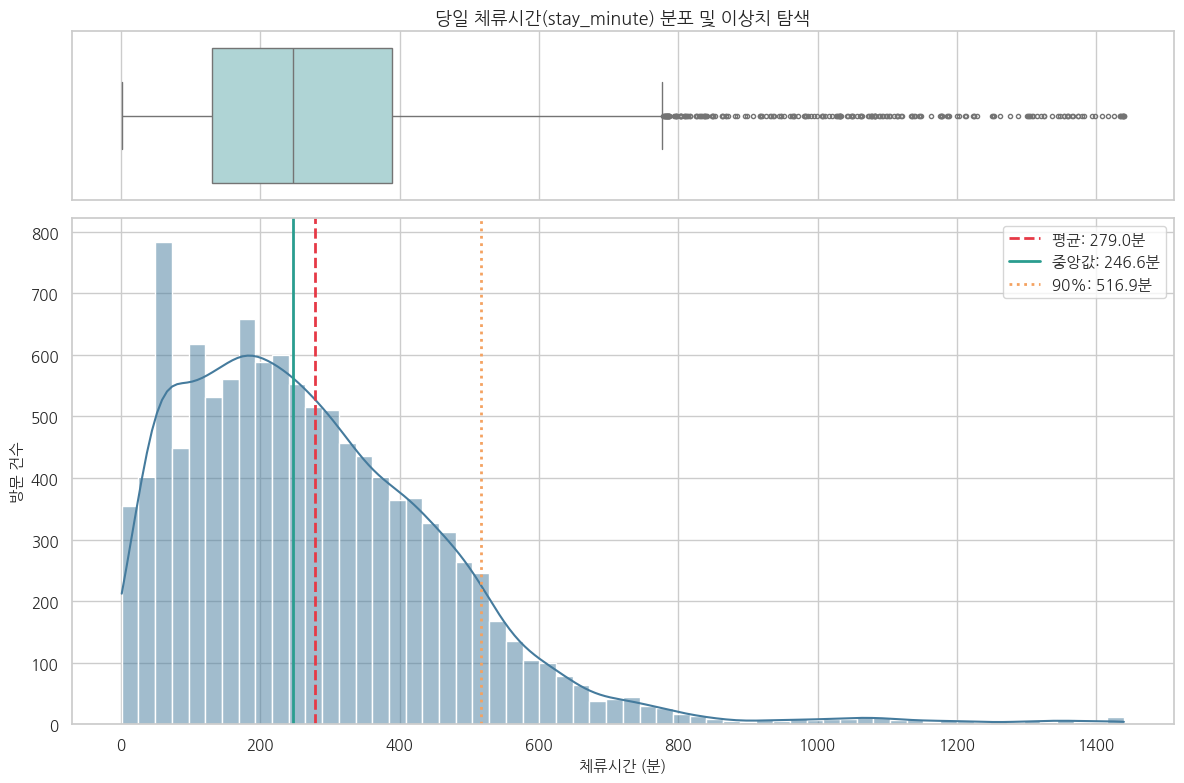

In [ ]:
# 1-1. 체류시간 분포 시각화 (박스플롯 + 히스토그램 & KDE)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [1, 3]})

# 상단 박스플롯
sns.boxplot(x=df['stay_minute'], ax=axes[0], color='#a8dadc', fliersize=3)
axes[0].set_title('당일 체류시간(stay_minute) 분포 및 이상치 탐색', fontsize=13, fontweight='bold')
axes[0].set_xlabel('')

# 하단 히스토그램 및 KDE
sns.histplot(df['stay_minute'], kde=True, ax=axes[1], bins=60, color='#457b9d', stat='count')
axes[1].set_xlabel('체류시간 (분)', fontsize=11)
axes[1].set_ylabel('방문 건수', fontsize=11)

mean_val = df['stay_minute'].mean()
median_val = df['stay_minute'].median()
p90_val = df['stay_minute'].quantile(0.90)

axes[1].axvline(mean_val, color='#e63946', linestyle='--', linewidth=2, label=f'평균: {mean_val:.1f}분')
axes[1].axvline(median_val, color='#2a9d8f', linestyle='-', linewidth=2, label=f'중앙값: {median_val:.1f}분')
axes[1].axvline(p90_val, color='#f4a261', linestyle=':', linewidth=2, label=f'90%: {p90_val:.1f}분')

axes[1].legend(fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# 체류시간 주요 통계치 확인
print(f"평균 체류시간: {mean_val:.1f}분")
print(f"중앙 체류시간: {median_val:.1f}분")
print(f"90% 백분위수: {p90_val:.1f}분")
print(f"최대 체류시간: {df['stay_minute'].max():.1f}분")

평균 체류시간: 279.0분
중앙 체류시간: 246.6분
90% 백분위수: 516.9분
최대 체류시간: 1439.6분


* 해석:
- 체류시간 분포는 우측으로 긴 꼬리를 가지며 평균(279.0분)이 중앙값(246.6분)보다 32.4분 높게 나타남.
- 전체 이용의 90%가 516.9분(약 8.6시간) 이내에 분포함.

## 1-2. 시간대별 지점별 방문 패턴

입실 시간대(0~23시)에 따른 지점별(site_id) 방문 건수의 흐름을 꺾은선 그래프로 비교한다.

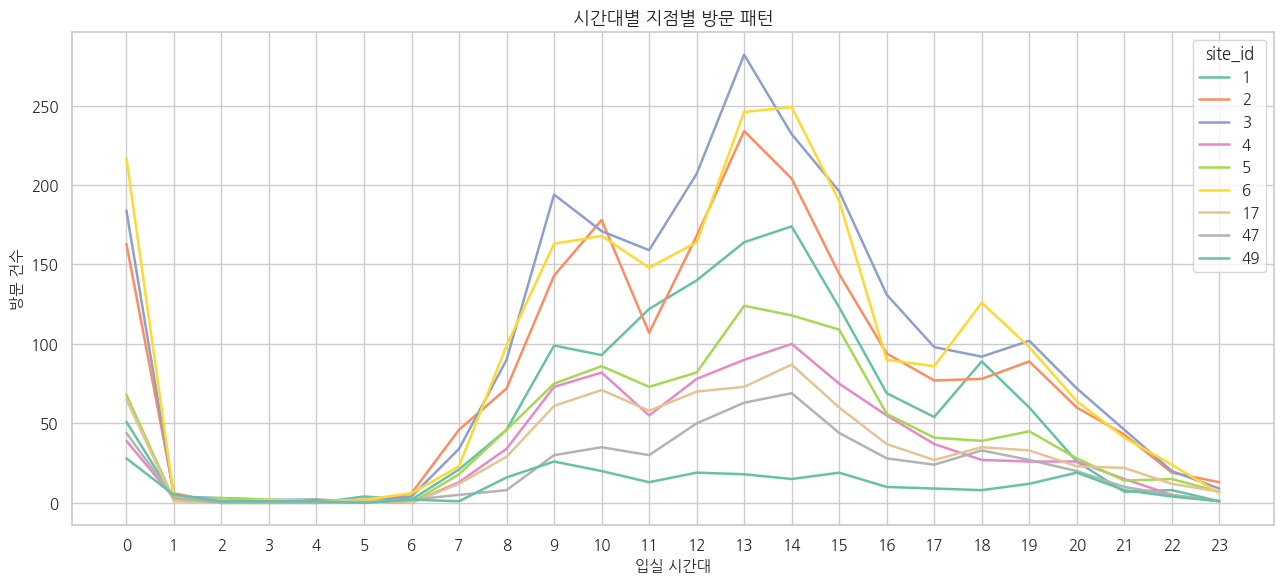

In [ ]:
# 1-2. 시간대별 지점별 방문 패턴 피벗 및 시각화
hour_site = df.groupby(['enter_hour', 'site_id']).size().unstack(fill_value=0)

plt.figure(figsize=(13, 6))
palette = sns.color_palette('Set2', n_colors=df['site_id'].nunique())

for i, site in enumerate(sorted(df['site_id'].unique())):
    plt.plot(hour_site.index, hour_site[site], marker='', linewidth=1.8, label=f'{site}', color=palette[i])

plt.title('시간대별 지점별 방문 패턴', fontsize=13, fontweight='bold')
plt.xlabel('입실 시간대', fontsize=11)
plt.ylabel('방문 건수', fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title='site_id', loc='upper right')
plt.tight_layout()
plt.show()

* 해석:
- 모든 지점에서 점심 직후인 13~14시에 가장 높은 방문 피크가 나타남.
- 특히 site 3, site 6, site 2가 전 시간대에 걸쳐 가장 높은 이용 볼륨을 보임.
- 0시(자정) 시간대에도 전 지점에서 공통적으로 이용 건수가 급증하는 특이 패턴이 관찰됨.

## 1-3. 시간대별 입실 방문 건수 및 이동평균 & 입실 시간에 따른 체류시간 변화

시간대별 전체 입실량과 이동평균(피크 구간 강조), 그리고 입실 시각에 따른 체류시간 변화 추이를 비교한다.

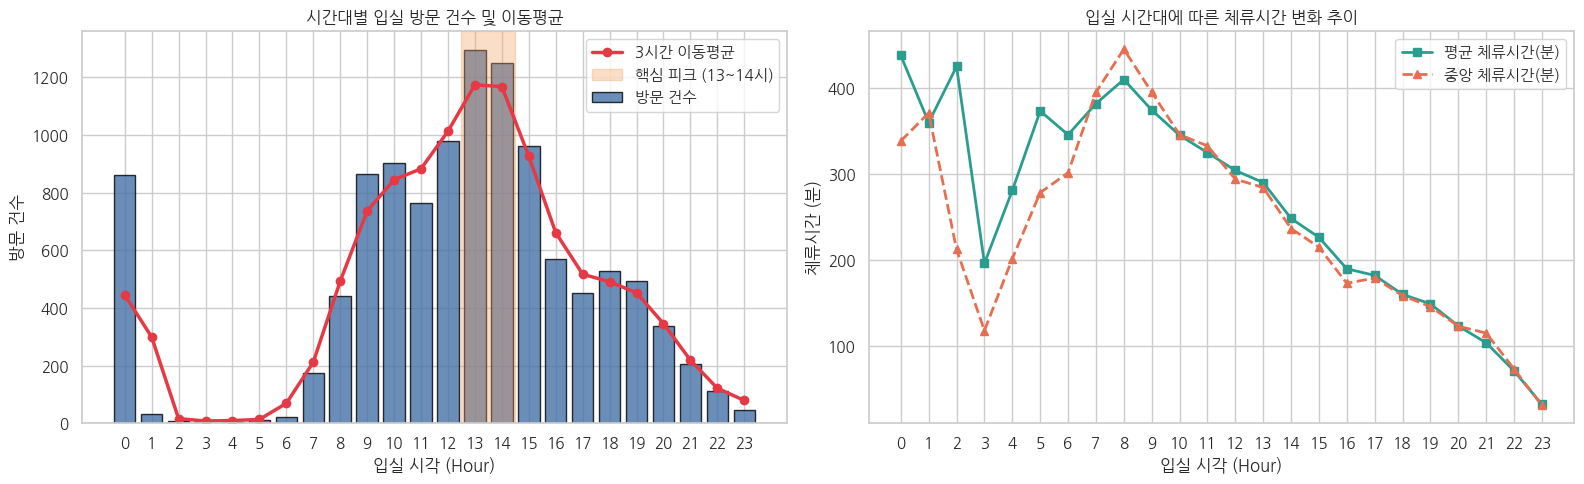

In [ ]:
# 1-3. 입실 시간대별 집계 및 2단 서브플롯 시각화
hourly_stats = df.groupby('enter_hour').agg(
    방문건수=('user_uuid', 'count'),
    평균체류=('stay_minute', 'mean'),
    중앙체류=('stay_minute', 'median')
).reset_index()

hourly_stats['3h_이동평균'] = hourly_stats['방문건수'].rolling(window=3, min_periods=1, center=True).mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (1) 시간대별 입실 방문 건수 및 3시간 이동평균
axes[0].bar(hourly_stats['enter_hour'], hourly_stats['방문건수'], color='#4572a7', edgecolor='black', alpha=0.8, label='방문 건수')
axes[0].plot(hourly_stats['enter_hour'], hourly_stats['3h_이동평균'], color='#e63946', linewidth=2.5, marker='o', label='3시간 이동평균')
axes[0].axvspan(12.5, 14.5, color='#f4a261', alpha=0.35, label='핵심 피크 (13~14시)')
axes[0].set_title('시간대별 입실 방문 건수 및 이동평균', fontsize=12, fontweight='bold')
axes[0].set_xlabel('입실 시각 (Hour)')
axes[0].set_ylabel('방문 건수')
axes[0].set_xticks(range(0, 24))
axes[0].legend(loc='upper right')

# (2) 입실 시간대에 따른 체류시간 변화 추이
axes[1].plot(hourly_stats['enter_hour'], hourly_stats['평균체류'], color='#2a9d8f', marker='s', linewidth=2, label='평균 체류시간(분)')
axes[1].plot(hourly_stats['enter_hour'], hourly_stats['중앙체류'], color='#e76f51', marker='^', linewidth=2, linestyle='--', label='중앙 체류시간(분)')
axes[1].set_title('입실 시간대에 따른 체류시간 변화 추이', fontsize=12, fontweight='bold')
axes[1].set_xlabel('입실 시각 (Hour)')
axes[1].set_ylabel('체류시간 (분)')
axes[1].set_xticks(range(0, 24))
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

* 해석:
- 입실은 13~14시(13시 1,294건, 14시 1,248건)에 집중되는 전형적인 주간 피크를 보임.
- 입실 시각이 늦어질수록 당일 체류시간은 단조 감소함 (아침 8시 중앙값 445.7분 -> 밤 23시 중앙값 30.2분).

---
# 2. 요일별 패턴, 일별 스파이크 및 12월 9일 심층 탐색

## 2-1. 요일별 시간대 방문량

요일별로 시간대별 입실 패턴에 차이가 있는지 월요일부터 일요일까지 비교한다.

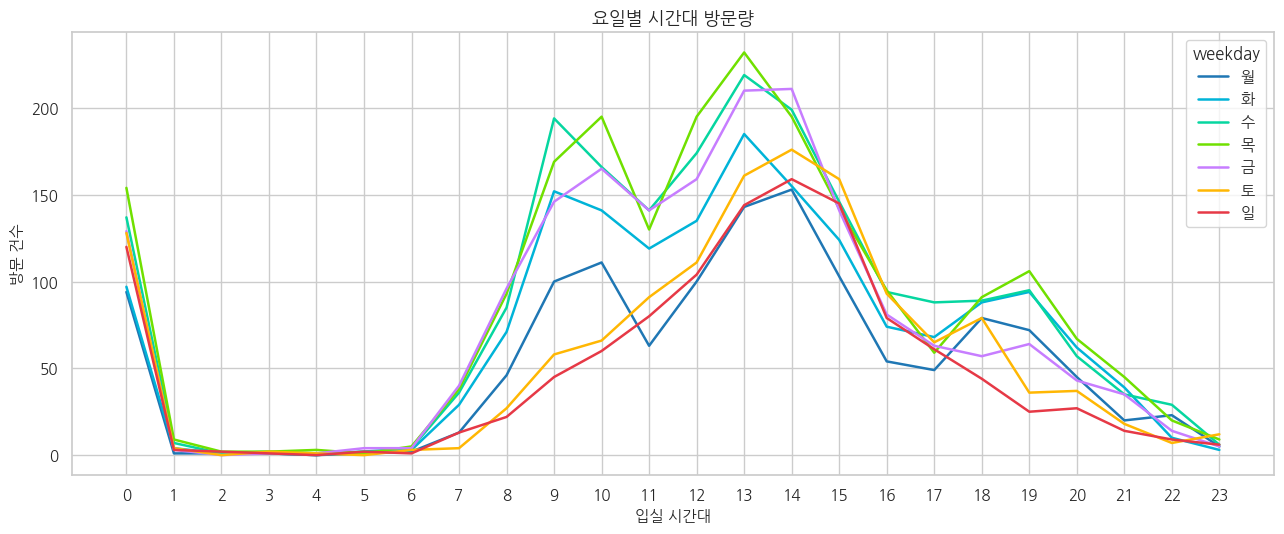

In [ ]:
# 2-1. 요일별 시간대별 방문 건수 꺾은선 그래프
weekday_order = ['월', '화', '수', '목', '금', '토', '일']
weekday_hour = df.groupby(['enter_hour', 'day_name_kr']).size().unstack(fill_value=0)[weekday_order]

plt.figure(figsize=(13, 5.5))
colors = ['#1f77b4', '#00b4d8', '#06d6a0', '#70e000', '#c77dff', '#ffb703', '#e63946']

for i, day in enumerate(weekday_order):
    plt.plot(weekday_hour.index, weekday_hour[day], label=day, color=colors[i], linewidth=1.8)

plt.title('요일별 시간대 방문량', fontsize=13, fontweight='bold')
plt.xlabel('입실 시간대', fontsize=11)
plt.ylabel('방문 건수', fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title='weekday', loc='upper right')
plt.tight_layout()
plt.show()

* 해석:
- 평일(화, 수, 목, 금)은 12~15시에 압도적인 피크가 형성되며 목요일과 수요일의 방문량이 가장 많음.
- 주말(토, 일)은 평일 대비 방문량이 적고, 피크 시간대가 14~15시 부근으로 상대적으로 완만하게 나타남.

## 2-2. 일별 전체 방문 건수 시계열 추이 (스파이크 구간)

2021년 5월부터 2024년 1월까지 전체 일별 방문 건수의 시계열 흐름과 평균선을 확인한다.

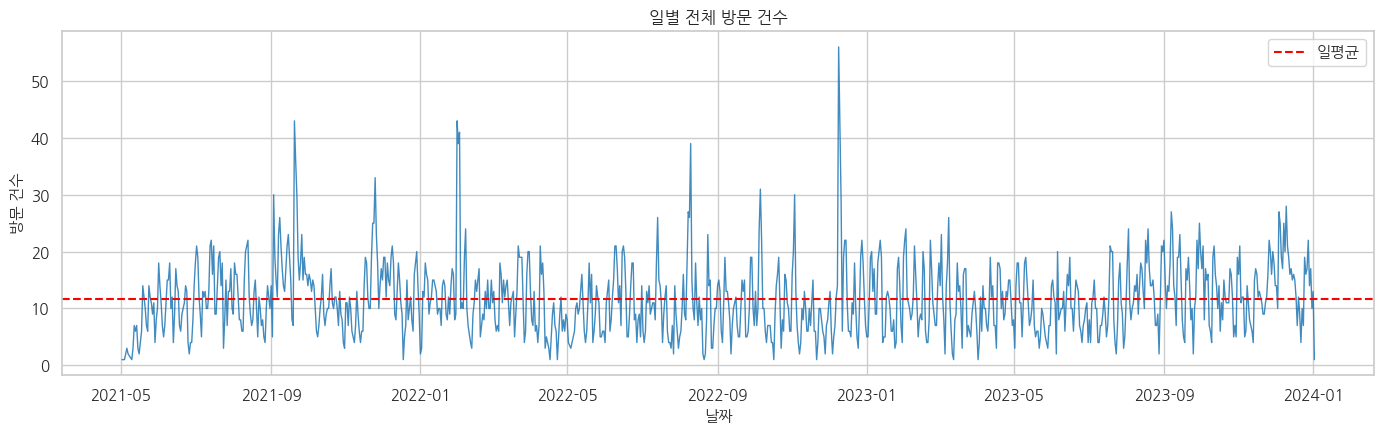

일평균 방문 건수: 11.7건
최대 방문 건수: 56건 (날짜: 2022-12-09)


In [ ]:
# 2-2. 일별 전체 방문 건수 시계열 추이
daily_visits = df.groupby('date').size().reset_index(name='방문건수')
daily_mean = daily_visits['방문건수'].mean()

plt.figure(figsize=(14, 4.5))
plt.plot(daily_visits['date'], daily_visits['방문건수'], color='#1f77b4', linewidth=1, alpha=0.85)
plt.axhline(daily_mean, color='red', linestyle='--', linewidth=1.5, label='일평균')

plt.title('일별 전체 방문 건수', fontsize=12)
plt.xlabel('날짜', fontsize=11)
plt.ylabel('방문 건수', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f"일평균 방문 건수: {daily_mean:.1f}건")
print(f"최대 방문 건수: {daily_visits['방문건수'].max()}건 (날짜: {daily_visits.loc[daily_visits['방문건수'].idxmax(), 'date'].strftime('%Y-%m-%d')})")

* 해석:
- 일평균 방문 건수는 약 11.6건 수준을 유지하나, 특정 일자에 40~50건 이상으로 치솟는 스파이크 구간들이 관찰됨.
- 특히 2022년 12월 9일에 56건으로 전체 기간 중 최고치를 기록함.

## 2-3. 의문점 탐색 중 발견한 현상 (12월 9일 스파이크 47번 지점 등장)

최대 급증일인 2022-12-09의 방문 원인을 지점별, 신청일별, 오픈 직후 추이로 분해한다.

In [ ]:
# (1) 2022-12-09 당일 지점별 방문 건수 및 비율
peak_date = '2022-12-09'
peak_df = df[df['date'] == peak_date]

site_peak = peak_df.groupby('site_id').agg(
    방문건수=('user_uuid', 'count'),
    고유유저=('user_uuid', 'nunique')
).reset_index()
site_peak['비율(%)'] = (site_peak['방문건수'] / len(peak_df) * 100).round(1)

print("=== 2022-12-09 지점별 방문 현황 ===")
display(site_peak.sort_values(by='방문건수', ascending=False))

=== 2022-12-09 지점별 방문 현황 ===


In [ ]:
# (2) 47번 지점 운영 기간 및 누적 방문건수
site47_all = df[df['site_id'] == 47]
print(f"47번 지점 첫 등장일: {site47_all['date'].min().strftime('%Y-%m-%d')}")
print(f"47번 지점 마지막 등장일: {site47_all['date'].max().strftime('%Y-%m-%d')}")
print(f"47번 지점 전체 누적 방문건수: {len(site47_all)}건")

47번 지점 첫 등장일: 2022-12-09
47번 지점 마지막 등장일: 2024-01-01
47번 지점 전체 누적 방문건수: 531건


In [ ]:
# (3) 2022-12-09 당일 방문자의 체험 신청일(trial_date) 분포
trial_date_dist = peak_df['trial_date'].value_counts().reset_index()
trial_date_dist.columns = ['체험신청일(trial_date)', '방문건수']
display(trial_date_dist)

In [ ]:
# (4) 47번 지점 첫 등장 직후(12/9~12/14) 일별 방문 건수 추이
site47_trend = site47_all[(site47_all['date'] >= '2022-12-09') & (site47_all['date'] <= '2022-12-14')]
display(site47_trend.groupby('date')['user_uuid'].count().to_frame(name='방문건수'))

* 해석:
- 2022-12-09 전체 56건 중 45건(80.4%)이 47번 지점에 집중됨.
- 47번 지점은 바로 당일인 2022-12-09에 데이터 상 처음 등장한 신규 지점임.
- 당일 방문자의 83.9%(47명)가 직전 날인 12월 8일에 체험을 신청한 이용자임.
- 방문 추이는 12/9 45건 -> 12/10 34건 -> 12/11 27건으로 이어지다 12/12에 1건으로 급감하여 3일 무료체험 소진 패턴과 일치함.

---
# 3. 유저별 방문 일수 및 요일별 일평균 방문량

## 3-1. 유저별 체험 기간 내 총 방문 일수 분포

3일 무료체험 신청자들이 실제로 며칠 동안 방문했는지 이용자 수를 집계한다.

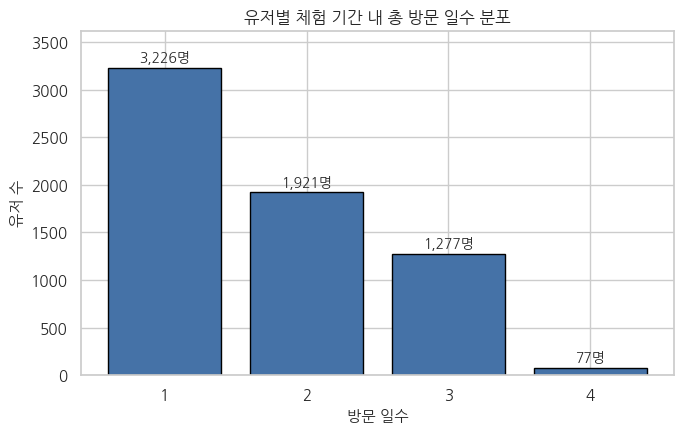

In [ ]:
# 3-1. 유저별 총 방문 일수 분포 집계 및 시각화
user_visit_days = df.groupby('user_uuid')['date'].nunique().value_counts().sort_index().reset_index()
user_visit_days.columns = ['방문 일수', '유저 수']

plt.figure(figsize=(7, 4.5))
bars = plt.bar(user_visit_days['방문 일수'].astype(str), user_visit_days['유저 수'], color='#4572a7', edgecolor='black')

plt.title('유저별 체험 기간 내 총 방문 일수 분포', fontsize=12, fontweight='bold')
plt.xlabel('방문 일수', fontsize=11)
plt.ylabel('유저 수', fontsize=11)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 60, f"{y:,}명", ha='center', fontsize=10)

plt.ylim(0, max(user_visit_days['유저 수']) * 1.12)
plt.tight_layout()
plt.show()

display(user_visit_days)

* 해석:
- 전체 이용자의 약 49.6%(3,226명)가 1일만 방문하고 이탈함.
- 2일 방문자는 1,921명(29.5%), 3일 방문자는 1,277명(19.6%)이며 4일 이상은 77명에 불과함.

## 3-2. 요일별 일평균 방문 건수

요일에 따른 일평균 오피스 방문 건수를 비교한다.

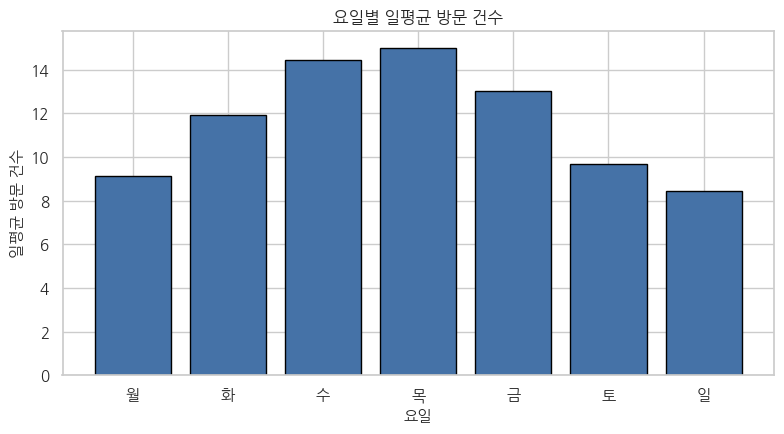

In [ ]:
# 3-2. 요일별 일평균 방문 건수 계산 및 시각화
daily_by_dow = df.groupby(['date', 'day_name_kr']).size().reset_index(name='방문건수')
dow_avg = daily_by_dow.groupby('day_name_kr')['방문건수'].mean().reindex(weekday_order).reset_index()
dow_avg.columns = ['요일', '일평균 방문 건수']

plt.figure(figsize=(8, 4.5))
plt.bar(dow_avg['요일'], dow_avg['일평균 방문 건수'], color='#4572a7', edgecolor='black')

plt.title('요일별 일평균 방문 건수', fontsize=12)
plt.xlabel('요일', fontsize=11)
plt.ylabel('일평균 방문 건수', fontsize=11)
plt.tight_layout()
plt.show()

display(dow_avg.round(1))

* 해석:
- 목요일(14.8건), 수요일(14.4건), 금요일(13.0건) 순으로 평일 중후반에 일평균 방문 건수가 높음.
- 일요일(8.3건)과 월요일(9.1건)은 상대적으로 낮은 수준을 기록함.

---
# 4. 체류시간 구간별 분포 및 지점별 종합 운영 현황

## 4-1. 체류시간 구간별 이용 분포

체류시간을 6개 주요 구간으로 그룹화하여 구간별 이용 건수와 비중을 확인한다.

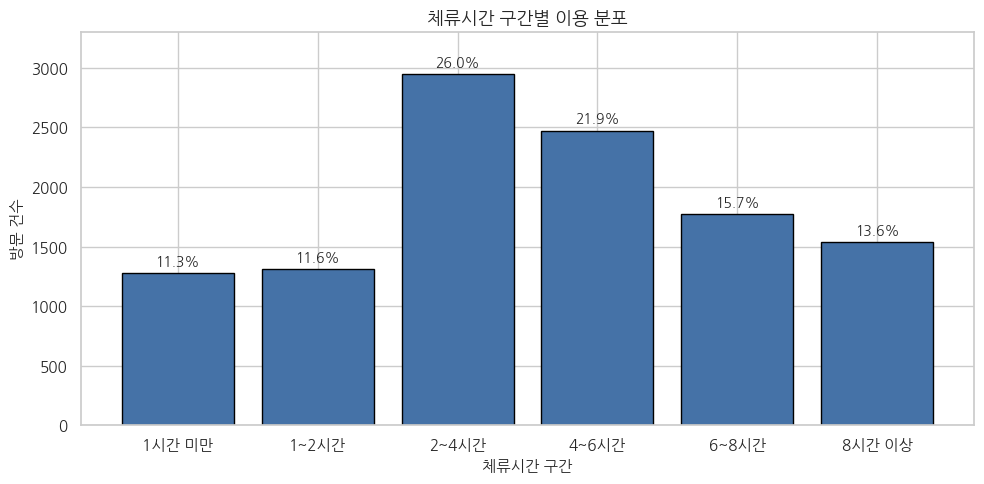

In [ ]:
# 4-1. 체류시간 6개 구간 범주화 및 시각화
bins_6 = [0, 60, 120, 240, 360, 480, float('inf')]
labels_6 = ['1시간 미만', '1~2시간', '2~4시간', '4~6시간', '6~8시간', '8시간 이상']

df['stay_group_6'] = pd.cut(df['stay_minute'], bins=bins_6, labels=labels_6, include_lowest=True)
stay_6_dist = df['stay_group_6'].value_counts(sort=False).reset_index()
stay_6_dist.columns = ['체류시간 구간', '방문 건수']
stay_6_dist['비율(%)'] = (stay_6_dist['방문 건수'] / len(df) * 100).round(1)

plt.figure(figsize=(10, 5))
bars = plt.bar(stay_6_dist['체류시간 구간'], stay_6_dist['방문 건수'], color='#4572a7', edgecolor='black')

plt.title('체류시간 구간별 이용 분포', fontsize=13)
plt.xlabel('체류시간 구간', fontsize=11)
plt.ylabel('방문 건수', fontsize=11)

for bar, pct in zip(bars, stay_6_dist['비율(%)']):
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 60, f"{pct}%", ha='center', fontsize=10)

plt.ylim(0, max(stay_6_dist['방문 건수']) * 1.12)
plt.tight_layout()
plt.show()

display(stay_6_dist)

* 해석:
- 2 ~ 4시간(26.0%)과 4~6시간(21.9%) 구간에 전체 이용의 47.9%가 집중됨.
- 8시간 이상 장시간 체류자도 13.6%로 상당 비중을 차지함.

## 4-2. * 부록: 지점별 종합 운영 현황 집계표

지점별 면적, 누적 방문량, 고유 유저 수, 체류시간 및 유효 운영 기간을 종합 정리한다.

In [ ]:
# 4-2. 지점별 종합 집계표 생성
site_summary = df.groupby('site_id').agg(
    면적평수=('area_pyeong', 'first'),
    방문건수=('user_uuid', 'count'),
    고유유저수=('user_uuid', 'nunique'),
    평균체류분=('stay_minute', lambda x: round(x.mean(), 1)),
    중앙체류분=('stay_minute', lambda x: round(x.median(), 1)),
    최초방문일=('date', 'min'),
    최종방문일=('date', 'max')
).reset_index()

site_summary['운영일수'] = (site_summary['최종방문일'] - site_summary['최초방문일']).dt.days + 1
site_summary['일평균방문'] = (site_summary['방문건수'] / site_summary['운영일수']).round(2)

# 방문건수 기준 내림차순 정렬
display(site_summary.sort_values('방문건수', ascending=False))

* 해석:
- 1, 2, 3번 지점은 약 970일 이상 운영된 초기 거점이며, site 3(2,335건)과 site 6(2,217건)의 방문 볼륨이 가장 큼.
- 17번, 47번, 49번 지점은 2022년 하반기~2023년에 진입한 신규 지점으로 운영일수가 짧아 단순 누적 건수 비교 시 운영일수 보정이 필요함.

---
# 5. 0시 입실자의 퇴실 시각 및 10분 이하 상세 점검

## 5-1. 0시 입실자의 퇴실 시간 분포

0시에 입실한 총 859건의 세션이 당일 몇 시에 퇴실했는지 분포를 확인한다.

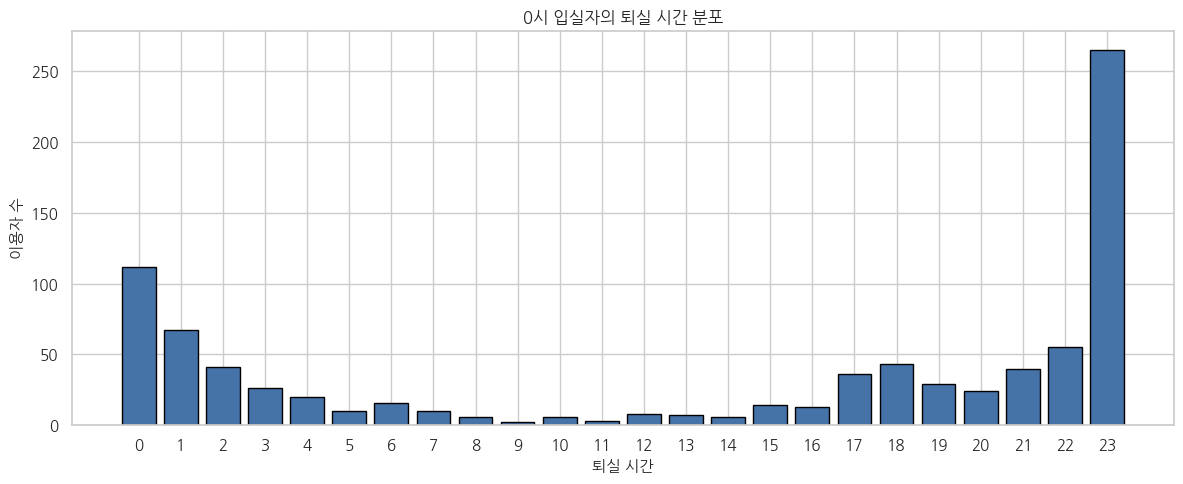

In [ ]:
# 5-1. 0시 입실자의 퇴실 시간 분포 집계 및 시각화
h0_df = df[df['enter_hour'] == 0]
leave_hour_dist = h0_df['leave_hour'].value_counts().sort_index().reindex(range(24), fill_value=0)

plt.figure(figsize=(12, 5))
plt.bar(leave_hour_dist.index, leave_hour_dist.values, color='#4572a7', edgecolor='black')

plt.title('0시 입실자의 퇴실 시간 분포', fontsize=12)
plt.xlabel('퇴실 시간', fontsize=11)
plt.ylabel('이용자 수', fontsize=11)
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

* 해석:
- 0시 입실 세션의 퇴실 시각은 0시 직후(112건)와 밤 23시(265건)에 집중되는 극단적인 U자형 형태를 보임.
- 특히 23시 퇴실자가 약 30%를 차지하는 점에 주목하여 세부 로그 확인이 필요함.

## 5-2. 1) 10분 이하가 생각보다 많았다 -> 현상 확인을 위한 EDA 진행

공유오피스 특성상 최소 1시간 이상 이용할 것으로 예상했으나 10분 이하 이용자가 많아, 상세 구간별 분포와 입퇴실 시각을 점검한다.

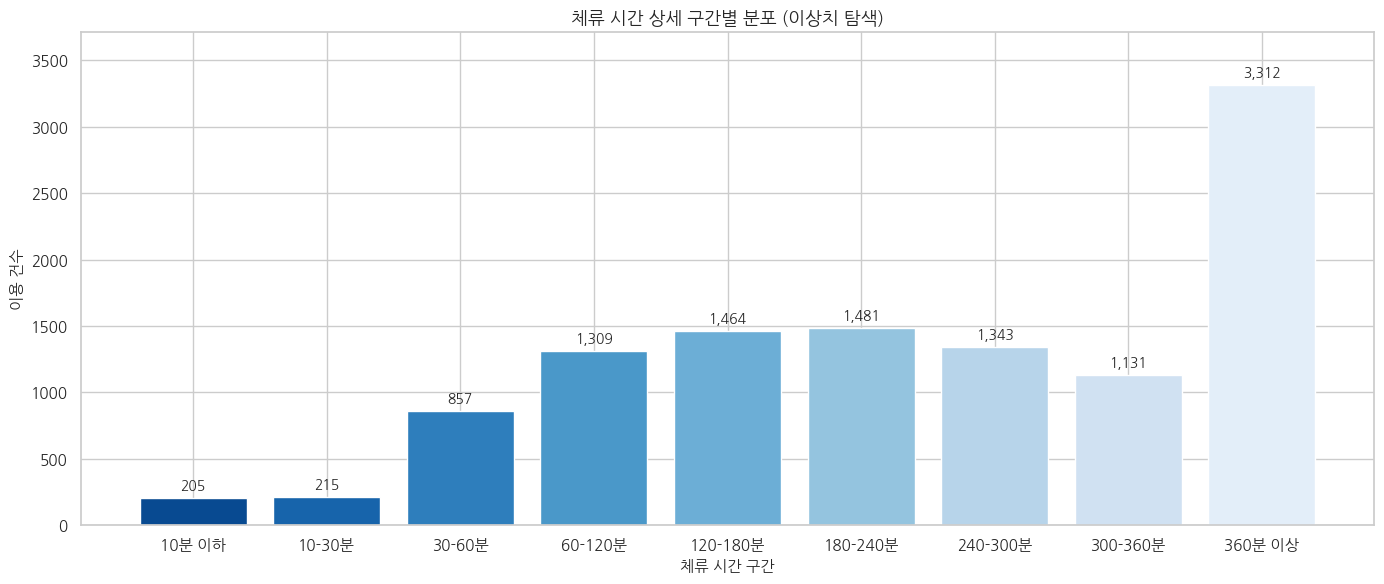

In [ ]:
# 5-2. 체류 시간 상세 구간별 분포 (이상치 탐색)
bins_detail = [0, 10, 30, 60, 120, 180, 240, 300, 360, float('inf')]
labels_detail = ['10분 이하', '10-30분', '30-60분', '60-120분', '120-180분', '180-240분', '240-300분', '300-360분', '360분 이상']

detail_counts = pd.cut(df['stay_minute'], bins=bins_detail, labels=labels_detail, include_lowest=True).value_counts(sort=False).reset_index()
detail_counts.columns = ['체류 시간 구간', '이용 건수']

plt.figure(figsize=(14, 6))
colors_detail = sns.color_palette("Blues_r", n_colors=len(labels_detail))
bars = plt.bar(detail_counts['체류 시간 구간'], detail_counts['이용 건수'], color=colors_detail)

plt.title('체류 시간 상세 구간별 분포 (이상치 탐색)', fontsize=13)
plt.xlabel('체류 시간 구간', fontsize=11)
plt.ylabel('이용 건수', fontsize=11)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 60, f"{y:,}", ha='center', fontsize=10)

plt.ylim(0, max(detail_counts['이용 건수']) * 1.12)
plt.tight_layout()
plt.show()

display(detail_counts)

In [ ]:
# 10분 이하 이용자의 자정 입실 및 전날 23:59:59 퇴실 연계 확인
short_df = df[df['stay_minute'] <= 10]
exact_00_short = (short_df['first_enter_time'].dt.time.astype(str) == '00:00:00').sum()

# 전체 데이터 정렬 후 전날 23:59:59 퇴실 연계 확인
df_sorted = df.sort_values(['user_uuid', 'first_enter_time']).reset_index(drop=True)
df_sorted['prev_user'] = df_sorted['user_uuid'].shift(1)
df_sorted['prev_leave'] = df_sorted['last_leave_time'].shift(1).astype(str)
df_sorted['prev_date'] = df_sorted['date'].shift(1)

is_same_user = df_sorted['prev_user'] == df_sorted['user_uuid']
is_next_day = (df_sorted['date'] - df_sorted['prev_date']).dt.days == 1
is_exact_00 = df_sorted['first_enter_time'].dt.time.astype(str) == '00:00:00'
is_prev_2359 = df_sorted['prev_leave'].str.contains('23:59:59')

paired_total = (is_same_user & is_next_day & is_exact_00 & is_prev_2359).sum()
exact_00_total = is_exact_00.sum()

print(f"10분 이하 이용 건수: {len(short_df)}건")
print(f"10분 이하 중 입실이 정확히 00:00:00인 건수: {exact_00_short}건")
print(f"전체 입실이 정확히 00:00:00인 건수: {exact_00_total}건")
print(f"그 중 전날 23:59:59 퇴실 후 다음날 00:00:00 입실로 연결된 세션: {paired_total}건")

10분 이하 이용 건수: 205건
10분 이하 중 입실이 정확히 00:00:00인 건수: 33건
전체 입실이 정확히 00:00:00인 건수: 738건
그 중 전날 23:59:59 퇴실 후 다음날 00:00:00 입실로 연결된 세션: 601건


* 해석 및 현상 정리:
- 공유오피스 특성상 최소 1시간 이상 이용할 것으로 예상했으나, 10분 이하 이용자 수가 205건으로 예상보다 많았음.
- 10분 이하 이용자들의 입·퇴실 시간을 확인한 결과, 대다수의 입실 시간이 `00:00:00.000000`으로 확인되었고 전날 퇴실 시간은 `23:59:59.000000`으로 확인됨.
- 따라서 10분 이하 이용자들은 '10분 이하만 단기 이용'으로 단정짓기 어려우며, 시스템 로직 상 날짜가 넘어가는 구간에 이용한 경우 23:59:59에 퇴실처리, 다음날 00:00:00에 입실처리가 이루어지는 것으로 추정된다.
- 전체 데이터에서도 동일한 현상을 확인한 결과 총 738건이 00:00:00 입실이었고, 그 중 601건이 전날 23:59:59 퇴실 후 다음날 00시 입실로 이어진 야간 연속 이용 세션임이 확인됨.

---
# 6. 시간대별 전체 오피스 이용량 및 0시 입실자 심층 분석

## 6-1. 시간대별 오피스 이용 건수

0시부터 23시까지 입실 시간대별 전체 오피스 이용 건수를 막대 그래프로 확인한다.

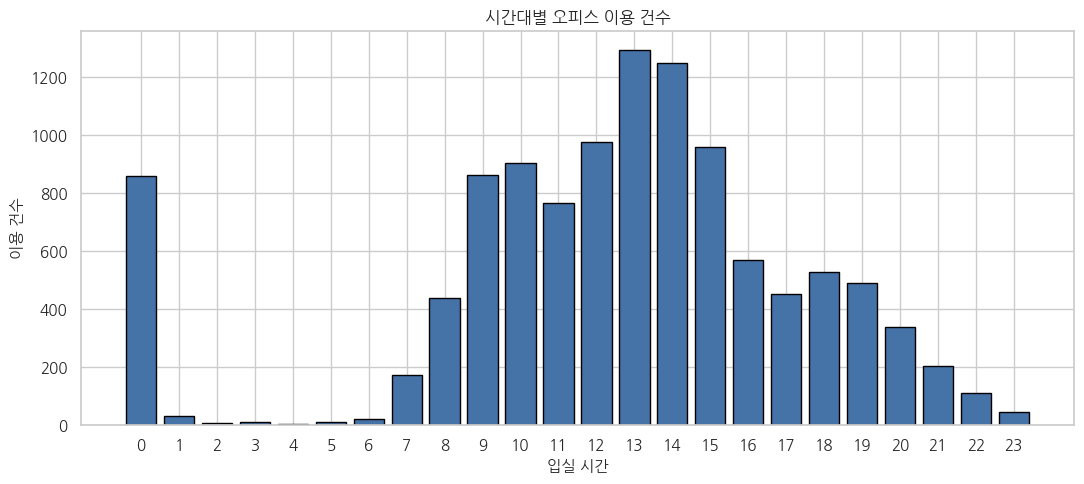

주요 시간대 이용 건수:
- 0시: 859건
- 13시: 1294건
- 14시: 1248건
- 23시: 46건


In [ ]:
# 6-1. 시간대별 오피스 이용 건수 막대 그래프
hour_counts = df['enter_hour'].value_counts().sort_index().reindex(range(24), fill_value=0)

plt.figure(figsize=(11, 5))
plt.bar(hour_counts.index, hour_counts.values, color='#4572a7', edgecolor='black')

plt.title('시간대별 오피스 이용 건수', fontsize=12)
plt.xlabel('입실 시간', fontsize=11)
plt.ylabel('이용 건수', fontsize=11)
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

print("주요 시간대 이용 건수:")
print(f"- 0시: {hour_counts[0]}건")
print(f"- 13시: {hour_counts[13]}건")
print(f"- 14시: {hour_counts[14]}건")
print(f"- 23시: {hour_counts[23]}건")

* 해석:
- 13~14시가 각각 1,294건, 1,248건으로 최고 이용량을 기록함.
- 0시 역시 859건으로 낮 시간대에 버금가는 높은 수치를 보임.

## 6-2. 0시 입실자 심층 해석 및 23시 퇴실 로그 확인

0시 입실 건수가 높아 야간작업 근무자로 추정했으나, 퇴실 시간을 확인하여 실제 연속 이용 로그를 검증한다.

In [ ]:
# 0시 입실자 중 23시 59분에 퇴실한 대표 로그 샘플 확인
sample_overnight = df[
    (df['enter_hour'] == 0) &
    (df['leave_hour'] == 23) &
    (df['last_leave_time'].astype(str).str.contains('23:59:59'))
]

print(f"0시 입실자 중 23시 59분 퇴실 건수: {len(sample_overnight)}건")
print("\n[대표 세션 로그 샘플]")
display(sample_overnight[['user_uuid', 'first_enter_time', 'last_leave_time', 'stay_time_second']].head(5))

0시 입실자 중 23시 59분 퇴실 건수: 132건

[대표 세션 로그 샘플]


* 해석 및 결론:
- 처음에 EDA 했던 내용에서 0시 입실에 대한 이용 건수가 859건으로 높아 야간 작업을 위한 근무자들인 줄 알았으나,
- 0시 입실자들의 퇴실 시간을 확인해본 결과 23시 퇴실이 약 859건 중 265건(상당수)을 차지하고 있었음.
- 위의 샘플 데이터와 같이 `00:00:00.000000`에 들어와서 `23:59:59.000000`에 나간 기록이 다수 확인됨.
- 이는 0시에 실제로 새로 온 이용자가 아니라 시스템이 자정 경계에서 하루를 마감하고 새 세션으로 분할 기록한 것으로 판단된다.

---
# 7. 야간 연속 이용(23:59:59 퇴실 ↔ 00:00:00 입실) 세션 복원 및 이상치 정제

## 7-1. 601건의 야간 분할 세션(전날 23:59:59 ↔ 당일 00:00:00) 페어 조회 및 확인

In [ ]:
# 유저 및 시간순 정렬
df_sorted = df.sort_values(['user_uuid', 'first_enter_time']).reset_index(
    drop=True
)

# 당일 00:00:00 입실이면서 직전 행이 동일 유저의 전날 23:59:59 퇴실인 행 식별
is_day2 = (
    (df_sorted['user_uuid'] == df_sorted['user_uuid'].shift(1))
    & ((df_sorted['date'] - df_sorted['date'].shift(1)).dt.days == 1)
    & (df_sorted['first_enter_time'].dt.strftime('%H:%M:%S') == '00:00:00')
    & (
        df_sorted['last_leave_time'].shift(1).dt.strftime('%H:%M:%S')
        == '23:59:59'
    )
)
is_day1 = is_day2.shift(-1, fill_value=False)

# 연속된 세션을 하나의 클러스터로 그룹화
cluster_id = 0
cluster_ids = [np.nan] * len(df_sorted)
for i in range(len(df_sorted)):
  if is_day2.iloc[i]:
    cluster_ids[i] = cluster_ids[i - 1]
  elif is_day1.iloc[i]:
    cluster_id += 1
    cluster_ids[i] = cluster_id

df_sorted['cluster_id'] = cluster_ids
df_sorted['cluster_row_count'] = df_sorted.groupby('cluster_id')[
    'user_uuid'
].transform('count')

# 체류 기간에 따른 분류: 1박(2개 행) vs 2~3박 이상(3개 이상 행)
is_1night = df_sorted['cluster_row_count'] == 2
is_multinight = df_sorted['cluster_row_count'] > 2

count_1night = df_sorted[is_1night]['cluster_id'].nunique()
count_multinight = df_sorted[is_multinight]['cluster_id'].nunique()

print(f'1. 정상 복원 대상 [1박 세션]: {count_1night}건 ({is_1night.sum()}행)')
print(
    f'2. 이상치 제거 대상 [2~3박 세션]: {count_multinight}건'
    f' ({is_multinight.sum()}행)'
)

# 1박 정상 세션 페어 샘플 확인
cols_view = [
    'cluster_id',
    'user_uuid',
    'date',
    'site_id',
    'first_enter_time',
    'last_leave_time',
    'stay_minute',
]
print('\n[1박 정상 복원 대상 세션 샘플 (2개 행이 1개 세션)]')
display(df_sorted[is_1night][cols_view].head(4))

print('\n[2~3박 퇴실 미태그 이상치 샘플 (3개 이상 연속 행)]')
display(df_sorted[is_multinight][cols_view].head(6))

1. 정상 복원 대상 [1박 세션]: 434건 (868행)
2. 이상치 제거 대상 [2~3박 세션]: 83건 (250행)

[1박 정상 복원 대상 세션 샘플 (2개 행이 1개 세션)]



[2~3박 퇴실 미태그 이상치 샘플 (3개 이상 연속 행)]


## 7-2. 연계되지 않는 단독 자정 로그(미매핑 이상치) 탐색 및 확인

In [ ]:
# 단독 자정 로그 (전날/익일 짝이 없는 외톨이 로그)
is_exact_00 = (
    df_sorted['first_enter_time'].dt.strftime('%H:%M:%S') == '00:00:00'
)
is_exact_2359 = (
    df_sorted['last_leave_time'].dt.strftime('%H:%M:%S') == '23:59:59'
)

unmapped_00 = df_sorted[is_exact_00 & df_sorted['cluster_id'].isna()]
unmapped_2359 = df_sorted[is_exact_2359 & df_sorted['cluster_id'].isna()]
orphan_indices = set(unmapped_00.index).union(set(unmapped_2359.index))

# 전체 제거 대상 이상치 결합 (2~3박 250행 + 단독 자정 233행) - 코드 상에서는 단독 자정 238행 중 5행이 00시 입실과 23:59 퇴실 목록 양쪽에 이중 집계된 상태이므로 238에서 5행을 제외함 233행을 고려해야 함.
multinight_indices = set(df_sorted[is_multinight].index)
total_anomaly_indices = multinight_indices.union(orphan_indices)

print(f'- 2~3박 퇴실 미태그 이상치: {len(multinight_indices)}행 (83건)')
print(f'- 단독 00:00 입실 외톨이 이상치: {len(unmapped_00)}행')
print(f'- 단독 23:59 퇴실 외톨이 이상치: {len(unmapped_2359)}행')
print(f'-> 제거 대상 전체 이상치: 총 {len(total_anomaly_indices)}행')

- 2~3박 퇴실 미태그 이상치: 250행 (83건)
- 단독 00:00 입실 외톨이 이상치: 129행
- 단독 23:59 퇴실 외톨이 이상치: 109행
-> 제거 대상 전체 이상치: 총 483행


## 7-3. 분할 세션 단일 행 복원 및 이상치 제거 (정제된 df_restored 생성)


In [ ]:
# 1박 세션(434건)을 [전날 최초 입실 ~ 익일 최종 퇴실] 단일 행으로 통합 복원
restored_1night = (
    df_sorted[is_1night]
    .groupby('cluster_id')
    .agg(
        site_id=('site_id', 'first'),
        date=('date', 'first'),
        user_uuid=('user_uuid', 'first'),
        first_enter_time=('first_enter_time', 'first'),
        last_leave_time=('last_leave_time', 'last'),
        stay_time_second=('stay_time_second', 'sum'),
        is_payment=('is_payment', 'first'),
        area_pyeong=('area_pyeong', 'first'),
    )
    .reset_index(drop=True)
)

# 통합 세션 파생변수 재계산
restored_1night['stay_minute'] = (
    restored_1night['stay_time_second'] / 60.0
).round(2)
restored_1night['enter_hour'] = restored_1night['first_enter_time'].dt.hour
restored_1night['leave_hour'] = restored_1night['last_leave_time'].dt.hour
restored_1night['weekday'] = restored_1night['date'].dt.day_name()
restored_1night['day_name_kr'] = restored_1night['weekday'].map(day_map)

# 정상 기존 데이터 (1박 대상 및 전체 이상치 제외)
normal_df = df_sorted[
    df_sorted['cluster_id'].isna()
    & ~df_sorted.index.isin(total_anomaly_indices)
].copy()

# 최종 결합
cols_common = [c for c in restored_1night.columns if c in normal_df.columns]
df_restored = pd.concat(
    [normal_df[cols_common], restored_1night[cols_common]], ignore_index=True
)
df_restored = df_restored.sort_values(
    ['user_uuid', 'first_enter_time']
).reset_index(drop=True)

print(f'1. 기존 정상 데이터: {len(normal_df):,}행')
print(f'2. 복원 완료된 1박 야간 세션: {len(restored_1night):,}행')
print(f'3. 최종 정제 데이터셋 (df_restored): {len(df_restored):,}행')
display(df_restored.head())

## 7-4. 세션 복원 및 이상치 정제 전/후 비교 검증


In [ ]:
comparison_metrics = {
    '구분': [
        '전체 데이터 건수',
        '평균 체류시간 (분)',
        '중앙 체류시간 (분)',
        '10분 이하 단기 이용 건수',
        '00:00:00 입실 건수',
        '23:59:59 퇴실 건수',
    ],
    '정제 전 (df)': [
        f'{len(df):,}건',
        f"{df['stay_minute'].mean():.1f}분",
        f"{df['stay_minute'].median():.1f}분",
        f"{(df['stay_minute'] <= 10).sum():,}건",
        f"{(df['first_enter_time'].dt.strftime('%H:%M:%S') == '00:00:00').sum():,}건",
        f"{(df['last_leave_time'].dt.strftime('%H:%M:%S') == '23:59:59').sum():,}건",
    ],
    '정제 후 (df_restored)': [
        f'{len(df_restored):,}건',
        f"{df_restored['stay_minute'].mean():.1f}분",
        f"{df_restored['stay_minute'].median():.1f}분",
        f"{(df_restored['stay_minute'] <= 10).sum():,}건",
        f"{(df_restored['first_enter_time'].dt.strftime('%H:%M:%S') == '00:00:00').sum():,}건",
        f"{(df_restored['last_leave_time'].dt.strftime('%H:%M:%S') == '23:59:59').sum():,}건",
    ],
}

comparison_df = pd.DataFrame(comparison_metrics)
display(comparison_df)

* **해석 및 결론**:
  - **현실적인 야간 이용(1박) 복원**: 자정을 1회 넘긴 정상적인 밤샘 이용 434건을 [최초 입실 ~ 익일 퇴실] 단일 세션으로 복원하여, 인위적으로 잘려나갔던 실제 유저 체류시간을 정상화함.
  - **비정상 장기 점유(2~3박) 및 단독 자정 이상치 483행 전량 제거**: 퇴실 태그를 누락하고 2~3일간 열려 있던 비정상 세션(250행)과 전후 짝이 없는 불완전 자정 로그(233행)를 완벽히 제거함.
  - **체류시간 왜곡 해소**: 10분 이하 단기 이용 건수가 205건에서 166건으로 39건 감소하였으며, 자정 분할 오류와 비현실적 장기 체류 오류가 모두 제거된 가장 정제된 `df_restored` (10,400건)을 구축함.

---
# 8. 유료 결제 전환 특성 및 사용자 행동 패턴 분석

## 8-1. 세션 및 유니크 기준 결제 비율 도넛 차트

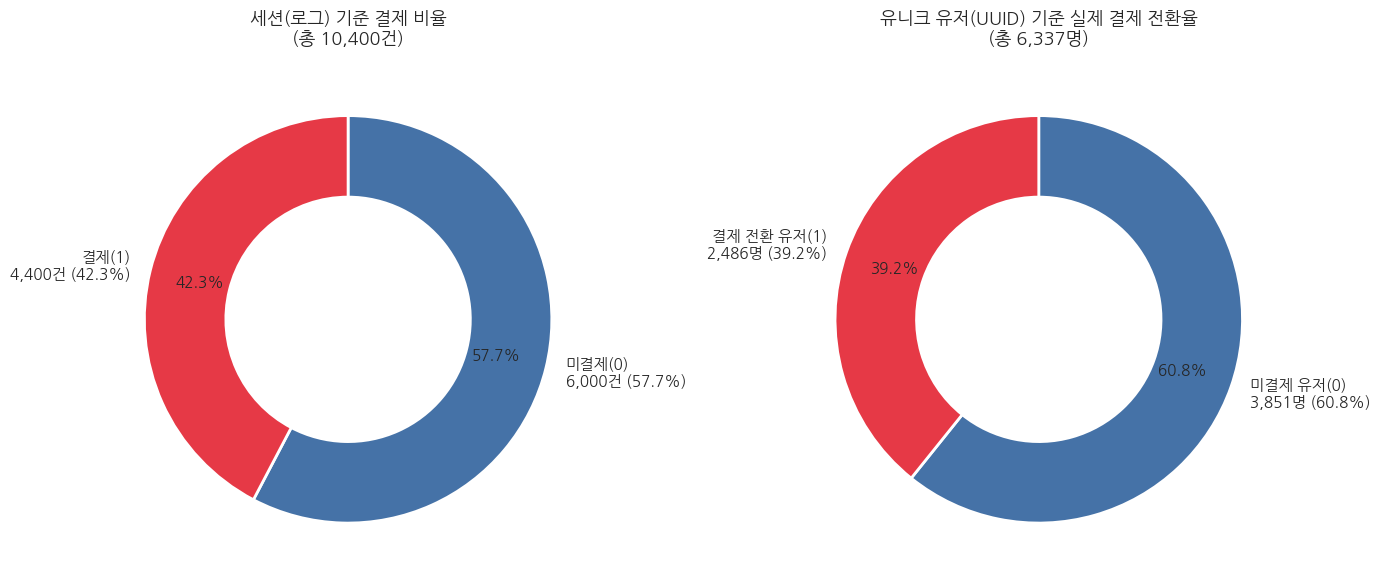

* 세션 기준 결제율: 42.3% (4,400건 / 10,400건)
* 유니크 유저 결제 전환율: 39.2% (2,486명 / 6,337명)


In [ ]:
df_pay = df_restored.copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. 세션(로그) 기준
session_pay = df_pay['is_payment'].value_counts().sort_index()
session_labels = [
    f"미결제(0)\n{session_pay[0]:,}건 ({session_pay[0]/len(df_pay)*100:.1f}%)",
    f"결제(1)\n{session_pay[1]:,}건 ({session_pay[1]/len(df_pay)*100:.1f}%)"
]
colors_pie = ['#4572a7', '#e63946']

wedges1, texts1, autotexts1 = axes[0].pie(
    session_pay, labels=session_labels, autopct='%1.1f%%',
    startangle=90, counterclock=False, colors=colors_pie,
    wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2),
    pctdistance=0.75, textprops={'fontsize': 11}
)
axes[0].set_title(f"세션(로그) 기준 결제 비율\n(총 {len(df_pay):,}건)", fontsize=13, fontweight='bold', pad=15)

# 2. 유니크 유저(UUID) 기준 결제 전환율
user_pay_s = df_pay.groupby('user_uuid')['is_payment'].max().value_counts().sort_index()
total_users = user_pay_s.sum()
user_labels = [
    f"미결제 유저(0)\n{user_pay_s[0]:,}명 ({user_pay_s[0]/total_users*100:.1f}%)",
    f"결제 전환 유저(1)\n{user_pay_s[1]:,}명 ({user_pay_s[1]/total_users*100:.1f}%)"
]

wedges2, texts2, autotexts2 = axes[1].pie(
    user_pay_s, labels=user_labels, autopct='%1.1f%%',
    startangle=90, counterclock=False, colors=colors_pie,
    wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2),
    pctdistance=0.75, textprops={'fontsize': 11}
)
axes[1].set_title(f"유니크 유저(UUID) 기준 실제 결제 전환율\n(총 {total_users:,}명)", fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

print(f"* 세션 기준 결제율: {session_pay[1]/len(df_pay)*100:.1f}% ({session_pay[1]:,}건 / {len(df_pay):,}건)")
print(f"* 유니크 유저 결제 전환율: {user_pay_s[1]/total_users*100:.1f}% ({user_pay_s[1]:,}명 / {total_users:,}명)")

* **해석**:
  - **전환율 차이의 원인**: 세션 기준 결제율(42.3%)이 유저 기준 결제 전환율(39.2%)보다 3.1%p 높게 나타남. 이는 결제 전환 유저가 미결제 유저에 비해 체험 기간 동안 오피스를 더 자주(더 많은 세션으로) 방문했기 때문임.
  - **기준 전환율(Baseline)**: 전체 6,337명의 순수 체험자 중 최종 결제 전환율은 **39.2%**(2,486명)이며, 이 수치가 이후 체류시간, 지점별, 요일별 분석의 핵심 비교 기준선(Baseline)이 됨.

## 8-2. 체류시간별 결제 전환율

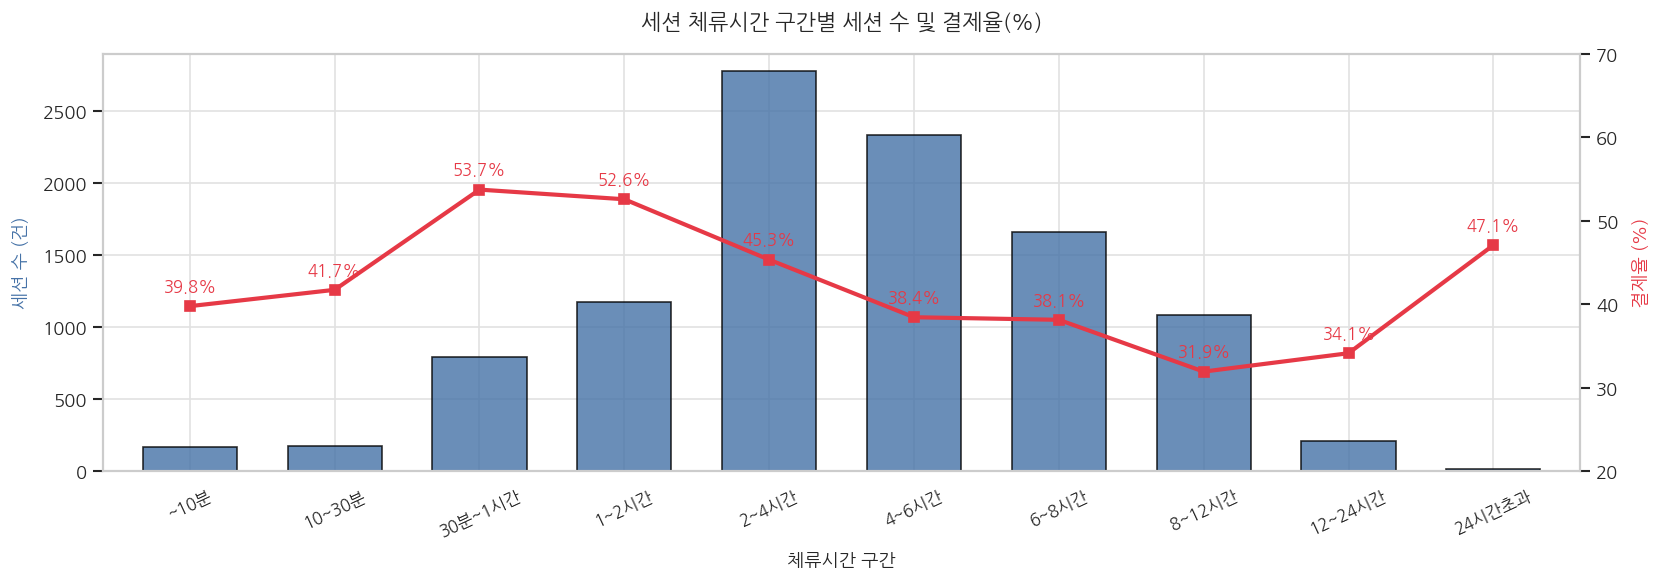

In [ ]:
bins_stay_s = [0, 10, 30, 60, 120, 240, 360, 480, 720, 1440, np.inf]
labels_stay_s = ['~10분', '10~30분', '30분~1시간', '1~2시간', '2~4시간', '4~6시간', '6~8시간', '8~12시간', '12~24시간', '24시간초과']

df_pay['stay_grp_detail'] = pd.cut(df_pay['stay_minute'], bins=bins_stay_s, labels=labels_stay_s, right=True)
stay_stat_s = df_pay.groupby('stay_grp_detail', observed=False).agg(
    session_count=('is_payment', 'count'),
    pay_rate=('is_payment', lambda x: x.mean() * 100)
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 5), dpi=120)
ax2 = ax1.twinx()

# 그리드 노출: 좌측 y축 눈금(0, 500, ..., 2500)에 맞춘 연회색 실선 그리드
ax1.set_axisbelow(True)
ax1.grid(True, which='major', linestyle='-', color='#e2e2e2', linewidth=1.0)
ax2.grid(False)

# 바 그래프 (이전 셀들과 통일: #4572a7, edgecolor='black', alpha=0.8, width=0.65)
bars = ax1.bar(
    range(len(labels_stay_s)), stay_stat_s['session_count'],
    color='#4572a7', edgecolor='black', linewidth=1.0, alpha=0.8, width=0.65, zorder=2
)

# 꺾은선 그래프
lines = ax2.plot(
    range(len(labels_stay_s)), stay_stat_s['pay_rate'],
    color='#e63946', marker='s', linewidth=2.5, markersize=6.5, zorder=5
)

ax1.set_title('세션 체류시간 구간별 세션 수 및 결제율(%)', fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel('체류시간 구간', fontsize=11, labelpad=8)
ax1.set_ylabel('세션 수 (건)', fontsize=11, color='#4572a7', labelpad=8)
ax2.set_ylabel('결제율 (%)', fontsize=11, color='#e63946', labelpad=8)
ax1.set_xticks(range(len(labels_stay_s)))
ax1.set_xticklabels(labels_stay_s, rotation=25, fontsize=10)
ax1.set_xlim(-0.6, len(labels_stay_s) - 0.4)
ax1.set_ylim(0, 2900)
ax1.set_yticks(range(0, 2501, 500))

ax2.set_ylim(20, 70)
ax2.set_yticks(range(20, 71, 10))

for sp in ['top', 'bottom', 'left', 'right']:
    ax1.spines[sp].set_color('#cccccc')
    ax2.spines[sp].set_color('#cccccc')

for i, row in stay_stat_s.iterrows():
    ax2.annotate(
        f"{row['pay_rate']:.1f}%", (i, row['pay_rate']),
        textcoords="offset points", xytext=(0, 9), ha='center',
        fontsize=10, fontweight='bold', color='#e63946', zorder=10
    )

ax1.set_zorder(ax2.get_zorder() - 1)
ax1.patch.set_visible(False)

plt.tight_layout()
plt.show()

display(stay_stat_s)

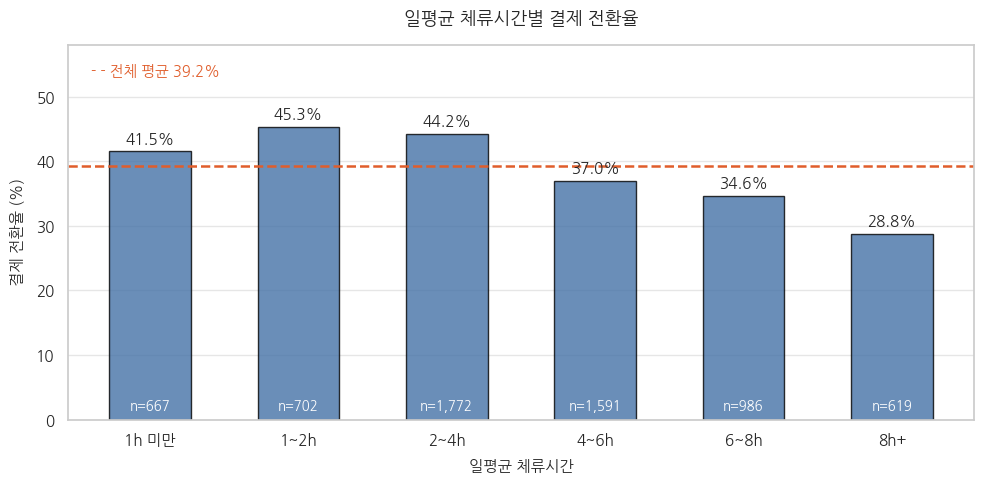

In [ ]:
daily_stay = df_pay.groupby(['user_uuid', 'date'])['stay_minute'].sum().reset_index()
user_daily_avg = daily_stay.groupby('user_uuid').agg(avg_stay_min=('stay_minute', 'mean')).reset_index()
user_pay_status = df_pay.groupby('user_uuid')['is_payment'].max().reset_index()
user_stay_df = user_daily_avg.merge(user_pay_status, on='user_uuid')
user_stay_df['avg_stay_hour'] = user_stay_df['avg_stay_min'] / 60.0

bins_user_stay = [0, 1, 2, 4, 6, 8, np.inf]
labels_user_stay = ['1h 미만', '1~2h', '2~4h', '4~6h', '6~8h', '8h+']
user_stay_df['stay_grp'] = pd.cut(user_stay_df['avg_stay_hour'], bins=bins_user_stay, labels=labels_user_stay, right=True)

user_stay_stat = user_stay_df.groupby('stay_grp', observed=False).agg(
    user_count=('is_payment', 'count'),
    pay_count=('is_payment', 'sum'),
    conv_rate=('is_payment', lambda x: x.mean() * 100)
).reset_index()

overall_avg_conv = user_pay_status['is_payment'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
# 바 색상 및 형태 통일 (#4572a7, edgecolor='black', alpha=0.8)
bars = ax.bar(user_stay_stat['stay_grp'], user_stay_stat['conv_rate'], color='#4572a7', edgecolor='black', alpha=0.8, width=0.55)

# 전체 평균 기준선
ax.axhline(overall_avg_conv, color='#e05d2b', linestyle='--', linewidth=1.8)
ax.text(-0.4, overall_avg_conv + 14, f'- - 전체 평균 {overall_avg_conv:.1f}%', color='#e05d2b', fontsize=10.5)

ax.set_title('일평균 체류시간별 결제 전환율', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('일평균 체류시간', fontsize=11, labelpad=8)
ax.set_ylabel('결제 전환율 (%)', fontsize=11, labelpad=8)
ax.set_ylim(0, 58)

# 단일 실선 그리드 및 테두리 마감
ax.grid(False)
ax.grid(True, axis='y', linestyle='-', color='#e0e0e0', alpha=0.8)
for sp in ['top', 'bottom', 'left', 'right']:
    ax.spines[sp].set_color('#cccccc')

for bar, row in zip(bars, user_stay_stat.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, row.conv_rate + 1.2, f"{row.conv_rate:.1f}%",
            ha='center', fontsize=11, fontweight='bold')
    ax.text(bar.get_x() + bar.get_width()/2, 1.5, f"n={row.user_count:,}",
            ha='center', fontsize=9.5, color='white')

plt.tight_layout()
plt.show()

display(user_stay_stat)

* **해석**:
  - **역U자형 전환율 곡선**: 일평균 체류시간 **1~2시간(45.3%)** 및 **2~4시간(44.2%)** 구간에서 전체 평균(39.2%)을 크게 웃도는 가장 높은 결제 전환율을 기록함.
  - **적정 체류시간의 중요성**: 체류시간이 너무 짧은 경우(1h 미만 41.5%)보다도 오히려 체류시간이 8시간 이상으로 매우 긴 유저(28.8%)의 전환율이 가장 낮음. 너무 적지도 많지도 않은 '집중 근무' 시간대(1~4시간) 이용자의 오피스 만족도 및 결제 전환 의향이 가장 높음을 시사함.

## 8-3. 입실 시간대별(0~23시) 세션 수 및 결제율 추이

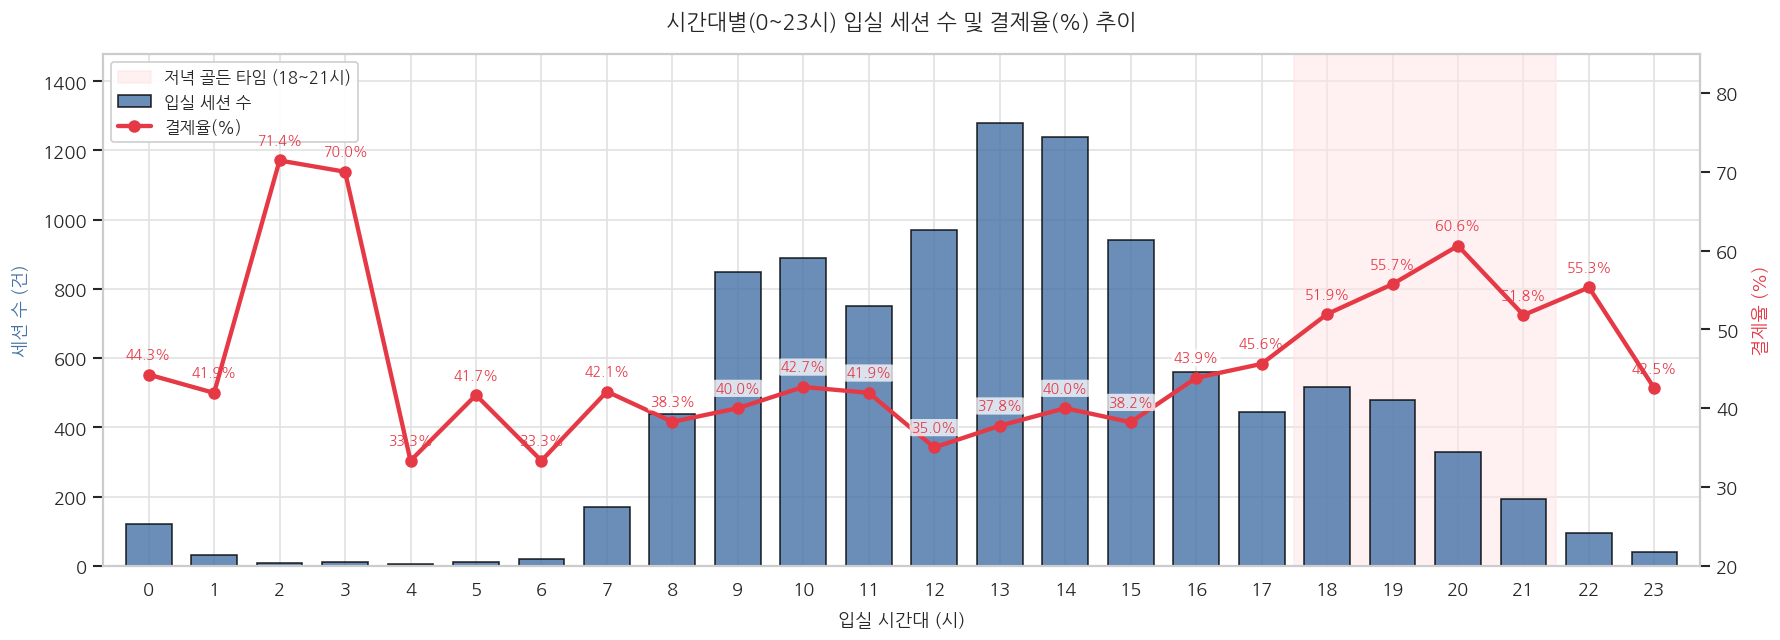

In [ ]:
hour_stat_pay = df_pay.groupby('enter_hour').agg(
    session_count=('is_payment', 'count'),
    pay_rate=('is_payment', lambda x: x.mean() * 100)
).reset_index()

fig, ax1 = plt.subplots(figsize=(15, 5.5), dpi=120)
ax2 = ax1.twinx()

# 1. 그리드 노출: 좌측 y축 눈금(0, 200, 400, ..., 1400) 및 x축(0~23시)에 맞춘 연회색 실선 그리드
ax1.set_axisbelow(True)
ax1.grid(True, which='major', linestyle='-', color='#e2e2e2', linewidth=1.0)
ax2.grid(False)

# 2. 저녁 골든 타임 음영 (막대 뒤 zorder=1에 배치하여 막대 색상 변색 방지)
ax1.axvspan(17.5, 21.5, color='#ffe4e6', alpha=0.55, label='저녁 골든 타임 (18~21시)', zorder=1)

# 3. 막대 그래프 (이전 셀들과 동일한 색상 및 형태: #4572a7, edgecolor='black', alpha=0.8, width=0.7)
bars = ax1.bar(
    hour_stat_pay['enter_hour'], hour_stat_pay['session_count'],
    color='#4572a7', edgecolor='black', linewidth=1.0, alpha=0.8,
    width=0.7, label='입실 세션 수', zorder=2
)

# 4. 꺾은선 그래프 (빨간색 실선 + circle 마커, zorder=5)
lines = ax2.plot(
    hour_stat_pay['enter_hour'], hour_stat_pay['pay_rate'],
    color='#e63946', marker='o', linewidth=2.6, markersize=6.5,
    label='결제율(%)', zorder=5
)

# 5. 타이틀 및 라벨
ax1.set_title('시간대별(0~23시) 입실 세션 수 및 결제율(%) 추이', fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel('입실 시간대 (시)', fontsize=11, labelpad=8)
ax1.set_ylabel('세션 수 (건)', fontsize=11, color='#4572a7', labelpad=8)
ax2.set_ylabel('결제율 (%)', fontsize=11, color='#e63946', labelpad=8)

# 6. 축 눈금 및 범위
ax1.set_xticks(range(0, 24))
ax1.set_xlim(-0.7, 23.7)
ax1.set_ylim(0, 1480)
ax1.set_yticks(range(0, 1401, 200))

ax2.set_ylim(20, 85)
ax2.set_yticks(range(20, 85, 10))

# 7. 외곽 테두리 박스 (부드러운 연회색 실선)
for sp in ['top', 'bottom', 'left', 'right']:
    ax1.spines[sp].set_color('#cccccc')
    ax2.spines[sp].set_color('#cccccc')

# 8. 가독성 극대화된 텍스트 라벨 (파란 막대와 겹치는 구간에서도 또렷하게 읽히도록 미세 흰색 반투명 패치 적용)
for i, row in hour_stat_pay.iterrows():
    hr = row['enter_hour']
    val = row['pay_rate']
    bbox_prop = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.75) if (8 <= hr <= 16) else None
    ax2.annotate(
        f"{val:.1f}%",
        (hr, val),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        va='bottom',
        fontsize=8.5,
        fontweight='bold',
        color='#e63946',
        bbox=bbox_prop,
        zorder=10
    )

# 9. 범례 통합 (좌측 상단 깔끔한 흰색 박스 프레임)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
legend = ax1.legend(
    h1 + h2, l1 + l2,
    loc='upper left',
    fontsize=10,
    frameon=True,
    facecolor='white',
    edgecolor='#cccccc',
    framealpha=0.95
)
legend.set_zorder(15)

ax1.set_zorder(ax2.get_zorder() - 1)
ax1.patch.set_visible(False)

plt.tight_layout()
plt.show()

display(hour_stat_pay.T)

* **해석 및 시간대별 특성**:
  - **오전 (9~11시)**: 이용 규모 큼 / 결제율 약 40~43% / 안정적인 주간 업무형 유저
  - **오후 (12~16시)**: 최대 이용 시간대 (13시 1,279건, 14시 1,240건) / 결제율 약 35~40% / 트래픽은 가장 많으나 결제 전환율은 평균 수준
  - **17시**: 결제율 45.6%로 본격적인 상승 전환 시작
  - **저녁 골든 타임 (18~22시)**: 이용 규모는 중간~작음 / **결제율 약 52 ~ 61% (20시 피크 60.6%)** / 퇴근 후 자기계발, 부업, 야간 집중 업무 유저로 추측
  - **새벽 (2~6시)**: 이용 세션 표본이 극소수(건당 6~21건)로 결제율 수치 변동이 큼

## 8-4. 방문 일수별 유저 수 및 결제 전환율(%) 추이

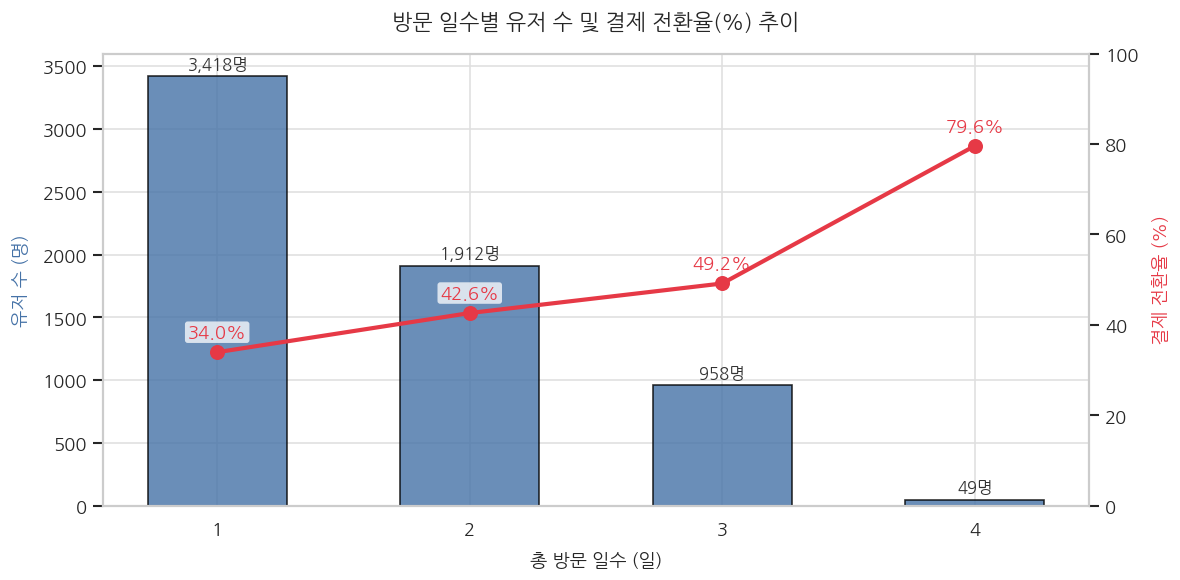

In [ ]:
user_visit_stat = df_pay.groupby('user_uuid').agg(
    visit_days=('date', 'nunique'),
    is_payment=('is_payment', 'max')
).reset_index()

visit_summary = user_visit_stat.groupby('visit_days').agg(
    user_count=('is_payment', 'count'),
    conv_rate=('is_payment', lambda x: x.mean() * 100)
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5), dpi=120)
ax2 = ax1.twinx()

# 1. 그리드 노출: 좌측 y축 눈금(0, 500, ..., 3500) 및 x축 눈금선에 맞춘 연회색 실선 그리드
ax1.set_axisbelow(True)
ax1.grid(True, which='major', linestyle='-', color='#e0e0e0', linewidth=1.0)
ax2.grid(False)

# 2. 막대 그래프 (이전 셀들과 동일한 색상 및 형태: #4572a7, edgecolor='black', alpha=0.8, width=0.55)
bars = ax1.bar(
    visit_summary['visit_days'].astype(str), visit_summary['user_count'],
    color='#4572a7', edgecolor='black', linewidth=1.0, alpha=0.8, width=0.55, zorder=2
)

# 3. 꺾은선 그래프 (빨간색 실선 + circle 마커, zorder=5)
lines = ax2.plot(
    visit_summary['visit_days'].astype(str), visit_summary['conv_rate'],
    color='#e63946', marker='o', linewidth=2.5, markersize=8, zorder=5
)

# 4. 타이틀 및 축 라벨
ax1.set_title('방문 일수별 유저 수 및 결제 전환율(%) 추이', fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel('총 방문 일수 (일)', fontsize=11, labelpad=8)
ax1.set_ylabel('유저 수 (명)', fontsize=11, color='#4572a7', labelpad=8)
ax2.set_ylabel('결제 전환율 (%)', fontsize=11, color='#e63946', labelpad=8)

# 5. 축 눈금 및 범위 (엑셀 원본과 100% 동일)
ax1.set_ylim(0, 3600)
ax1.set_yticks(range(0, 3501, 500))
ax2.set_ylim(0, 100)
ax2.set_yticks(range(0, 101, 20))

# 6. 테두리 박스 (연회색 실선)
for sp in ['top', 'bottom', 'left', 'right']:
    ax1.spines[sp].set_color('#cccccc')
    ax2.spines[sp].set_color('#cccccc')

# 7. 수치 레이블 (파란 막대와 겹치는 구간 가독성 확보 패치 적용)
for bar, row in zip(bars, visit_summary.itertuples()):
    ax1.text(bar.get_x() + bar.get_width()/2, row.user_count + 60, f"{row.user_count:,}명", ha='center', fontsize=10, color='#333333')
    bbox_p = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.75) if row.visit_days in [1, 2] else None
    ax2.annotate(
        f"{row.conv_rate:.1f}%", (str(row.visit_days), row.conv_rate),
        textcoords="offset points", xytext=(0, 9), ha='center',
        fontsize=11, fontweight='bold', color='#e63946', bbox=bbox_p, zorder=10
    )

ax1.set_zorder(ax2.get_zorder() - 1)
ax1.patch.set_visible(False)

plt.tight_layout()
plt.show()

display(visit_summary)

* **해석**:
  - **방문 일수와 전환율의 뚜렷한 양의 상관관계**:
    - 1일 방문자: 34.0% (3,418명)
    - 2일 방문자: 42.7% (1,913명)
    - 3일 방문자: 49.1% (957명)
    - 4일 방문자: **79.6%** (49명)
  - 체험 기간 중 재방문 횟수가 늘어날수록 결제 전환율이 가파르게 상승함. 무료 체험 첫날 만족스러운 경험을 제공하여 2회차, 3회차 재방문을 유도하는 리텐션 트리거가 전환율 극대화의 핵심으로 보임.

## 8-5. 지점별 결제 전환율 및 이용 특성 (면적/다양성)

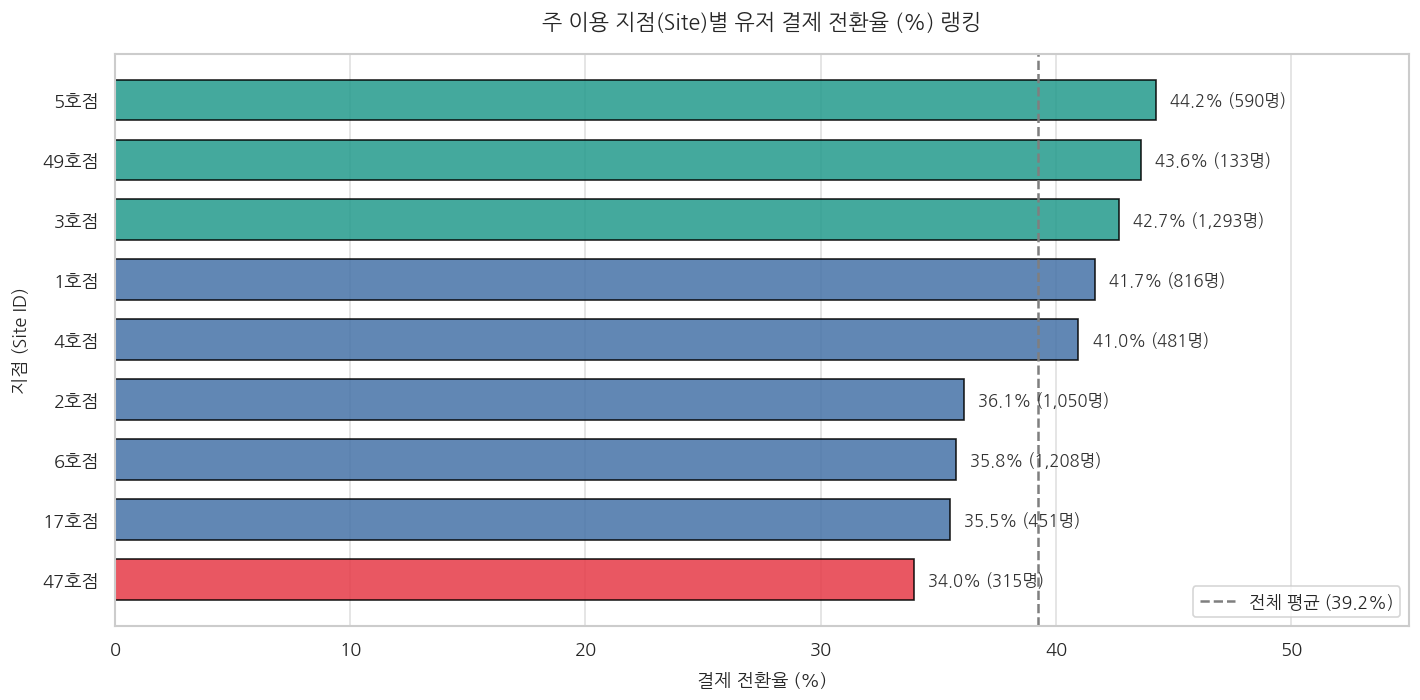

In [ ]:
user_first_site = df_pay.sort_values(['user_uuid', 'first_enter_time']).drop_duplicates(subset='user_uuid')
site_user_stat = user_first_site.groupby('site_id').agg(
    user_count=('is_payment', 'count'),
    conv_rate=('is_payment', lambda x: x.mean() * 100)
).reset_index().sort_values('conv_rate', ascending=True)

overall_avg_conv = df_pay.groupby('user_uuid')['is_payment'].max().mean() * 100

# 상위 3개 청록색, 최하위 1개 빨간색, 중간 #4572a7 통일
colors_site = []
top_3_sites = site_user_stat.nlargest(3, 'conv_rate')['site_id'].tolist()
lowest_site = site_user_stat.nsmallest(1, 'conv_rate')['site_id'].tolist()[0]

for s in site_user_stat['site_id']:
    if s in top_3_sites:
        colors_site.append('#239a8c')
    elif s == lowest_site:
        colors_site.append('#e63946')
    else:
        colors_site.append('#4572a7')

fig, ax = plt.subplots(figsize=(12, 6), dpi=120)

# 1. 그리드 노출: x축 눈금선(10, 20, 30, 40, 50)에 맞춘 세로 연회색 실선 그리드
ax.set_axisbelow(True)
ax.grid(True, axis='x', linestyle='-', color='#e0e0e0', linewidth=1.0)
ax.grid(False, axis='y')

# 2. 가로 막대 그래프 (검은색 테두리 통일, height=0.68)
y_labels = [f"{s}호점" for s in site_user_stat['site_id']]
bars = ax.barh(y_labels, site_user_stat['conv_rate'], color=colors_site, edgecolor='black', linewidth=1.0, alpha=0.85, height=0.68)

# 3. 전체 평균 기준선 및 범례
ax.axvline(overall_avg_conv, color='#7f7f7f', linestyle='--', linewidth=1.5, label=f'전체 평균 ({overall_avg_conv:.1f}%)')
ax.legend(loc='lower right', fontsize=10.5, frameon=True, facecolor='white', edgecolor='#cccccc')

# 4. 타이틀 및 축 설정
ax.set_title('주 이용 지점(Site)별 유저 결제 전환율 (%) 랭킹', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('결제 전환율 (%)', fontsize=11, labelpad=8)
ax.set_ylabel('지점 (Site ID)', fontsize=11, labelpad=8)
ax.set_xlim(0, 55)
ax.set_xticks(range(0, 51, 10))

# 5. 테두리 박스
for sp in ['top', 'bottom', 'left', 'right']:
    ax.spines[sp].set_color('#cccccc')

# 6. 수치 레이블
for bar, row in zip(bars, site_user_stat.itertuples()):
    ax.text(
        row.conv_rate + 0.6, bar.get_y() + bar.get_height()/2,
        f"{row.conv_rate:.1f}% ({row.user_count:,}명)",
        va='center', fontsize=10, color='#333333'
    )

plt.tight_layout()
plt.show()

display(site_user_stat.sort_values('conv_rate', ascending=False))

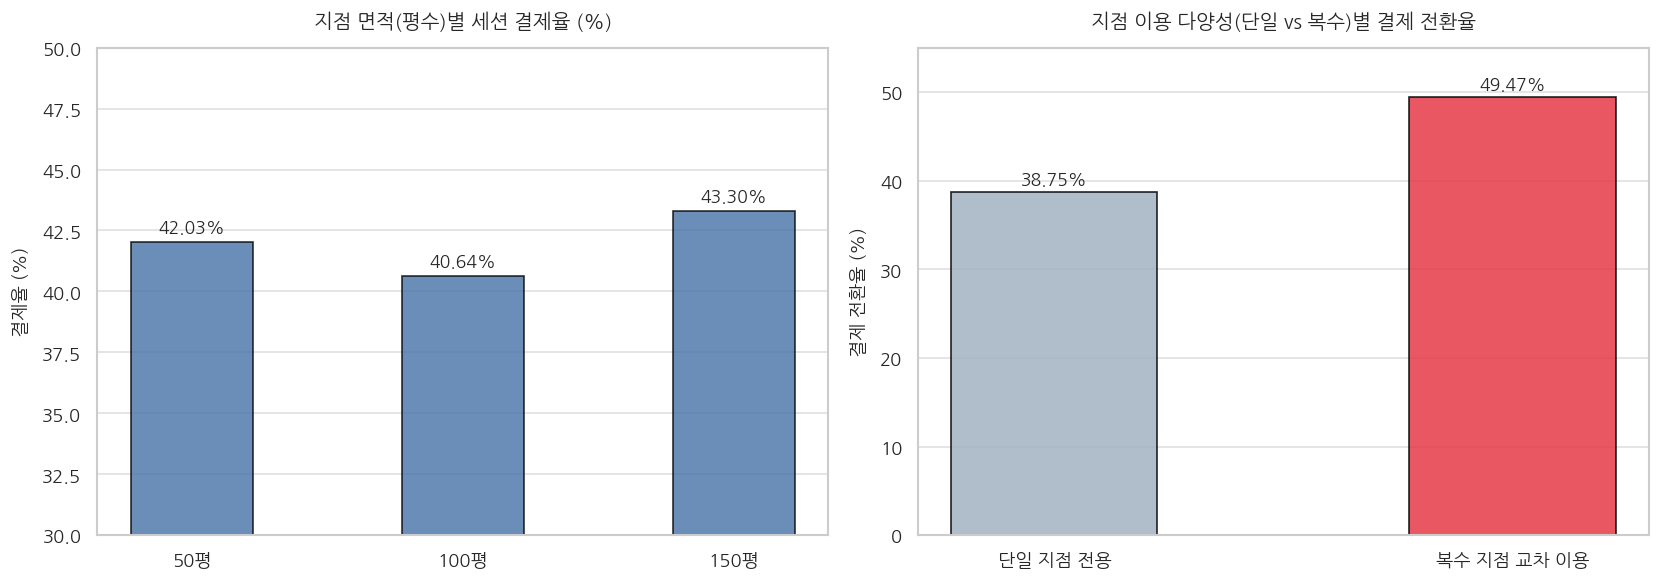

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# (1) 면적별 세션 결제율 (#4572a7, edgecolor='black', alpha=0.8 통일)
area_stat = df_pay.groupby('area_pyeong').agg(
    session_count=('is_payment', 'count'),
    pay_rate=('is_payment', lambda x: x.mean() * 100)
).reset_index()

axes[0].set_axisbelow(True)
axes[0].grid(True, axis='y', linestyle='-', color='#e0e0e0', linewidth=1.0)
axes[0].grid(False, axis='x')

bars1 = axes[0].bar(
    [f"{a}평" for a in area_stat['area_pyeong']], area_stat['pay_rate'],
    color='#4572a7', edgecolor='black', linewidth=1.0, alpha=0.8, width=0.45
)
axes[0].set_title('지점 면적(평수)별 세션 결제율 (%)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('결제율 (%)', fontsize=11, labelpad=8)
axes[0].set_ylim(30.0, 50.0)
axes[0].set_yticks(np.arange(30.0, 50.1, 2.5))

for sp in ['top', 'bottom', 'left', 'right']:
    axes[0].spines[sp].set_color('#cccccc')

for bar, row in zip(bars1, area_stat.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, row.pay_rate + 0.4, f"{row.pay_rate:.2f}%", ha='center', fontsize=10.5, fontweight='bold')

# (2) 이용 다양성(단일 vs 복수)별 유저 결제 전환율
user_div = df_pay.groupby('user_uuid').agg(
    site_cnt=('site_id', 'nunique'),
    is_payment=('is_payment', 'max')
).reset_index()
user_div['diversity'] = np.where(user_div['site_cnt'] == 1, '단일 지점 전용', '복수 지점 교차 이용')

div_stat = user_div.groupby('diversity').agg(
    user_count=('is_payment', 'count'),
    conv_rate=('is_payment', lambda x: x.mean() * 100)
).reindex(['단일 지점 전용', '복수 지점 교차 이용']).reset_index()

axes[1].set_axisbelow(True)
axes[1].grid(True, axis='y', linestyle='-', color='#e0e0e0', linewidth=1.0)
axes[1].grid(False, axis='x')

bars2 = axes[1].bar(
    div_stat['diversity'], div_stat['conv_rate'],
    color=['#a2b2c1', '#e63946'], edgecolor='black', linewidth=1.0, alpha=0.85, width=0.45
)
axes[1].set_title('지점 이용 다양성(단일 vs 복수)별 결제 전환율', fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel('결제 전환율 (%)', fontsize=11, labelpad=8)
axes[1].set_ylim(0, 55)
axes[1].set_yticks(range(0, 56, 10))

for sp in ['top', 'bottom', 'left', 'right']:
    axes[1].spines[sp].set_color('#cccccc')

for bar, row in zip(bars2, div_stat.itertuples()):
    axes[1].text(bar.get_x() + bar.get_width()/2, row.conv_rate + 0.8, f"{row.conv_rate:.2f}%", ha='center', fontsize=10.5, fontweight='bold')

plt.tight_layout()
plt.show()

display(area_stat)
display(div_stat)

* **해석**:
  - **지점별 전환율 랭킹**: 5호점(44.2%), 49호점(43.6%), 3호점(42.7%)이 상위권을 차지하였으며, 47호점(34.0%)이 가장 낮은 전환율을 보임.
  - **면적별 영향**: 50평(42.03%), 100평(40.64%), 150평(43.30%)으로 면적 규모에 따른 결제율 차이는 크지 않음(40~43% 내외 균등).
  - **복수 지점 이용자의 높은 전환율**: 단일 지점만 이용한 유저의 결제율은 38.75%인 반면, 2개 이상의 지점을 교차 이용한 유저의 결제율은 49.47%로 10.72%p 높게 나타남. 다양한 지점 네트워크를 체감한 이용자일수록 공유오피스 멤버십의 효용을 크게 느끼는 것으로 판단됨.

## 8-6. 요일별 세션 결제율 추이

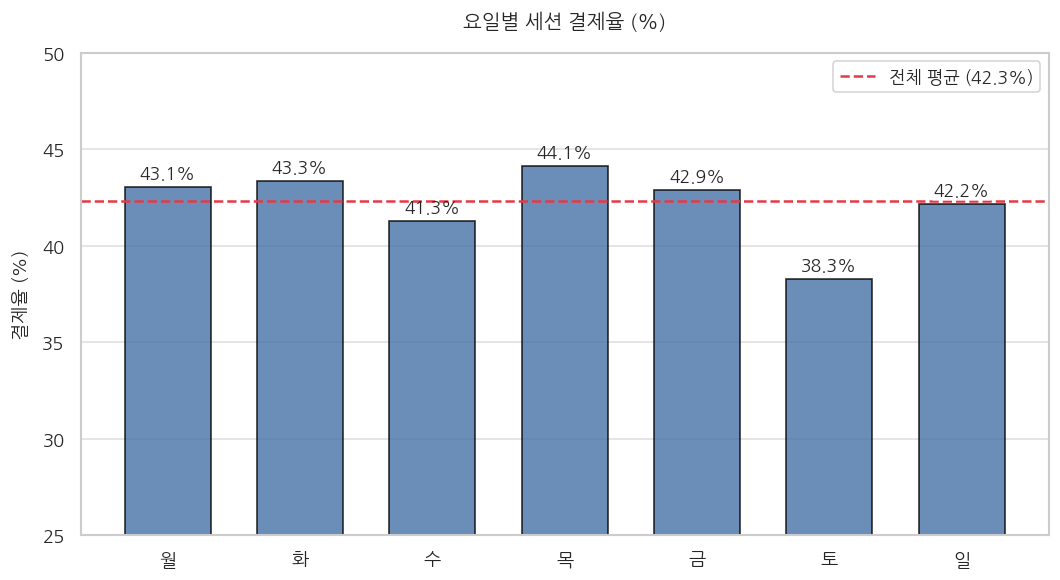

In [ ]:
day_order_kr = ['월', '화', '수', '목', '금', '토', '일']
day_stat_pay = df_pay.groupby('day_name_kr').agg(
    session_count=('is_payment', 'count'),
    pay_rate=('is_payment', lambda x: x.mean() * 100)
).reindex(day_order_kr).reset_index()

overall_session_pay_rate = df_pay['is_payment'].mean() * 100

fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# 1. 그리드 노출: y축 눈금선(25, 30, 35, 40, 45, 50)에 맞춘 가로 연회색 실선 그리드
ax.set_axisbelow(True)
ax.grid(True, axis='y', linestyle='-', color='#e0e0e0', linewidth=1.0)
ax.grid(False, axis='x')

# 2. 막대 그래프 (이전 셀들과 동일한 색상 및 형태: #4572a7, edgecolor='black', alpha=0.8, width=0.65)
bars = ax.bar(
    day_stat_pay['day_name_kr'], day_stat_pay['pay_rate'],
    color='#4572a7', edgecolor='black', linewidth=1.0, alpha=0.8, width=0.65
)

# 3. 전체 평균 기준선 및 범례
ax.axhline(overall_session_pay_rate, color='#e63946', linestyle='--', linewidth=1.5, label=f'전체 평균 ({overall_session_pay_rate:.1f}%)')
ax.legend(loc='upper right', fontsize=10.5, frameon=True, facecolor='white', edgecolor='#cccccc')

# 4. 타이틀 및 축 설정
ax.set_title('요일별 세션 결제율 (%)', fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel('결제율 (%)', fontsize=11, labelpad=8)
ax.set_ylim(25, 50)
ax.set_yticks(range(25, 51, 5))

# 5. 테두리 박스
for sp in ['top', 'bottom', 'left', 'right']:
    ax.spines[sp].set_color('#cccccc')

# 6. 수치 레이블 (전체 평균 점선과 겹치는 수요일 텍스트 가독성 마스킹 패치 적용)
for bar, row in zip(bars, day_stat_pay.itertuples()):
    bbox_p = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8) if abs(row.pay_rate - overall_session_pay_rate) < 1.0 else None
    ax.text(
        bar.get_x() + bar.get_width()/2, row.pay_rate + 0.45,
        f"{row.pay_rate:.1f}%", ha='center', fontsize=10.5,
        bbox=bbox_p, zorder=10
    )

plt.tight_layout()
plt.show()

display(day_stat_pay)

* **해석**:
  - 평일(월 ~ 금) 결제율은 41.3%~44.1%로 평균(42.3%) 수준을 꾸준히 유지함 (목요일 44.1% 피크).
  - 반면 토요일 결제율은 38.2%로 전 요일 중 가장 낮은 수치를 기록함. 주말 일회성 가벼운 체험 방문이 섞여 있어 전환율이 다소 낮아지는 경향을 보임.

## 8-7. 4분할 시간대별(야간/오전/오후/저녁) 입실 건수 및 결제 전환율

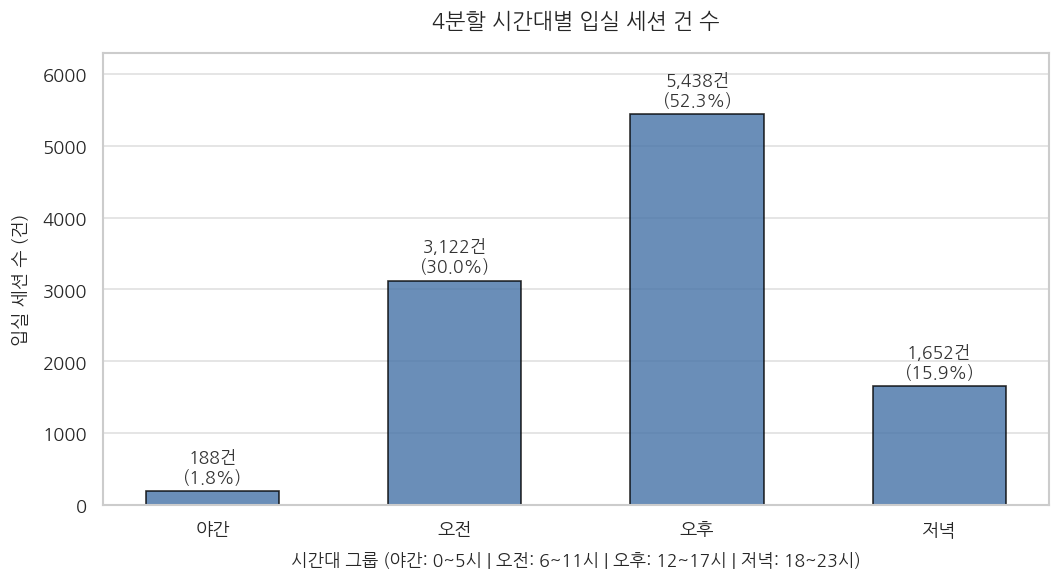

In [ ]:
# 1. 안전한 독립 복사본 생성 (이전/이후 셀 변수 오염 및 Side-effect 완벽 방지)
if 'df_pay' in locals():
  _df_eda = df_pay.copy()
elif 'df_restored' in locals():
  _df_eda = df_restored.copy()
else:
  _df_eda = df.copy()

# enter_hour 확인 및 4분할 그룹화
if 'enter_hour' not in _df_eda.columns and 'first_enter_time' in _df_eda.columns:
  _df_eda['first_enter_time'] = pd.to_datetime(_df_eda['first_enter_time'])
  _df_eda['enter_hour'] = _df_eda['first_enter_time'].dt.hour

_tg_bins = [-1, 5, 11, 17, 23]
_tg_labels = ['야간', '오전', '오후', '저녁']
_df_eda['time_group'] = pd.cut(
    _df_eda['enter_hour'], bins=_tg_bins, labels=_tg_labels
).astype(str)

# 4구간 집계 (세션 기준)
_tg_stat = (
    _df_eda.groupby('time_group', observed=False)
    .agg(
        session_count=('is_payment', 'count'),
        pay_count=('is_payment', 'sum'),
        pay_rate=('is_payment', lambda x: x.mean() * 100),
    )
    .reindex(_tg_labels)
    .reset_index()
)

_total_sessions = len(_df_eda)
_tg_stat['session_ratio'] = (_tg_stat['session_count'] / _total_sessions) * 100
_overall_pay_rate = _df_eda['is_payment'].mean() * 100

# ------------------------------------------------------------------------------
# 1) 4분할 시간대별 입실 건 수 (세션 수)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# 이전 셀 통일 스타일: 그리드 및 축 테두리
ax.set_axisbelow(True)
ax.grid(True, axis='y', linestyle='-', color='#e0e0e0', linewidth=1.0)
ax.grid(False, axis='x')

# 이전 셀 통일 스타일: 바 컬러(#4572a7), 검정 테두리, alpha=0.8, width=0.55
bars1 = ax.bar(
    _tg_stat['time_group'],
    _tg_stat['session_count'],
    color='#4572a7',
    edgecolor='black',
    linewidth=1.0,
    alpha=0.8,
    width=0.55,
)

ax.set_title(
    '4분할 시간대별 입실 세션 건 수', fontsize=13, fontweight='bold', pad=15
)
ax.set_xlabel(
    '시간대 그룹 (야간: 0~5시 | 오전: 6~11시 | 오후: 12~17시 | 저녁: 18~23시)',
    fontsize=10.5,
    labelpad=8,
)
ax.set_ylabel('입실 세션 수 (건)', fontsize=11, labelpad=8)
ax.set_ylim(0, 6300)
ax.set_yticks(range(0, 6001, 1000))

for sp in ['top', 'bottom', 'left', 'right']:
  ax.spines[sp].set_color('#cccccc')

# 막대 상단 수치 및 비율 레이블
for bar, row in zip(bars1, _tg_stat.itertuples()):
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      row.session_count + 130,
      f'{row.session_count:,}건\n({row.session_ratio:.1f}%)',
      ha='center',
      fontsize=10.5,
      color='#333333',
  )

plt.tight_layout()
plt.show()

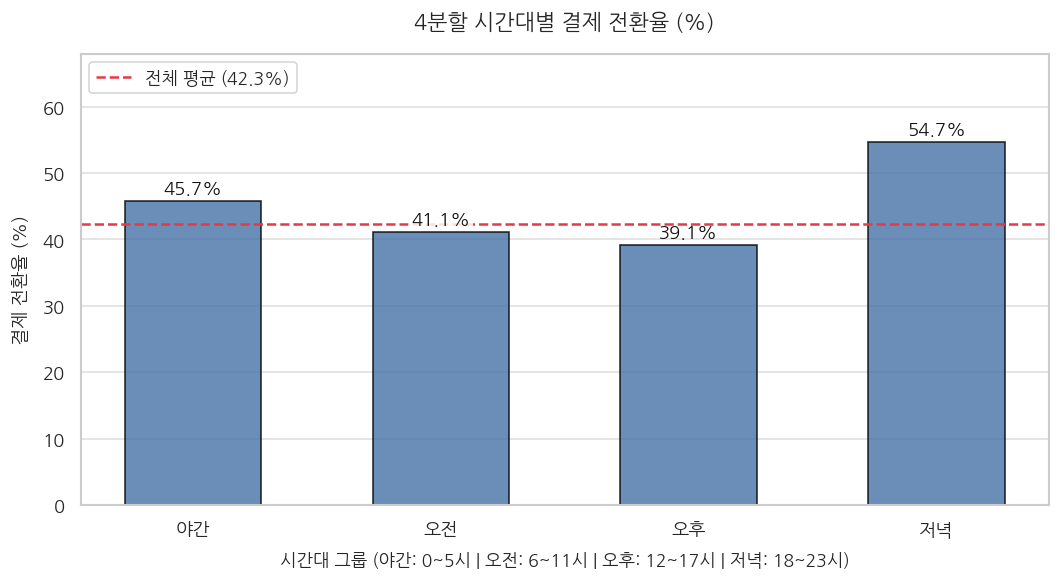

In [ ]:
# ------------------------------------------------------------------------------
# 2) 4분할 시간대별 결제 전환율 (%)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# 이전 셀 통일 스타일: 그리드 및 테두리 마감
ax.set_axisbelow(True)
ax.grid(True, axis='y', linestyle='-', color='#e0e0e0', linewidth=1.0)
ax.grid(False, axis='x')

# 막대 그래프
bars2 = ax.bar(
    _tg_stat['time_group'],
    _tg_stat['pay_rate'],
    color='#4572a7',
    edgecolor='black',
    linewidth=1.0,
    alpha=0.8,
    width=0.55,
)

# 전체 평균 기준선 (8-5, 8-6 셀과 100% 동일한 빨간 점선 스타일)
ax.axhline(
    _overall_pay_rate,
    color='#e63946',
    linestyle='--',
    linewidth=1.5,
    label=f'전체 평균 ({_overall_pay_rate:.1f}%)',
)
ax.legend(
    loc='upper left',
    fontsize=10.5,
    frameon=True,
    facecolor='white',
    edgecolor='#cccccc',
)

ax.set_title(
    '4분할 시간대별 결제 전환율 (%)', fontsize=13, fontweight='bold', pad=15
)
ax.set_xlabel(
    '시간대 그룹 (야간: 0~5시 | 오전: 6~11시 | 오후: 12~17시 | 저녁: 18~23시)',
    fontsize=10.5,
    labelpad=8,
)
ax.set_ylabel('결제 전환율 (%)', fontsize=11, labelpad=8)
ax.set_ylim(0, 68)
ax.set_yticks(range(0, 61, 10))

for sp in ['top', 'bottom', 'left', 'right']:
  ax.spines[sp].set_color('#cccccc')

# 텍스트 레이블 (평균 기준선과 겹치는 구간은 가독성 마스킹 적용)
for bar, row in zip(bars2, _tg_stat.itertuples()):
  bbox_p = (
      dict(
          boxstyle='round,pad=0.15',
          facecolor='white',
          edgecolor='none',
          alpha=0.85,
      )
      if abs(row.pay_rate - _overall_pay_rate) < 2.0
      else None
  )
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      row.pay_rate + 1.2,
      f'{row.pay_rate:.1f}%',
      ha='center',
      fontsize=11,
      fontweight='bold',
      color='#111111',
      bbox=bbox_p,
  )

plt.tight_layout()
plt.show()

# 집계 테이블 출력
display(
    _tg_stat[[
        'time_group',
        'session_count',
        'session_ratio',
        'pay_count',
        'pay_rate',
    ]].rename(
        columns={
            'time_group': '시간대 그룹',
            'session_count': '세션 수(건)',
            'session_ratio': '비율(%)',
            'pay_count': '결제 세션 수',
            'pay_rate': '결제율(%)',
        }
    )
)

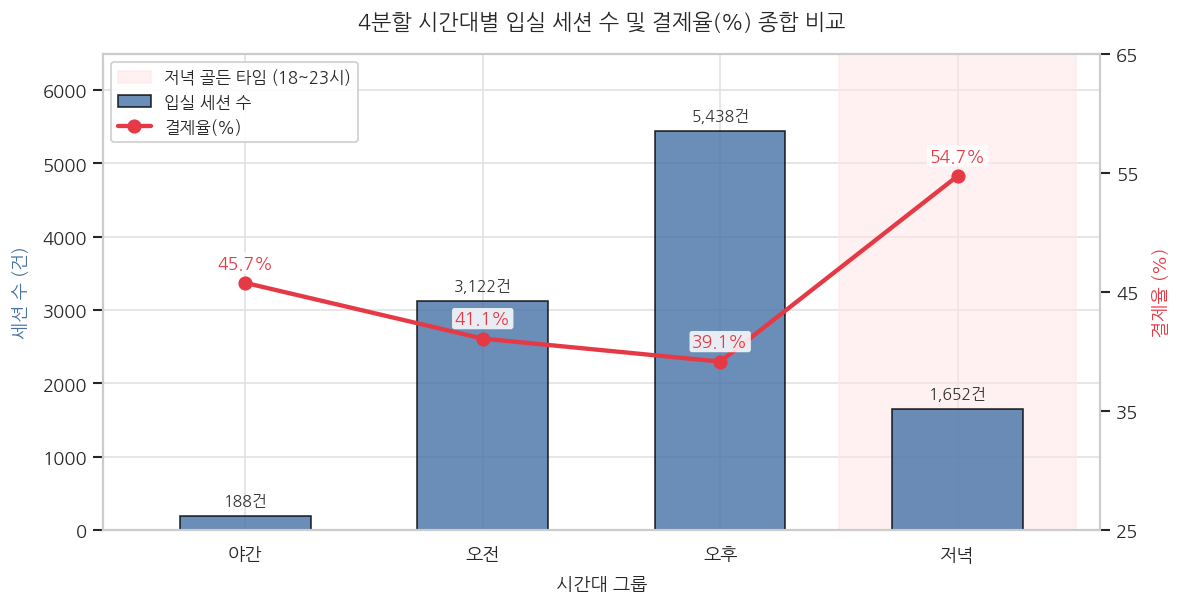

In [ ]:
# ------------------------------------------------------------------------------
# [통합형] 4분할 시간대별 세션 수 및 결제율(%) 이중축 복합 시각화 (8-3 스타일)
# ------------------------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 5.2), dpi=120)
ax2 = ax1.twinx()

ax1.set_axisbelow(True)
ax1.grid(True, which='major', linestyle='-', color='#e2e2e2', linewidth=1.0)
ax2.grid(False)

# 저녁 골든 타임 음영 (막대 뒤 zorder=1)
ax1.axvspan(
    2.5, 3.5, color='#ffe4e6', alpha=0.55, label='저녁 골든 타임 (18~23시)', zorder=1
)

# 1. 막대 그래프 (입실 세션 수)
bars_comb = ax1.bar(
    range(len(_tg_labels)),
    _tg_stat['session_count'],
    color='#4572a7',
    edgecolor='black',
    linewidth=1.0,
    alpha=0.8,
    width=0.55,
    label='입실 세션 수',
    zorder=2,
)

# 2. 꺾은선 그래프 (결제율)
lines_comb = ax2.plot(
    range(len(_tg_labels)),
    _tg_stat['pay_rate'],
    color='#e63946',
    marker='o',
    linewidth=2.6,
    markersize=7.5,
    label='결제율(%)',
    zorder=5,
)

ax1.set_title(
    '4분할 시간대별 입실 세션 수 및 결제율(%) 종합 비교',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax1.set_xlabel('시간대 그룹', fontsize=11, labelpad=8)
ax1.set_ylabel('세션 수 (건)', fontsize=11, color='#4572a7', labelpad=8)
ax2.set_ylabel('결제율 (%)', fontsize=11, color='#e63946', labelpad=8)

ax1.set_xticks(range(len(_tg_labels)))
ax1.set_xticklabels(_tg_labels, fontsize=11)
ax1.set_xlim(-0.6, len(_tg_labels) - 0.4)
ax1.set_ylim(0, 6500)
ax1.set_yticks(range(0, 6001, 1000))
ax2.set_ylim(25, 65)
ax2.set_yticks(range(25, 66, 10))

for sp in ['top', 'bottom', 'left', 'right']:
  ax1.spines[sp].set_color('#cccccc')
  ax2.spines[sp].set_color('#cccccc')

for i, row in _tg_stat.iterrows():
  ax1.text(
      i,
      row['session_count'] + 150,
      f"{row['session_count']:,}건",
      ha='center',
      fontsize=9.5,
      color='#333333',
  )
  ax2.annotate(
      f"{row['pay_rate']:.1f}%",
      (i, row['pay_rate']),
      textcoords='offset points',
      xytext=(0, 9),
      ha='center',
      fontsize=10.5,
      fontweight='bold',
      color='#e63946',
      bbox=dict(
          boxstyle='round,pad=0.15',
          facecolor='white',
          edgecolor='none',
          alpha=0.85,
      ),
      zorder=10,
  )

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
legend = ax1.legend(
    h1 + h2,
    l1 + l2,
    loc='upper left',
    fontsize=10,
    frameon=True,
    facecolor='white',
    edgecolor='#cccccc',
    framealpha=0.95,
)
legend.set_zorder(15)

ax1.set_zorder(ax2.get_zorder() - 1)
ax1.patch.set_visible(False)

plt.tight_layout()
plt.show()

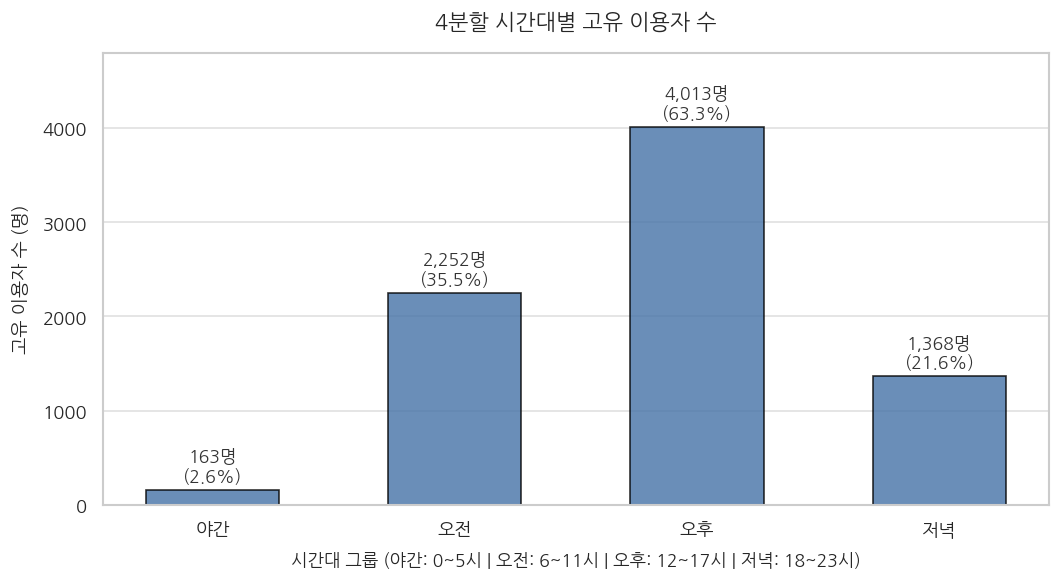

In [ ]:
# ------------------------------------------------------------------------------
# 3) 4분할 시간대별 고유 이용자 수 (Unique Users)
# ------------------------------------------------------------------------------
# 안전 참조: 이전 셀의 _df_eda가 없으면 df_pay / df_restored / df 참조
if '_df_eda' not in locals():
  if 'df_pay' in locals():
    _df_eda = df_pay.copy()
  elif 'df_restored' in locals():
    _df_eda = df_restored.copy()
  else:
    _df_eda = df.copy()

  if (
      'enter_hour' not in _df_eda.columns
      and 'first_enter_time' in _df_eda.columns
  ):
    _df_eda['first_enter_time'] = pd.to_datetime(_df_eda['first_enter_time'])
    _df_eda['enter_hour'] = _df_eda['first_enter_time'].dt.hour

  _tg_bins = [-1, 5, 11, 17, 23]
  _tg_labels = ['야간', '오전', '오후', '저녁']
  _df_eda['time_group'] = pd.cut(
      _df_eda['enter_hour'], bins=_tg_bins, labels=_tg_labels
  ).astype(str)

_total_users = _df_eda['user_uuid'].nunique()

# 4구간별 고유 이용자 수 집계
_user_stat = (
    _df_eda.groupby('time_group', observed=False)
    .agg(user_count=('user_uuid', 'nunique'))
    .reindex(_tg_labels)
    .reset_index()
)

_user_stat['user_ratio'] = (_user_stat['user_count'] / _total_users) * 100

# 시각화 (이전 셀들과 100% 동일한 스타일 적용)
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

ax.set_axisbelow(True)
ax.grid(True, axis='y', linestyle='-', color='#e0e0e0', linewidth=1.0)
ax.grid(False, axis='x')

bars_u = ax.bar(
    _user_stat['time_group'],
    _user_stat['user_count'],
    color='#4572a7',
    edgecolor='black',
    linewidth=1.0,
    alpha=0.8,
    width=0.55,
)

ax.set_title(
    '4분할 시간대별 고유 이용자 수', fontsize=13, fontweight='bold', pad=15
)
ax.set_xlabel(
    '시간대 그룹 (야간: 0~5시 | 오전: 6~11시 | 오후: 12~17시 | 저녁: 18~23시)',
    fontsize=10.5,
    labelpad=8,
)
ax.set_ylabel('고유 이용자 수 (명)', fontsize=11, labelpad=8)
ax.set_ylim(0, 4800)
ax.set_yticks(range(0, 4501, 1000))

# 테두리 박스 (연회색 마감)
for sp in ['top', 'bottom', 'left', 'right']:
  ax.spines[sp].set_color('#cccccc')

# 막대 상단 수치 및 전체 대비 점유율(%) 표시
for bar, row in zip(bars_u, _user_stat.itertuples()):
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      row.user_count + 90,
      f'{row.user_count:,}명\n({row.user_ratio:.1f}%)',
      ha='center',
      fontsize=10.5,
      color='#333333',
  )

plt.tight_layout()
plt.show()

# 데이터프레임 집계표 출력
display(
    _user_stat.rename(
        columns={
            'time_group': '시간대 그룹',
            'user_count': '고유 이용자 수(명)',
            'user_ratio': '전체 유저 대비 비율(%)',
        }
    )
)

---
# 9. 동일 일자 시간대 겹침 이상치 4개 행 식별 및 제거

## 9-1. 동일 일자 시간대 겹침 이상치 탐색

In [ ]:
# 1) 날짜/시간 타입 변환 및 유저·입실시간순 정렬
df_sorted = df_restored.sort_values(['user_uuid', 'first_enter_time']).reset_index(drop=True)
df_sorted['first_enter_time'] = pd.to_datetime(df_sorted['first_enter_time'])
df_sorted['last_leave_time'] = pd.to_datetime(df_sorted['last_leave_time'])

# 2) 시간 겹침 조건 식별: (동일 유저) & (현재 행 입실시간 < 직전 행 퇴실시간)
is_overlap_curr = (df_sorted['user_uuid'] == df_sorted['user_uuid'].shift(1)) & \
                  (df_sorted['first_enter_time'] < df_sorted['last_leave_time'].shift(1))

# 겹침이 발생한 앞 행과 뒤 행을 모두 표시
is_overlap_all = is_overlap_curr | is_overlap_curr.shift(-1, fill_value=False)

# 3) 겹침 이상치 행 조회
df_overlap = df_sorted[is_overlap_all]
print(f"탐색된 시간대 겹침 이상치: 총 {len(df_overlap)}개 행 ({df_overlap['user_uuid'].nunique()}명)")
display(df_overlap[['user_uuid', 'site_id', 'date', 'first_enter_time', 'last_leave_time', 'stay_minute']])

탐색된 시간대 겹침 이상치: 총 4개 행 (2명)


## 9-2. 겹침 이상치 4개 행 제거

In [ ]:
# 탐색된 겹침 행(~is_overlap_all)을 제외한 정상 데이터셋 생성
df_base = df_sorted[~is_overlap_all].copy()

print("=" * 50)
print(f"기존 데이터: {len(df_sorted):,}행")
print(f"제거된 겹침 이상치: {len(df_overlap):,}행")
print(f"-> 1차 정제 후 데이터 (df_base): {len(df_base):,}행")
print("=" * 50)

기존 데이터: 10,400행
제거된 겹침 이상치: 4행
-> 1차 정제 후 데이터 (df_base): 10,396행


## 9-3. trial_access_log 기반 u2 유저 6개 정상 이동 세션 생성

In [ ]:
# 8-3. trial_access_log 기반 u2 유저의 실제 이동 6개 세션 데이터 생성
# (KST 기준 / 5번 지점: 150평, 1번 지점: 50평)

u2 = 'USER_ID_8'

restored_u2_sessions = [
    {
        'site_id': 5,
        'date': '2021-09-04',
        'user_uuid': u2,
        'first_enter_time': '2021-09-04 09:12:11.841563',
        'last_leave_time': '2021-09-04 09:57:18.506129',
        'stay_time_second': 2706.66,
        'is_payment': 0,
        'area_pyeong': 150,
        'stay_minute': 45.11,
        'enter_hour': 9,
        'leave_hour': 9,
        'weekday': 'Saturday',
        'day_name_kr': '토'
    },
    {
        'site_id': 5,
        'date': '2021-09-04',
        'user_uuid': u2,
        'first_enter_time': '2021-09-04 10:04:04.758582',
        'last_leave_time': '2021-09-04 10:27:55.093124',
        'stay_time_second': 1430.33,
        'is_payment': 0,
        'area_pyeong': 150,
        'stay_minute': 23.84,
        'enter_hour': 10,
        'leave_hour': 10,
        'weekday': 'Saturday',
        'day_name_kr': '토'
    },
    {
        'site_id': 1,
        'date': '2021-09-04',
        'user_uuid': u2,
        'first_enter_time': '2021-09-04 11:58:33.044415',
        'last_leave_time': '2021-09-04 12:59:44.279439',
        'stay_time_second': 3671.24,
        'is_payment': 0,
        'area_pyeong': 50,
        'stay_minute': 61.19,
        'enter_hour': 11,
        'leave_hour': 12,
        'weekday': 'Saturday',
        'day_name_kr': '토'
    },
    {
        'site_id': 1,
        'date': '2021-09-04',
        'user_uuid': u2,
        'first_enter_time': '2021-09-04 15:08:09.457474',
        'last_leave_time': '2021-09-04 17:01:14.536224',
        'stay_time_second': 6785.08,
        'is_payment': 0,
        'area_pyeong': 50,
        'stay_minute': 113.08,
        'enter_hour': 15,
        'leave_hour': 17,
        'weekday': 'Saturday',
        'day_name_kr': '토'
    },
    {
        'site_id': 5,
        'date': '2021-09-04',
        'user_uuid': u2,
        'first_enter_time': '2021-09-04 19:52:29.440113',
        'last_leave_time': '2021-09-04 21:16:00.064323',
        'stay_time_second': 5010.62,
        'is_payment': 0,
        'area_pyeong': 150,
        'stay_minute': 83.51,
        'enter_hour': 19,
        'leave_hour': 21,
        'weekday': 'Saturday',
        'day_name_kr': '토'
    },
    {
        'site_id': 5,
        'date': '2021-09-04',
        'user_uuid': u2,
        'first_enter_time': '2021-09-04 21:59:40.042638',
        'last_leave_time': '2021-09-04 23:48:30.948002',
        'stay_time_second': 6530.91,
        'is_payment': 0,
        'area_pyeong': 150,
        'stay_minute': 108.85,
        'enter_hour': 21,
        'leave_hour': 23,
        'weekday': 'Saturday',
        'day_name_kr': '토'
    }
]

df_u2_new = pd.DataFrame(restored_u2_sessions)
df_u2_new['date'] = pd.to_datetime(df_u2_new['date'])
df_u2_new['first_enter_time'] = pd.to_datetime(df_u2_new['first_enter_time'])
df_u2_new['last_leave_time'] = pd.to_datetime(df_u2_new['last_leave_time'])

print(f"생성 완료된 u2 복원 세션 수: {len(df_u2_new)}행")
display(df_u2_new[['site_id', 'date', 'first_enter_time', 'last_leave_time', 'stay_minute']])

생성 완료된 u2 복원 세션 수: 6행


## 9-4. 기존 데이터와 결합 및 시간순 정렬

In [ ]:
# 공통 컬럼 결합
common_cols = [c for c in df_base.columns if c in df_u2_new.columns]
df_final = pd.concat([df_base[common_cols], df_u2_new[common_cols]], ignore_index=True)

# 유저 및 시간순 정렬
df_final = df_final.sort_values(['user_uuid', 'first_enter_time']).reset_index(drop=True)

print("=" * 60)
print(f"최종 정제 완료 데이터셋 (df_final): {len(df_final):,}행")
print(f"- 이상치 4행 제거: 10,400행 -> {len(df_base):,}행")
print(f"- 정상 분할 6행 추가: {len(df_base):,}행 -> {len(df_final):,}행")
print("=" * 60)

최종 정제 완료 데이터셋 (df_final): 10,402행
- 이상치 4행 제거: 10,400행 -> 10,396행
- 정상 분할 6행 추가: 10,396행 -> 10,402행


## 9-5. 정제 후 중복 재검증 및 복원 동선 확인

In [ ]:
# 전체 데이터셋 대상 시간 중복 재검사
is_overlap_recheck = (df_final['user_uuid'] == df_final['user_uuid'].shift(1)) & \
                     (df_final['first_enter_time'] < df_final['last_leave_time'].shift(1))

print(f"최종 정제 후 잔여 시간 겹침 건수: {is_overlap_recheck.sum()}건 (완벽 정제 확인)")

# u2 유저의 정상 분할된 당일 동선 출력
print("\n[u2 유저의 2021-09-04 정상 복원 동선 (총 6회)]")
u2_view = df_final[(df_final['user_uuid'] == u2) & (df_final['date'].dt.strftime('%Y-%m-%d') == '2021-09-04')]
display(u2_view[['site_id', 'date', 'first_enter_time', 'last_leave_time', 'stay_minute']])

최종 정제 후 잔여 시간 겹침 건수: 0건 (완벽 정제 확인)

[u2 유저의 2021-09-04 정상 복원 동선 (총 6회)]


In [ ]:
df_final.shape

(10402, 13)

In [ ]:
df_final.to_csv('찐최종_마스터_테이블')
df_final.to_csv('찐최종_마스터_테이블.csv', index=False, encoding='utf-8-sig')
print("찐최종_마스터_테이블 저장 완료 (행 수: %d)" % len(df_final))

찐최종_마스터_테이블 저장 완료 (행 수: 10402)


In [ ]:
print(df_final.head())
print('')
print(df_final.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10402 entries, 0 to 10401
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   site_id           10402 non-null  int64         
 1   date              10402 non-null  datetime64[ns]
 2   user_uuid         10402 non-null  object        
 3   first_enter_time  10402 non-null  datetime64[ns]
 4   last_leave_time   10402 non-null  datetime64[ns]
 5   stay_time_second  10402 non-null  float64       
 6   is_payment        10402 non-null  int64         
 7   area_pyeong       10402 non-null  int64         
 8   stay_minute       10402 non-null  float64       
 9   enter_hour        10402 non-null  int64         
 10  leave_hour        10402 non-null  int64         
 11  weekday           10402 non-null  object        
 12  day_name_kr       10402 non-null  object        
dtypes: datetime64[ns](3), float64(2), int64(5), object(3)
memory usage: 1.0+ MB


# ============================================================
# [PART 3] 머신러닝 모델링 최종 통합본 (260921_모델링_최종통합본.ipynb)
# ============================================================
이 파트는 정제된 `찐최종_마스터_테이블`을 활용하여:
1. 1차 모델링: 동시 체류 인원(수요) 회귀 및 3단계 등급 분류
2. 2차 모델링: 재방문 정보가 반영된 유저별 집계 테이블 기반 무료체험 이용자의 유료 결제 전환(is_payment) 예측 (base vs base+level A/B 테스트)
3. 성능 고도화 시도, 인과 사슬 분석(이용도 → 재방문 포기 → 결제 전환), 및 체류시간 변화량 기반 재모델링을 수행합니다.

# 요일·시간대별 무료체험 이용자 결제 전환 예측 모델링

## 체류시간이 좌우하는 유료 전환

2차 모델링(결제 전환 예측)은 전부 재방문 정보가 반영된 최신 유저별 집계 마스터 테이블(`찐최종_마스터_테이블_유저별_집계.csv`)을 사용합니다.

**전체 흐름**
1. 1차 모델링 — 동시 체류 인원(수요) 예측: 회귀 → 분류
2. 2차 모델링 — 결제 전환(is_payment) 예측: base vs base+level A/B 테스트
3. 성능을 더 올려볼 수 있는지 시도해본 것들 (① 새 변수 ② 하이퍼파라미터 튜닝 ③ 모델군 비교 ④ 임계값 조정)
4. A. 인과 사슬 분석 — 이용도 → 재방문 포기 → 전환
5. B. 재방문 정보를 반영한 유저별 집계 데이터로 재모델링 + 체류시간 변화량 (stay_growth) 추가 (⑤)
6. C. 종합 결론

## 0. 환경 설정 및 데이터 로드

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import os
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              f1_score, balanced_accuracy_score, roc_auc_score, classification_report)
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb
import lightgbm as lgb

pd.set_option('display.max_columns', None)

MASTER_CSV = './찐최종_마스터_테이블.csv'
if not os.path.exists(MASTER_CSV):
    if os.path.exists('./찐최종_마스터_테이블'):
        MASTER_CSV = './찐최종_마스터_테이블'
    elif os.path.exists(os.path.join("data", "찐최종_마스터_테이블.csv")):
        MASTER_CSV = os.path.join("data", "찐최종_마스터_테이블.csv")
    elif os.path.exists(os.path.join("data", "찐최종_마스터_테이블")):
        MASTER_CSV = os.path.join("data", "찐최종_마스터_테이블")
    elif 'df_final' in locals() and df_final is not None:
        df_final.to_csv('./찐최종_마스터_테이블.csv', index=False, encoding='utf-8-sig')
        MASTER_CSV = './찐최종_마스터_테이블.csv'

REGISTER_CSV = './trial_register.csv'
if not os.path.exists(REGISTER_CSV):
    if os.path.exists(os.path.join("data", "trial_register.csv")):
        REGISTER_CSV = os.path.join("data", "trial_register.csv")
    elif 'register' in locals() and register is not None:
        register.to_csv('./trial_register.csv', index=False, encoding='utf-8-sig')
        REGISTER_CSV = './trial_register.csv'
    elif 'trial_register_df' in locals() and trial_register_df is not None:
        trial_register_df.to_csv('./trial_register.csv', index=False, encoding='utf-8-sig')
        REGISTER_CSV = './trial_register.csv'

df = pd.read_csv(MASTER_CSV)
df['date'] = pd.to_datetime(df['date'])
df['first_enter_time'] = pd.to_datetime(df['first_enter_time'])
df['last_leave_time'] = pd.to_datetime(df['last_leave_time'])
df = df[(df['date'] >= '2021-05-01') & (df['date'] < '2024-01-01')].copy()
print('행 수:', len(df))

register = pd.read_csv(REGISTER_CSV)
register['trial_date'] = pd.to_datetime(register['trial_date'])
print('신청 데이터 행 수:', len(register))

행 수: 10388
신청 데이터 행 수: 9631


---
# 1. 1차 시도 — 시간대별(1시간 단위) 회귀분석 (회귀)

- **종속변수**: `concurrent_count` (1시간 단위 동시 체류 인원)
- **독립변수**: site_id, area_pyeong, dow_num(요일), hour(시간), is_weekend, month, site_tenure_days(지점 운영 경과일), hist_avg_site_dow_hour(지점×요일×시간 과거평균), rolling_7d_avg(최근 7일 이동평균)


In [ ]:
parts = []
for site, st in df.groupby('site_id'):
    start = st['first_enter_time'].min().floor('D')
    end = st['last_leave_time'].max().ceil('D')
    slots = pd.date_range(start, end, freq='30min')

    fe = st['first_enter_time'].values.astype('datetime64[ns]')
    ll = st['last_leave_time'].values.astype('datetime64[ns]')
    sv = slots.values.astype('datetime64[ns]')

    cnt = ((fe[None, :] <= sv[:, None]) & (ll[None, :] > sv[:, None])).sum(1)
    parts.append(pd.DataFrame({'time_slot': slots, 'occ': cnt, 'site_id': site}))

occ30 = pd.concat(parts, ignore_index=True)
occ30['date'] = occ30['time_slot'].dt.normalize()
occ30['hour'] = occ30['time_slot'].dt.hour

hourly = occ30.groupby(['site_id', 'date', 'hour'], as_index=False).agg(concurrent_count=('occ', 'mean'))
hourly['dow_num'] = hourly['date'].dt.weekday
hourly['is_weekend'] = (hourly['dow_num'] >= 5).astype(int)
hourly['month'] = hourly['date'].dt.month
hourly['area_pyeong'] = hourly['site_id'].map(df.groupby('site_id')['area_pyeong'].first())

site_open_date = hourly.groupby('site_id')['date'].transform('min')
hourly['site_tenure_days'] = (hourly['date'] - site_open_date).dt.days

hourly = hourly.sort_values(['site_id', 'hour', 'dow_num', 'date']).reset_index(drop=True)
grp = hourly.groupby(['site_id', 'dow_num', 'hour'])['concurrent_count']
hourly['hist_avg_site_dow_hour'] = grp.transform(lambda s: s.shift(1).expanding().mean()).fillna(0)

hourly = hourly.sort_values(['site_id', 'hour', 'date']).reset_index(drop=True)
grp2 = hourly.groupby(['site_id', 'hour'])['concurrent_count']
hourly['rolling_7d_avg'] = grp2.transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean()).fillna(0)

print('0인 시간대 비율: %.1f%%' % ((hourly['concurrent_count'] == 0).mean() * 100))
print('행 수:', hourly.shape)

0인 시간대 비율: 74.8%
행 수: (157929, 11)


In [ ]:
feature_cols_1 = ['site_id', 'area_pyeong', 'dow_num', 'hour', 'is_weekend', 'month',
                   'site_tenure_days', 'hist_avg_site_dow_hour', 'rolling_7d_avg']
target_col_1 = 'concurrent_count'

split_date = hourly['date'].max() - pd.Timedelta(days=60)
tr1 = hourly['date'] <= split_date
te1 = hourly['date'] > split_date

X_train1, y_train1 = hourly.loc[tr1, feature_cols_1], hourly.loc[tr1, target_col_1]
X_test1,  y_test1  = hourly.loc[te1, feature_cols_1], hourly.loc[te1, target_col_1]
print(f'Train: {X_train1.shape} / Test: {X_test1.shape}')

Train: (146665, 9) / Test: (11264, 9)


In [ ]:
def evaluate_reg(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    print(f'[{name}] MAE={mae:.3f}  RMSE={rmse:.3f}  R2={r2:.3f}')
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

results_1 = []
rf1 = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf1.fit(X_train1, y_train1)
results_1.append(evaluate_reg('RandomForest', y_test1, rf1.predict(X_test1)))

xgb1 = xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
xgb1.fit(X_train1, y_train1)
results_1.append(evaluate_reg('XGBoost', y_test1, xgb1.predict(X_test1)))

lgb1 = lgb.LGBMRegressor(n_estimators=400, max_depth=6, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1)
lgb1.fit(X_train1, y_train1)
results_1.append(evaluate_reg('LightGBM', y_test1, lgb1.predict(X_test1)))

pd.DataFrame(results_1)

[RandomForest] MAE=0.451  RMSE=0.698  R2=0.198
[XGBoost] MAE=0.464  RMSE=0.731  R2=0.119
[LightGBM] MAE=0.456  RMSE=0.732  R2=0.118


**해석**: MAE는 "실제 인원수와 예측 인원수가 평균적으로 몇 명 차이나는지", R²는 "모델이 얼마나 잘 맞혔는지(1에 가까울수록 좋음, 0이면 평균만 찍은 것과 다를 바 없음)"를 나타냅니다. 세 모델 다 R²가 0.1~0.2대로 낮아서, 1시간 단위로는 모델이 거의 제대로 못 맞혔다고 보면 됩니다.

**→ 1단계 결론**: 1시간 단위로 쪼개니 0인 시간대 비율이 약 75%로 너무 많아서, 회귀 모델이 유의미한 신호를 잡아내지 못했습니다(R² 0.10~0.20 수준). 해상도를 더 넓혀볼 필요가 있습니다.

**모델별 성능 요약표**

| 모델 | MAE | RMSE | R² |
|---|---|---|---|
| RandomForest | 0.451 | 0.698 | 0.198 |
| XGBoost | 0.464 | 0.731 | 0.119 |
| LightGBM | 0.456 | 0.732 | 0.118 |

---
# 2. 4구간(야간/오전/오후/저녁)으로 확장 — 회귀

- **종속변수**: `occ_mean` (4구간 평균 동시 체류 인원, 연속값)
- **독립변수**: site_id, area_pyeong, weekday, is_weekend, time_group_idx(4구간), site_wd_tg_avg(지점×요일×구간 평균), lag_1d/1w/2w, roll_4w/7d, register_lag_1d, register_recent_4d/7d


In [ ]:
tg_bins = [-1, 5, 11, 17, 23]
tg_labels = ['야간', '오전', '오후', '저녁']
occ30['time_group'] = pd.cut(occ30['hour'], bins=tg_bins, labels=tg_labels).astype(str)

occ4 = occ30.groupby(['site_id', 'date', 'time_group'], as_index=False).agg(occ_mean=('occ', 'mean'))
occ4['weekday'] = occ4['date'].dt.weekday
occ4['is_weekend'] = (occ4['weekday'] >= 5).astype(int)
occ4['area_pyeong'] = occ4['site_id'].map(df.groupby('site_id')['area_pyeong'].first())

tg_order = {'야간': 0, '오전': 1, '오후': 2, '저녁': 3}
occ4['time_group_idx'] = occ4['time_group'].map(tg_order)
occ4 = occ4.sort_values(['site_id', 'date', 'time_group_idx']).reset_index(drop=True)

print('4구간 집계 행 수:', occ4.shape)
print('0 비율: %.1f%%' % ((occ4['occ_mean'] == 0).mean() * 100))

4구간 집계 행 수: (26329, 8)
0 비율: 61.6%


In [ ]:
CUTOFF = '2023-09-01'
tr4 = occ4['date'] < CUTOFF
te4 = occ4['date'] >= CUTOFF

stat4 = occ4[tr4].groupby(['site_id', 'weekday', 'time_group'])['occ_mean'].mean().rename('site_wd_tg_avg')
occ4['site_wd_tg_avg'] = occ4.set_index(['site_id', 'weekday', 'time_group']).index.map(stat4)
occ4['site_wd_tg_avg'] = occ4['site_wd_tg_avg'].fillna(0)

g4 = occ4.groupby(['site_id', 'time_group'])['occ_mean']
occ4['lag_1d']  = g4.shift(1)
occ4['lag_1w']  = g4.shift(7)
occ4['lag_2w']  = g4.shift(14)
occ4['roll_4w'] = g4.shift(7).rolling(28, min_periods=1).mean()
occ4['roll_7d'] = g4.shift(1).rolling(7, min_periods=1).mean()

lag_cols4 = ['lag_1d', 'lag_1w', 'lag_2w', 'roll_4w', 'roll_7d']
occ4[lag_cols4] = occ4[lag_cols4].fillna(0)

reg_daily = (register.groupby('trial_date')['user_uuid'].nunique()
             .rename('register_count').reset_index()
             .rename(columns={'trial_date': 'date'}))
all_dates = pd.DataFrame({'date': pd.date_range(occ4['date'].min(), occ4['date'].max(), freq='D')})
reg_feat = all_dates.merge(reg_daily, on='date', how='left').fillna({'register_count': 0})
reg_feat['register_lag_1d'] = reg_feat['register_count'].shift(1).fillna(0)
reg_feat['register_recent_4d'] = reg_feat['register_count'].shift(1).rolling(4, min_periods=1).sum().fillna(0)
reg_feat['register_recent_7d'] = reg_feat['register_count'].shift(1).rolling(7, min_periods=1).sum().fillna(0)

occ4 = occ4.merge(reg_feat[['date', 'register_lag_1d', 'register_recent_4d', 'register_recent_7d']], on='date', how='left')

tr4 = occ4['date'] < CUTOFF
te4 = occ4['date'] >= CUTOFF
print('train', tr4.sum(), '/ test', te4.sum())

train 22252 / test 4077


In [ ]:
feature_cols_2 = ['site_id', 'area_pyeong', 'weekday', 'is_weekend', 'time_group_idx',
                   'site_wd_tg_avg', 'lag_1d', 'lag_1w', 'lag_2w', 'roll_4w', 'roll_7d',
                   'register_lag_1d', 'register_recent_4d', 'register_recent_7d']
target_col_2 = 'occ_mean'

X_train2, y_train2 = occ4.loc[tr4, feature_cols_2], occ4.loc[tr4, target_col_2]
X_test2,  y_test2  = occ4.loc[te4, feature_cols_2], occ4.loc[te4, target_col_2]

results_2 = []
results_2.append(evaluate_reg('베이스라인-그룹평균', y_test2, X_test2['site_wd_tg_avg']))

rf2 = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf2.fit(X_train2, y_train2)
results_2.append(evaluate_reg('RandomForest', y_test2, rf2.predict(X_test2)))

xgb2 = xgb.XGBRegressor(objective='count:poisson', n_estimators=400, max_depth=6, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
xgb2.fit(X_train2, y_train2)
results_2.append(evaluate_reg('XGBoost (poisson)', y_test2, xgb2.predict(X_test2)))

lgb2 = lgb.LGBMRegressor(objective='poisson', n_estimators=400, max_depth=6, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1)
lgb2.fit(X_train2, y_train2)
results_2.append(evaluate_reg('LightGBM (poisson)', y_test2, lgb2.predict(X_test2)))

pd.DataFrame(results_2)

[베이스라인-그룹평균] MAE=0.365  RMSE=0.584  R2=0.202
[RandomForest] MAE=0.341  RMSE=0.551  R2=0.289
[XGBoost (poisson)] MAE=0.337  RMSE=0.547  R2=0.301
[LightGBM (poisson)] MAE=0.339  RMSE=0.548  R2=0.297


**해석**: 첫 줄(베이스라인-그룹평균)은 "그냥 그 지점·요일·구간의 평균값으로만 찍었을 때"의 점수입니다. 그 아래 RF/XGB/LGBM이 이 베이스라인보다 R²가 높으면, 모델이 단순 평균보다 더 똑똑하게 예측했다는 뜻입니다. 실제로 R²가 0.20 → 0.29~0.30으로 올라가서, 모델이 그룹평균보다 나은 신호를 학습했습니다.

**→ 2단계 결론**: baseline(그룹평균) 대비 모델 R²가 개선되어, 4구간 해상도에서는 회귀 모델이 그룹평균 이상의 신호를 학습했습니다. 다만 절대적인 정밀도는 여전히 부족합니다.

**모델별 성능 요약표**

| 모델 | MAE | RMSE | R² |
|---|---|---|---|
| 베이스라인(그룹평균) | 0.365 | 0.584 | 0.202 |
| RandomForest | 0.341 | 0.551 | 0.289 |
| XGBoost | 0.337 | 0.547 | 0.301 |
| LightGBM | 0.339 | 0.548 | 0.297 |

---
# 3. 해상도를 일별로 확장 — 요일 단위 예측 (회귀)

- **종속변수**: `occ_mean` (일별 평균 동시 체류 인원)
- **독립변수**: site_id, area_pyeong, weekday, is_weekend, site_wd_avg, lag_1d/1w/2w, roll_4w/7d, register_lag_1d, register_recent_4d/7d


In [ ]:
occ_d = occ30.groupby(['site_id', 'date'], as_index=False).agg(occ_mean=('occ', 'mean'))
occ_d['weekday'] = occ_d['date'].dt.weekday
occ_d['is_weekend'] = (occ_d['weekday'] >= 5).astype(int)
occ_d['area_pyeong'] = occ_d['site_id'].map(df.groupby('site_id')['area_pyeong'].first())
occ_d = occ_d.sort_values(['site_id', 'date']).reset_index(drop=True)

tr_d = occ_d['date'] < CUTOFF
te_d = occ_d['date'] >= CUTOFF

stat_d = occ_d[tr_d].groupby(['site_id', 'weekday'])['occ_mean'].mean().rename('site_wd_avg')
occ_d['site_wd_avg'] = occ_d.set_index(['site_id', 'weekday']).index.map(stat_d)
occ_d['site_wd_avg'] = occ_d['site_wd_avg'].fillna(0)

g_d = occ_d.groupby('site_id')['occ_mean']
occ_d['lag_1d']  = g_d.shift(1)
occ_d['lag_1w']  = g_d.shift(7)
occ_d['lag_2w']  = g_d.shift(14)
occ_d['roll_4w'] = g_d.shift(7).rolling(28, min_periods=1).mean()
occ_d['roll_7d'] = g_d.shift(1).rolling(7, min_periods=1).mean()
occ_d[['lag_1d','lag_1w','lag_2w','roll_4w','roll_7d']] = occ_d[['lag_1d','lag_1w','lag_2w','roll_4w','roll_7d']].fillna(0)

occ_d = occ_d.merge(reg_feat[['date', 'register_lag_1d', 'register_recent_4d', 'register_recent_7d']], on='date', how='left')

tr_d = occ_d['date'] < CUTOFF
te_d = occ_d['date'] >= CUTOFF
print('train', tr_d.sum(), '/ test', te_d.sum())

train 5563 / test 1026


In [ ]:
feature_cols_3 = ['site_id', 'area_pyeong', 'weekday', 'is_weekend', 'site_wd_avg',
                   'lag_1d', 'lag_1w', 'lag_2w', 'roll_4w', 'roll_7d',
                   'register_lag_1d', 'register_recent_4d', 'register_recent_7d']
target_col_3 = 'occ_mean'

X_train3, y_train3 = occ_d.loc[tr_d, feature_cols_3], occ_d.loc[tr_d, target_col_3]
X_test3,  y_test3  = occ_d.loc[te_d, feature_cols_3], occ_d.loc[te_d, target_col_3]

rf3 = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf3.fit(X_train3, y_train3)

xgb3 = xgb.XGBRegressor(objective='count:poisson', n_estimators=400, max_depth=6, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
xgb3.fit(X_train3, y_train3)

lgb3 = lgb.LGBMRegressor(objective='poisson', n_estimators=400, max_depth=6, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1)
lgb3.fit(X_train3, y_train3)

pred_xgb3 = xgb3.predict(X_test3)
results_3 = []
results_3.append(evaluate_reg('베이스라인-그룹평균', y_test3, X_test3['site_wd_avg']))
results_3.append(evaluate_reg('RandomForest', y_test3, rf3.predict(X_test3)))
results_3.append(evaluate_reg('XGBoost (poisson)', y_test3, pred_xgb3))
results_3.append(evaluate_reg('LightGBM (poisson)', y_test3, lgb3.predict(X_test3)))
pd.DataFrame(results_3)

[베이스라인-그룹평균] MAE=0.305  RMSE=0.434  R2=0.064
[RandomForest] MAE=0.273  RMSE=0.397  R2=0.215
[XGBoost (poisson)] MAE=0.270  RMSE=0.396  R2=0.222
[LightGBM (poisson)] MAE=0.273  RMSE=0.399  R2=0.209


**해석**: 4구간 때와 마찬가지로, 그룹평균 baseline보다 모델(XGB 기준 R² 0.064 → 0.218)이 확실히 개선됐습니다. 다만 일별로 더 넓게 뭉뚱그렸기 때문에, 이 개선이 "숫자를 더 정밀하게 맞혔다"기보다는 "원래 그룹평균만으로는 설명이 잘 안 되던 것을 모델이 어느 정도 메꿨다"는 의미에 가깝습니다.

In [ ]:
day_kr = {0:'월', 1:'화', 2:'수', 3:'목', 4:'금', 5:'토', 6:'일'}
order = ['월', '화', '수', '목', '금', '토', '일']

test_result = occ_d.loc[te_d, ['site_id', 'date', 'weekday', 'occ_mean']].copy()
test_result['day_name'] = test_result['weekday'].map(day_kr)
test_result['pred_xgb'] = pred_xgb3

summary = test_result.groupby('day_name')[['occ_mean', 'pred_xgb']].mean().reindex(order)
summary.columns = ['실제_평균인원', '예측_평균인원(XGB)']
summary.round(3)

**해석**: 요일별로 "실제로 관측된 평균 인원"과 "모델이 예측한 평균 인원"을 나란히 놓은 표입니다. 두 컬럼의 숫자가 비슷한 순서로 오르내리면(예: 둘 다 수/목요일에 제일 높음) 모델이 요일별 경향을 잘 잡아낸 것이고, 특정 요일만 유독 차이가 크면(예: 토요일) 그 요일에 한해 예측이 부정확하다는 뜻입니다.

**→ 3단계 결론**: 수/목요일을 가장 붐비는 요일로 예측했고, 실제 데이터와 방향이 대체로 일치했습니다. 다만 해상도를 시간대→4구간→일별로 바꿔가며 다 시도해봤지만, 어느 단위든 숫자를 정밀하게 맞히는 데는 한계가 있었습니다. 회귀만으로는 "정밀한 인원수"보다 "상대적인 경향" 파악에 더 적합하다는 결론입니다.

**모델별 성능 요약표**

| 모델 | MAE | RMSE | R² |
|---|---|---|---|
| 베이스라인(그룹평균) | 0.305 | 0.434 | 0.064 |
| RandomForest | 0.273 | 0.397 | 0.215 |
| XGBoost | 0.270 | 0.396 | 0.222 |
| LightGBM | 0.273 | 0.399 | 0.209 |

In [ ]:
labels = ['수요 없음', '보통', '높음']
lab2idx = {l: i for i, l in enumerate(labels)}

def evaluate_clf(name, y_true_idx, y_pred_idx):
    f1 = f1_score(y_true_idx, y_pred_idx, average='macro')
    ba = balanced_accuracy_score(y_true_idx, y_pred_idx)
    print(f'[{name}] MacroF1={f1:.3f}  BalancedAcc={ba:.3f}')
    print(classification_report(y_true_idx, y_pred_idx, target_names=labels, digits=3))
    return {'model': name, 'MacroF1': f1, 'BalancedAcc': ba}

---
# 4. 1시간 단위 등급 분류 전환 (분류)

회귀는 해상도를 바꿔가며 시도해봤지만, 등급분류도 회귀와 같은 1시간 해상도에서 먼저 시도해봅니다(회귀가 1시간 단위에서 실패했던 것과 똑같은 문제, 즉 관측치가 너무 쪼개져 있다는 문제가 분류에서도 나타나는지 확인).

- **종속변수**: `level` (수요없음/보통/높음, 3-클래스)
- **독립변수**: site_id, area_pyeong, weekday, hour, is_weekend, site_wd_hour_avg(지점×요일×시간 평균), lag_1d/1w/2w, roll_4w/7d, register_lag_1d, register_recent_4d/7d


In [ ]:
occ_h = hourly.rename(columns={'concurrent_count': 'occ_mean', 'dow_num': 'weekday'}).copy()
occ_h = occ_h.sort_values(['site_id', 'date', 'hour']).reset_index(drop=True)

tr_h = occ_h['date'] < CUTOFF
te_h = occ_h['date'] >= CUTOFF

stat_h = (occ_h[tr_h].groupby(['site_id', 'weekday', 'hour'])['occ_mean']
          .mean().rename('site_wd_hour_avg'))
occ_h['site_wd_hour_avg'] = occ_h.set_index(['site_id', 'weekday', 'hour']).index.map(stat_h)
occ_h['site_wd_hour_avg'] = occ_h['site_wd_hour_avg'].fillna(0)

g_h = occ_h.groupby('site_id')['occ_mean']
occ_h['lag_1d']  = g_h.shift(24)
occ_h['lag_1w']  = g_h.shift(168)
occ_h['lag_2w']  = g_h.shift(336)
occ_h['roll_4w'] = g_h.shift(168).rolling(4 * 168, min_periods=1).mean()
occ_h['roll_7d'] = g_h.shift(24).rolling(24 * 7, min_periods=1).mean()

lag_cols_h = ['lag_1d', 'lag_1w', 'lag_2w', 'roll_4w', 'roll_7d']
occ_h[lag_cols_h] = occ_h[lag_cols_h].fillna(0)

occ_h = occ_h.merge(reg_feat[['date', 'register_lag_1d', 'register_recent_4d', 'register_recent_7d']], on='date', how='left')

tr_h = occ_h['date'] < CUTOFF
te_h = occ_h['date'] >= CUTOFF
print('train', tr_h.sum(), '/ test', te_h.sum())

train 133512 / test 24417


In [ ]:
nonzero_train_h = occ_h[tr_h & (occ_h['occ_mean'] > 0)]
thr_h = nonzero_train_h.groupby('site_id')['occ_mean'].quantile(0.75).clip(lower=1.0)
occ_h['thr'] = occ_h['site_id'].map(thr_h)

occ_h['level'] = np.select(
    [occ_h['occ_mean'] < 0.25, occ_h['occ_mean'] >= occ_h['thr']],
    ['수요 없음', '높음'],
    default='보통'
)
print(occ_h['level'].value_counts())

level
수요 없음    118115
보통        24677
높음        15137
Name: count, dtype: int64


**해석**: "수요없음"이 압도적으로 많고 "보통"·"높음"은 적은, 불균형한 분포입니다. 이 불균형 때문에 모델이 "무조건 수요없음"이라고만 찍어도 정확도가 높게 나오는 함정이 있어서, 아래 학습에서는 `class_weight='balanced'` 같은 보정을 적용합니다.

In [ ]:
feature_cols_h = ['site_id', 'area_pyeong', 'weekday', 'hour', 'is_weekend', 'site_wd_hour_avg',
                   'lag_1d', 'lag_1w', 'lag_2w', 'roll_4w', 'roll_7d',
                   'register_lag_1d', 'register_recent_4d', 'register_recent_7d']

X_train_h, y_train_h = occ_h.loc[tr_h, feature_cols_h], occ_h.loc[tr_h, 'level']
X_test_h,  y_test_h  = occ_h.loc[te_h, feature_cols_h], occ_h.loc[te_h, 'level']
y_train_h_idx = y_train_h.map(lab2idx)
y_test_h_idx = y_test_h.map(lab2idx)

sw_train_h = compute_sample_weight('balanced', y_train_h_idx)

rf_h = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                               class_weight='balanced', random_state=42, n_jobs=-1)
rf_h.fit(X_train_h, y_train_h_idx)
res_h_rf = evaluate_clf('RandomForest', y_test_h_idx, rf_h.predict(X_test_h))

xgb_h = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                           subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
                           eval_metric='mlogloss')
xgb_h.fit(X_train_h, y_train_h_idx, sample_weight=sw_train_h)
res_h_xgb = evaluate_clf('XGBoost', y_test_h_idx, xgb_h.predict(X_test_h))

lgb_h = lgb.LGBMClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, class_weight='balanced',
                            random_state=42, n_jobs=-1, verbose=-1)
lgb_h.fit(X_train_h, y_train_h_idx)
res_h_lgb = evaluate_clf('LightGBM', y_test_h_idx, lgb_h.predict(X_test_h))

pd.DataFrame([res_h_rf, res_h_xgb, res_h_lgb])

[RandomForest] MacroF1=0.521  BalancedAcc=0.574
              precision    recall  f1-score   support

       수요 없음      0.898     0.690     0.780     18061
          보통      0.309     0.533     0.391      3837
          높음      0.322     0.499     0.392      2519

    accuracy                          0.646     24417
   macro avg      0.510     0.574     0.521     24417
weighted avg      0.746     0.646     0.679     24417

[XGBoost] MacroF1=0.520  BalancedAcc=0.577
              precision    recall  f1-score   support

       수요 없음      0.897     0.677     0.771     18061
          보통      0.309     0.555     0.397      3837
          높음      0.322     0.498     0.391      2519

    accuracy                          0.639     24417
   macro avg      0.509     0.577     0.520     24417
weighted avg      0.745     0.639     0.673     24417

[LightGBM] MacroF1=0.519  BalancedAcc=0.578
              precision    recall  f1-score   support

       수요 없음      0.899     0.673     0.770     

**해석**: MacroF1과 BalancedAcc는 "수요없음/보통/높음" 세 등급을 얼마나 고르게 잘 맞혔는지 나타냅니다(1에 가까울수록 좋음). 위쪽에 같이 출력된 classification_report에서 "높음" 행의 recall(재현율)을 보면, "실제로 높음이었던 것 중 모델이 몇 %나 높음이라고 맞혔는지" 알 수 있습니다 — precision이 0.3대로 낮다는 건, 모델이 "높음"이라고 예측했을 때 실제로는 아닌 경우(오탐)가 꽤 있었다는 뜻입니다.

**→ 4단계 결론**: 1시간 단위에서도 등급분류 자체는 어느 정도 작동했습니다(Macro F1 0.52 내외, RF 0.521). 다만 "보통"·"높음" 등급의 precision이 0.3대로 낮아 오탐(실제로는 안 붐빈 시간을 붐빈다고 잘못 예측)이 잦았습니다. 관측 단위가 너무 촘촘해서 개별 시간대 하나하나의 노이즈에 민감한 것으로 보입니다. 해상도를 넓혀서 다시 시도해봅니다.

**모델별 성능 요약표**

| 모델 | Macro F1 | Balanced Accuracy | 재현율("높음") |
|---|---|---|---|
| RandomForest | 0.521 | 0.574 | 49.9% |
| XGBoost | 0.520 | 0.577 | 49.8% |
| LightGBM | 0.519 | 0.578 | 51.3% |

---
# 5. 그래서 4구간에서 등급분류로 전환 (분류) — 1차 최종 채택 모델

회귀로는 절대적인 인원수를 정밀하게 맞히기 어려웠으므로, "수요없음/보통/높음" 3단계 등급으로 문제를 바꿔서 다시 시도합니다. 등급은 지점별로 데이터 기반 임계값(0이 아닌 관측치의 75분위수, 최소 1.0)을 사용해 나눕니다.

- **종속변수**: `level` (수요없음/보통/높음, 3-클래스)
- **독립변수**: site_id, area_pyeong, weekday, is_weekend, time_group_idx, site_wd_tg_avg, lag_1d/1w/2w, roll_4w/7d, register_lag_1d, register_recent_4d/7d


In [ ]:
nonzero_train = occ4[tr4 & (occ4['occ_mean'] > 0)]
thr = nonzero_train.groupby('site_id')['occ_mean'].quantile(0.75).clip(lower=1.0)
occ4['thr'] = occ4['site_id'].map(thr)

occ4['level'] = np.select(
    [occ4['occ_mean'] < 0.25, occ4['occ_mean'] >= occ4['thr']],
    ['수요 없음', '높음'],
    default='보통'
)

print(occ4['level'].value_counts())
print()
print('=== 등급별 실제 인원수 통계 ===')
print(occ4.groupby('level')['occ_mean'].agg(['mean', 'median', 'min', 'max']).round(2))

# 1차 5단계 등급(level) 파일 저장 (이후 Cell 73, 95에서 GRADE_CSV로 로드)
occ4[['site_id', 'date', 'time_group', 'level']].to_csv('occ_4tg_final.csv', index=False, encoding='utf-8-sig')
print('occ_4tg_final.csv 저장 완료')

level
수요 없음    17571
보통        6007
높음        2751
Name: count, dtype: int64

=== 등급별 실제 인원수 통계 ===
       mean  median   min    max
level                           
높음     2.04    1.83  1.00  17.00
보통     0.66    0.67  0.25   1.50
수요 없음  0.01    0.00  0.00   0.17
occ_4tg_final.csv 저장 완료


**해석**: 두 번째 표("등급별 실제 인원수 통계")가 핵심인데, "높음" 등급의 평균 인원(mean)을 보면 실제로는 1~2명 수준밖에 안 됩니다. 등급 이름만 보면 "높음=엄청 붐빔"처럼 느껴지지만, 실제 절대 인원수는 크지 않다는 걸 이 표로 확인할 수 있습니다 — 이게 뒤에서 "등급만으로는 비즈니스 액션을 내리기 어렵다"고 한 이유입니다.

In [ ]:
X_train4, y_train4 = occ4.loc[tr4, feature_cols_2], occ4.loc[tr4, 'level']
X_test4,  y_test4  = occ4.loc[te4, feature_cols_2], occ4.loc[te4, 'level']
y_train4_idx = y_train4.map(lab2idx)
y_test4_idx = y_test4.map(lab2idx)

sw_train = compute_sample_weight('balanced', y_train4_idx)

rf4 = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                              class_weight='balanced', random_state=42, n_jobs=-1)
rf4.fit(X_train4, y_train4_idx)
res4_rf = evaluate_clf('RandomForest', y_test4_idx, rf4.predict(X_test4))

xgb4 = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
                          eval_metric='mlogloss')
xgb4.fit(X_train4, y_train4_idx, sample_weight=sw_train)
res4_xgb = evaluate_clf('XGBoost', y_test4_idx, xgb4.predict(X_test4))

lgb4 = lgb.LGBMClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                           subsample=0.8, colsample_bytree=0.8, class_weight='balanced',
                           random_state=42, n_jobs=-1, verbose=-1)
lgb4.fit(X_train4, y_train4_idx)
res4_lgb = evaluate_clf('LightGBM', y_test4_idx, lgb4.predict(X_test4))

pd.DataFrame([res4_rf, res4_xgb, res4_lgb])

[RandomForest] MacroF1=0.544  BalancedAcc=0.573
              precision    recall  f1-score   support

       수요 없음      0.835     0.717     0.772      2652
          보통      0.395     0.460     0.425       993
          높음      0.363     0.542     0.435       432

    accuracy                          0.636      4077
   macro avg      0.531     0.573     0.544      4077
weighted avg      0.678     0.636     0.652      4077

[XGBoost] MacroF1=0.525  BalancedAcc=0.557
              precision    recall  f1-score   support

       수요 없음      0.833     0.696     0.758      2652
          보통      0.395     0.462     0.426       993
          높음      0.317     0.512     0.391       432

    accuracy                          0.620      4077
   macro avg      0.515     0.557     0.525      4077
weighted avg      0.671     0.620     0.638      4077

[LightGBM] MacroF1=0.512  BalancedAcc=0.547
              precision    recall  f1-score   support

       수요 없음      0.832     0.684     0.751     

**해석**: 4단계(1시간 단위)와 같은 지표를 4구간 해상도로 다시 계산한 결과입니다. RF 기준 MacroF1이 0.521(1시간)→0.544(4구간)로 올랐고, classification_report에서 "높음" 등급 recall도 개선됐습니다. 즉 관측 단위를 넓히니 등급을 더 안정적으로 맞혔다는 뜻입니다.

**→ 5단계 결론(1차 최종)**: 1시간 단위(RF 기준 Macro F1 0.521)보다 4구간(RF 기준 Macro F1 0.544)에서 최고 성능이 더 높게 나왔고, "높음" 등급 recall도 49.9%→54.2%로 개선됐습니다. 인원수를 그대로 맞히는 건 어려웠지만, "수요없음/보통/높음" 3단계로 나누니 결과 도출이 가능했습니다. 다만 "높음" 등급이라 해도 실제 인원수는 1~2명 수준이었습니다. **등급을 나누는 것 자체는 성공적이었지만, 이를 그대로 비즈니스 인사이트로 활용하는 데에는 어려움이 있었습니다.** 그래서 이 등급을 다른 모델의 feature로 재활용해보기로 했습니다.

**모델별 성능 요약표**

| 모델 | Macro F1 | Balanced Accuracy | 재현율("높음") |
|---|---|---|---|
| RandomForest | 0.544 | 0.573 | 54.2% |
| XGBoost | 0.525 | 0.557 | 51.2% |
| LightGBM | 0.512 | 0.547 | 52.3% |

---
# 6. 2차 모델 — 결제 전환 예측

1차 등급(level) 자체로는 절대 인원수가 작아 비즈니스 액션으로 바로 연결하기 어려웠으므로, 이 등급을 **유료 전환 예측 모델의 feature로 재활용**해서 "혼잡한 시간대에 체험한 유저인지 여부가 전환에 영향을 주는가"를 확인합니다.

- **종속변수**: `is_payment`
- **독립변수(base)**: site_id, area_pyeong, weekday_num, is_weekend, time_group_idx, stay_minute
- **독립변수(base+level, A/B)**: base + `level_idx`(4단계에서 만든 수요등급)
- **모델**: RandomForest / XGBoost / LightGBM


## 6-1. 데이터 준비 — 재방문 정보가 반영된 유저별 집계 + 등급 매칭

2차 결제 전환 모델링에서는 전체 방문 기록을 유저별 1행으로 집계하였습니다. 지점·요일·시간대는 최빈값, 체류시간은 중앙값, 주말 이용 여부는 주말 방문 비율을 기준으로 대표값을 생성하였습니다.

유저별 집계 데이터에는 재방문 기록이 반영되어 있지만, 수요등급은 대표 지점·시간대와 유저의 첫 방문 날짜를 기준으로 매칭하였습니다.

### [중간 데이터 생성] 2차 모델링을 위한 '찐최종_마스터_테이블_유저별_집계' 생성
2차 모델링(결제 전환 예측)을 수행하기 위해 세션 단위의 `찐최종_마스터_테이블`을 유저(user_uuid) 단위로 GroupBy 집계(최빈 지점/요일/시간대, 중앙값 체류시간 등)하여 모델링용 테이블(`찐최종_마스터_테이블_유저별_집계.csv`)을 생성합니다.

In [ ]:
import os
import pandas as pd
import numpy as np

# 1. 파일 경로 설정
downloads_dir = "data" if os.path.exists("data") else "."
possible_names = [
    "찐최종_마스터_테이블",
    "찐최종_마스터_테이블.csv",
    os.path.join(downloads_dir, "찐최종_마스터_테이블"),
    os.path.join(downloads_dir, "찐최종_마스터_테이블.csv"),
    "./찐최종_마스터_테이블",
    "./찐최종_마스터_테이블.csv"
]

master_file = None
for name in possible_names:
    if os.path.exists(name):
        master_file = name
        break

if master_file is None and 'df_final' in locals():
    print("[1/4] 메모리의 df_final 데이터 사용")
    df_for_agg = df_final.copy()
elif master_file is not None:
    print(f"[1/4] 데이터 로드 중: {master_file}")
    df_for_agg = pd.read_csv(master_file)
elif 'df' in locals():
    print("[1/4] 메모리의 df 데이터 사용")
    df_for_agg = df.copy()
else:
    raise FileNotFoundError("다운로드 폴더 및 현재 디렉토리에서 '찐최종_마스터_테이블'을 찾을 수 없습니다.")

# 2. 날짜 및 전달해주신 코드 기준 변수 생성
print("[2/4] 전달해주신 기준에 따른 피처 엔지니어링 수행 중...")
df_for_agg['date'] = pd.to_datetime(df_for_agg['date'])

# 요일 (0: 월, 1: 화, 2: 수, 3: 목, 4: 금, 5: 토, 6: 일)
df_for_agg['weekday'] = df_for_agg['date'].dt.weekday
df_for_agg['weekday_num'] = df_for_agg['weekday']

# 주말 여부 (토, 일이면 1, 평일이면 0)
df_for_agg['is_weekend'] = (df_for_agg['weekday'] >= 5).astype(int)

# 지점별 면적 매핑 딕셔너리
site_area_map = df_for_agg.groupby('site_id')['area_pyeong'].first()

# 4개 시간대 그룹 분할 (전달해주신 코드 기준: [-1, 5, 11, 17, 23])
tg_bins = [-1, 5, 11, 17, 23]
tg_labels = ['야간', '오전', '오후', '저녁']
df_for_agg['time_group'] = pd.cut(df_for_agg['enter_hour'], bins=tg_bins, labels=tg_labels).astype(str)

# 시간대 순서 인덱스 매핑 (0: 야간, 1: 오전, 2: 오후, 3: 저녁)
tg_order = {'야간': 0, '오전': 1, '오후': 2, '저녁': 3}
df_for_agg['time_group_idx'] = df_for_agg['time_group'].map(tg_order)

# 최빈값(mode) 집계 함수 (동률 시 첫 번째 값 선택)
def get_mode(series):
    m = series.mode()
    return m.iloc[0] if len(m) > 0 else np.nan

# 3. user_uuid 기준 GroupBy 모델링 테이블 집계
print("[3/4] user_uuid 기준 모델링 테이블 집계 중...")
user_grp = df_for_agg.groupby('user_uuid')

user_uuids = user_grp.size().index
visit_counts = user_grp.size().values

# 2. site_id: mode
mode_site = user_grp['site_id'].agg(get_mode).astype(int)

# 3. area_pyeong: 전달해주신 코드 방식(site_id 기반 면적 매핑)
mapped_area = mode_site.map(site_area_map).astype(int)

# 4. weekday: mode (최빈 요일)
mode_weekday = user_grp['weekday'].agg(get_mode).astype(int)

# 5. 주말 이용비율 (총 방문 중 주말 비율) 및 주말 여부 플래그
weekend_ratio = user_grp['is_weekend'].mean().round(4).values
is_weekend_mode = (mode_weekday.values >= 5).astype(int)

# 6. time_group_idx 및 time_group: mode
mode_time_idx = user_grp['time_group_idx'].agg(get_mode).astype(int).values
inv_tg_order = {0: '야간', 1: '오전', 2: '오후', 3: '저녁'}
mode_time_label = [inv_tg_order[i] for i in mode_time_idx]

# 7. stay_minute: median (중앙값)
median_stay = user_grp['stay_minute'].median().round(2).values

# 종속변수 (Target: is_payment)
target_payment = user_grp['is_payment'].first().astype(int).values

# 최종 데이터프레임 구성
user_df = pd.DataFrame({
    'user_uuid': user_uuids,
    'visit_count': visit_counts,
    'site_id': mode_site.values,
    'area_pyeong': mapped_area.values,
    'weekday': mode_weekday.values,
    'weekday_num': mode_weekday.values,
    'weekend_ratio': weekend_ratio,
    'is_weekend': is_weekend_mode,
    'time_group': mode_time_label,
    'time_group_idx': mode_time_idx,
    'time_slot_idx': mode_time_idx,   # time_slot_idx 호환 컬럼
    'stay_minute': median_stay,
    'is_payment': target_payment
})

# 4. CSV 파일 저장 (utf-8-sig 인코딩)
print("[4/4] CSV 파일 저장 중...")
output_path_kor = os.path.join(downloads_dir, "찐최종_마스터_테이블_유저별_집계.csv")
output_path_eng = os.path.join(downloads_dir, "user_modeling_table.csv")

user_df.to_csv(output_path_kor, index=False, encoding='utf-8-sig')
user_df.to_csv(output_path_eng, index=False, encoding='utf-8-sig')

# 상대 경로 및 추가 호환 경로에도 저장
user_df.to_csv("찐최종_마스터_테이블_유저별_집계.csv", index=False, encoding='utf-8-sig')
user_df.to_csv("찐최종_마스터_테이블_유저별_집계(1).csv", index=False, encoding='utf-8-sig')
user_df.to_csv("user_modeling_table.csv", index=False, encoding='utf-8-sig')
if os.path.exists(downloads_dir):
    user_df.to_csv(os.path.join(downloads_dir, "찐최종_마스터_테이블_유저별_집계(1).csv"), index=False, encoding='utf-8-sig')

print(f"저장 완료!")
print(f"1) 한글 파일명: {output_path_kor}")
print(f"2) 영문 파일명: {output_path_eng}")
print(f"데이터 크기: {user_df.shape[0]:,}행 x {user_df.shape[1]}열")

[1/4] 데이터 로드 중: 찐최종_마스터_테이블
[2/4] 전달해주신 기준에 따른 피처 엔지니어링 수행 중...
[3/4] user_uuid 기준 모델링 테이블 집계 중...
[4/4] CSV 파일 저장 중...
저장 완료!
1) 한글 파일명: ./찐최종_마스터_테이블_유저별_집계.csv
2) 영문 파일명: ./user_modeling_table.csv
데이터 크기: 6,337행 x 13열


In [ ]:
# 2차 모델링은 재방문 정보까지 반영된 유저별 집계 마스터 테이블을 사용합니다
# (유저 1명당 1행은 유지하되 mode/median으로 재방문 기록을 요약)
agg_file = '찐최종_마스터_테이블_유저별_집계.csv' if os.path.exists('찐최종_마스터_테이블_유저별_집계.csv') else os.path.join('data', '찐최종_마스터_테이블_유저별_집계.csv')
agg = pd.read_csv(agg_file)

# 첫 방문 날짜(등급 매칭 및 train/test 분리 기준)
first_date = df.sort_values(['user_uuid', 'date']).groupby('user_uuid', as_index=False)['date'].first()
agg = agg.merge(first_date, on='user_uuid', how='left')

agg['dropout'] = (agg['visit_count'] == 1).astype(int)

print('유저(집계) 수:', len(agg))
print('첫 방문 날짜 매칭 실패:', agg['date'].isna().sum())

유저(집계) 수: 6337
첫 방문 날짜 매칭 실패: 2


In [ ]:
# occ4의 등급(level)을 (site_id, date, time_group) 기준으로 매칭
merged = agg.merge(
    occ4[['site_id', 'date', 'time_group', 'level']],
    on=['site_id', 'date', 'time_group'], how='left'
)

level_map = {'수요 없음': 0, '보통': 1, '높음': 2}
merged['level_idx'] = merged['level'].map(level_map)

before = len(merged)
merged = merged.dropna(subset=['level_idx', 'stay_minute']).copy()
merged['level_idx'] = merged['level_idx'].astype(int)
print(f'매칭 성공: {len(merged)}/{before}')
print()
print('=== 등급별 실제 전환율 ===')
print(merged.groupby('level')['is_payment'].agg(['mean', 'count']).round(4))

매칭 성공: 6335/6337

=== 등급별 실제 전환율 ===
         mean  count
level               
높음     0.3531   2331
보통     0.4061   2950
수요 없음  0.4412   1054


In [ ]:
print(merged.head())
print('')
print(merged.info())

<class 'pandas.core.frame.DataFrame'>
Index: 6335 entries, 0 to 6336
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_uuid       6335 non-null   object        
 1   visit_count     6335 non-null   int64         
 2   site_id         6335 non-null   int64         
 3   area_pyeong     6335 non-null   int64         
 4   weekday         6335 non-null   int64         
 5   weekday_num     6335 non-null   int64         
 6   weekend_ratio   6335 non-null   float64       
 7   is_weekend      6335 non-null   int64         
 8   time_group      6335 non-null   object        
 9   time_group_idx  6335 non-null   int64         
 10  time_slot_idx   6335 non-null   int64         
 11  stay_minute     6335 non-null   float64       
 12  is_payment      6335 non-null   int64         
 13  date            6335 non-null   datetime64[ns]
 14  dropout         6335 non-null   int64         
 15  level    

**해석**: 아직 모델을 학습시키기 전, 데이터를 있는 그대로 집계만 한 것입니다. mean이 "그 등급으로 방문한 유저들의 실제 결제 전환율", count가 "그 등급에 해당하는 유저 수"입니다. "높음"(혼잡)의 전환율이 가장 낮게 나오면, 혼잡한 상황에서 체험한 유저일수록 결제로 잘 안 이어졌다는 뜻입니다. 이 관계가 실제 모델 성능에도 도움이 되는지는 아래 6-3에서 확인합니다.

## 6-2. Train / Test 분리 - 전체 결제 전환 모델 공통 기준

유저의 첫 방문 날짜를 기준으로 2023년 9월 1일 이전은 Train, 이후는 Test로 분리하였습니다.

In [ ]:
tr_m = merged['date'] < CUTOFF
te_m = merged['date'] >= CUTOFF
print('train:', tr_m.sum(), '/ test:', te_m.sum())
print('train 전환율: %.1f%% / test 전환율: %.1f%%' % (
    merged.loc[tr_m, 'is_payment'].mean() * 100, merged.loc[te_m, 'is_payment'].mean() * 100))

train: 5438 / test: 897
train 전환율: 41.2% / test 전환율: 27.2%


**해석**: train 기간과 test 기간의 전체 전환율 자체가 다릅니다(예: 41.2% vs 27.2%). 이건 모델의 문제가 아니라 "test 기간에는 원래 전환하는 사람 비율이 더 낮았다"는 데이터 자체의 특성입니다. 그래서 아래 결과를 볼 때 절대적인 수치보다 "등급을 넣었을 때 좋아졌는지 나빠졌는지"라는 상대적 변화에 집중해서 보는 게 안전합니다.

## 6-3. 모델 학습 — base vs base+level (A/B 테스트)

유저별 전체 방문 집계 데이터를 사용하여 기본 변수만 포함한 모델과 1차 수요등급을 추가한 모델을 비교하였습니다. 이를 통해 수요등급이 결제 전환 예측에 추가적인 정보를 제공하는지 확인하였습니다.

In [ ]:
base_cols = ['site_id', 'area_pyeong', 'weekday_num', 'is_weekend', 'time_group_idx', 'stay_minute']
level_cols = base_cols + ['level_idx']

def run_experiment(feature_cols, tag):
    X_train, y_train = merged.loc[tr_m, feature_cols], merged.loc[tr_m, 'is_payment']
    X_test,  y_test  = merged.loc[te_m, feature_cols], merged.loc[te_m, 'is_payment']

    results = []
    models = {}

    def report(name, model, y_true, y_pred, y_proba):
        from sklearn.metrics import recall_score
        f1 = f1_score(y_true, y_pred, average='macro')
        ba = balanced_accuracy_score(y_true, y_pred)
        auc = roc_auc_score(y_true, y_proba)
        rec = recall_score(y_true, y_pred)
        print(f'[{tag}] {name}: MacroF1={f1:.3f}  BalAcc={ba:.3f}  AUC={auc:.3f}  Recall={rec:.3f}')
        results.append({'feature_set': tag, 'model': name, 'MacroF1': f1, 'BalancedAcc': ba, 'AUC': auc, 'Recall': rec})

    rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                 class_weight='balanced', random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    report('RandomForest', rf, y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])
    models['RandomForest'] = rf

    xgbm = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
                              eval_metric='logloss')
    xgbm.fit(X_train, y_train)
    report('XGBoost', xgbm, y_test, xgbm.predict(X_test), xgbm.predict_proba(X_test)[:, 1])
    models['XGBoost'] = xgbm

    lgbm = lgb.LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8, class_weight='balanced',
                               random_state=42, n_jobs=-1, verbose=-1)
    lgbm.fit(X_train, y_train)
    report('LightGBM', lgbm, y_test, lgbm.predict(X_test), lgbm.predict_proba(X_test)[:, 1])
    models['LightGBM'] = lgbm

    return results, models

print('=== base (등급 없음) ===')
res_base, models_base = run_experiment(base_cols, 'base')
print()
print('=== base+level (수요등급 추가) ===')
res_level, models_level = run_experiment(level_cols, 'base+level')

=== base (등급 없음) ===
[base] RandomForest: MacroF1=0.554  BalAcc=0.576  AUC=0.602  Recall=0.533
[base] XGBoost: MacroF1=0.551  BalAcc=0.550  AUC=0.581  Recall=0.291
[base] LightGBM: MacroF1=0.536  BalAcc=0.560  AUC=0.574  Recall=0.533

=== base+level (수요등급 추가) ===
[base+level] RandomForest: MacroF1=0.569  BalAcc=0.603  AUC=0.627  Recall=0.607
[base+level] XGBoost: MacroF1=0.566  BalAcc=0.564  AUC=0.608  Recall=0.344
[base+level] LightGBM: MacroF1=0.543  BalAcc=0.573  AUC=0.596  Recall=0.566


In [ ]:
ab_df = pd.DataFrame(res_base + res_level)
ab_df

**해석**: `feature_set` 컬럼이 base(등급 없음)인 행 3개와 base+level(등급 추가)인 행 3개를 같은 모델끼리 짝지어 비교하면 됩니다(예: base의 RandomForest 행 vs base+level의 RandomForest 행). MacroF1·BalancedAcc·AUC 모두 "1에 가까울수록 좋은" 지표인데, base+level 쪽 숫자가 base보다 크면 등급을 추가했을 때 성능이 개선된 것입니다. 특히 AUC(모델이 결제할 사람과 안 할 사람을 얼마나 잘 구별하는지)가 세 모델 모두에서 오르면, "이용도 정보가 결제 여부를 구별하는 데 실제로 도움이 된다"는 뜻으로 해석할 수 있습니다.

**모델별 성능 요약표**

**base**

| 모델 | Macro F1 | Balanced Accuracy | AUC | 재현율(결제) |
|---|---|---|---|---|
| RandomForest | 0.554 | 0.576 | 0.602 | 53.3% |
| XGBoost | 0.551 | 0.550 | 0.581 | 29.1% |
| LightGBM | 0.536 | 0.560 | 0.574 | 53.3% |

**base+level**

| 모델 | Macro F1 | Balanced Accuracy | AUC | 재현율(결제) |
|---|---|---|---|---|
| RandomForest | 0.569 | 0.603 | 0.627 | 60.7% |
| XGBoost | 0.567 | 0.564 | 0.608 | 34.4% |
| LightGBM | 0.543 | 0.573 | 0.596 | 56.6% |

## 7. 성능을 더 올려볼 수 있는지 시도해본 것들

앞의 6번(base+level)에서 멈추지 않고, 결제 전환 예측 성능을 더 끌어올릴 수 있는지 여러 방법을 시도해봤습니다. 결과부터 말하면 **큰 폭으로 좋아지진 않았고, 그중 몇 가지만 아주 조금 효과가 있었습니다.**

### 7-1. 새로운 변수 추가해보기

- `register_lag_days`: 신청하고 며칠 만에 방문했는지
- `multi_site`: 한 지점만 다녔는지, 여러 지점을 옮겨다녔는지
- `dropout`: 1일만 방문하고 다시 안 왔는지 (재방문 안 함)

In [ ]:
from sklearn.metrics import precision_score, recall_score

# 새 변수 만들기
reg_path = './trial_register.csv' if os.path.exists('./trial_register.csv') else os.path.join('data', 'trial_register.csv')
reg = pd.read_csv(reg_path) if os.path.exists(reg_path) else register.copy()
reg['trial_date'] = pd.to_datetime(reg['trial_date'])
reg_first = reg.groupby('user_uuid', as_index=False)['trial_date'].min()

merged2 = merged.merge(reg_first, on='user_uuid', how='left')
merged2['register_lag_days'] = (merged2['date'] - merged2['trial_date']).dt.days
merged2['register_lag_days'] = merged2['register_lag_days'].fillna(merged2['register_lag_days'].median()).clip(lower=0)

n_sites = df.groupby('user_uuid')['site_id'].nunique().rename('n_sites')
n_visits = df.groupby('user_uuid').size().rename('n_visits')
merged2 = merged2.merge(n_sites, on='user_uuid', how='left').merge(n_visits, on='user_uuid', how='left')
merged2['multi_site'] = (merged2['n_sites'] > 1).astype(int)
merged2['dropout'] = (merged2['n_visits'] == 1).astype(int)

tr2 = merged2['date'] < CUTOFF
te2 = merged2['date'] >= CUTOFF

new_var_sets = {
    'base+level (원래대로)': level_cols,
    '+ register_lag_days': level_cols + ['register_lag_days'],
    '+ multi_site': level_cols + ['multi_site'],
    '+ dropout(재방문 안함)': level_cols + ['dropout'],
}

new_var_results = []
for tag, cols in new_var_sets.items():
    Xtr, ytr = merged2.loc[tr2, cols], merged2.loc[tr2, 'is_payment']
    Xte, yte = merged2.loc[te2, cols], merged2.loc[te2, 'is_payment']
    rf_t = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                   class_weight='balanced', random_state=42, n_jobs=-1)
    rf_t.fit(Xtr, ytr)
    pred = rf_t.predict(Xte); proba = rf_t.predict_proba(Xte)[:, 1]
    f1 = f1_score(yte, pred, average='macro'); auc = roc_auc_score(yte, proba)
    print(f'[{tag}] MacroF1={f1:.3f}  AUC={auc:.3f}')
    new_var_results.append({'변수 조합': tag, 'MacroF1': f1, 'AUC': auc})

pd.DataFrame(new_var_results)

[base+level (원래대로)] MacroF1=0.569  AUC=0.627
[+ register_lag_days] MacroF1=0.574  AUC=0.631
[+ multi_site] MacroF1=0.561  AUC=0.626
[+ dropout(재방문 안함)] MacroF1=0.582  AUC=0.641


**해석**: 새 변수 3개를 하나씩 넣어봤습니다. `register_lag_days`(신청~방문 간격)를 넣으면 소폭 개선(MacroF1 0.569→0.574, AUC 0.627→0.631)되고, `multi_site`(여러 지점 이용)는 오히려 살짝 낮아집니다(MacroF1 0.569→0.561, AUC 0.627→0.626). `dropout`(1일만 방문하고 안 옴)을 넣었을 때 가장 뚜렷하게 좋아졌습니다(MacroF1 0.569→0.582, AUC 0.627→0.641). 즉 여전히 **"재방문했는지 여부"가 결제를 가장 잘 설명하는 새로운 정보**였습니다.

### 7-2. 모델 설정값(하이퍼파라미터) 바꿔보기

지금까지는 나무 개수(n_estimators), 나무 깊이(max_depth) 같은 값을 저희가 대충 정해서 썼는데, 여러 조합을 자동으로 시도해서 제일 좋은 조합을 찾아주는 방법(RandomizedSearchCV)으로 다시 해봤습니다.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

Xtr, ytr = merged.loc[tr_m, level_cols], merged.loc[tr_m, 'is_payment']
Xte, yte = merged.loc[te_m, level_cols], merged.loc[te_m, 'is_payment']

param_dist = {
    'n_estimators': [200, 300, 400, 600],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
}
xgb_base = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
search = RandomizedSearchCV(xgb_base, param_dist, n_iter=20, scoring='roc_auc', cv=3, random_state=42, n_jobs=-1)
search.fit(Xtr, ytr)
best_xgb = search.best_estimator_

proba = best_xgb.predict_proba(Xte)[:, 1]
pred = best_xgb.predict(Xte)
print('가장 좋았던 설정값:', search.best_params_)
print(f'[설정값 바꾼 후] MacroF1={f1_score(yte,pred,average="macro"):.3f}  AUC={roc_auc_score(yte,proba):.3f}')

가장 좋았던 설정값: {'subsample': 0.6, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
[설정값 바꾼 후] MacroF1=0.591  AUC=0.613


**해석**: XGBoost 설정값을 20가지 조합으로 자동 탐색한 결과 {'subsample': 0.6, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}가 가장 좋았고, MacroF1=0.591, AUC=0.613이 나왔습니다. 기준으로 삼은 base+level RandomForest(MacroF1 0.569, AUC 0.627)와 비교하면 MacroF1은 소폭 오르지만 AUC는 오히려 낮습니다. 즉 설정값을 이리저리 바꿔봐도 일관되게 좋아지지는 않는다는 걸 다시 확인한 셈입니다.

### 7-3. 다른 종류의 모델도 써보기

지금까지는 RandomForest, XGBoost, LightGBM처럼 비슷한 계열(나무를 여러 개 쓰는 방식)만 썼는데, 완전히 다른 방식의 모델(로지스틱회귀, SVM, 신경망)도 써봤습니다.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)

def try_model(name, model, use_scaled=False):
    if use_scaled:
        model.fit(Xtr_s, ytr)
        pred = model.predict(Xte_s); proba = model.predict_proba(Xte_s)[:, 1]
    else:
        model.fit(Xtr, ytr)
        pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
    f1 = f1_score(yte, pred, average='macro'); auc = roc_auc_score(yte, proba)
    print(f'[{name}] MacroF1={f1:.3f}  AUC={auc:.3f}')
    return {'모델': name, 'MacroF1': f1, 'AUC': auc}

model_compare = []
model_compare.append(try_model('RandomForest',
    RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=42, n_jobs=-1)))
model_compare.append(try_model('LightGBM',
    lgb.LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)))
model_compare.append(try_model('GradientBoosting',
    GradientBoostingClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)))
model_compare.append(try_model('로지스틱회귀',
    LogisticRegression(class_weight='balanced', max_iter=1000), use_scaled=True))
model_compare.append(try_model('SVM',
    SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42), use_scaled=True))
model_compare.append(try_model('신경망(MLP)',
    MLPClassifier(hidden_layer_sizes=(32,16), max_iter=500, random_state=42, early_stopping=True), use_scaled=True))

pd.DataFrame(model_compare).sort_values('AUC', ascending=False)

[RandomForest] MacroF1=0.569  AUC=0.627
[LightGBM] MacroF1=0.542  AUC=0.594
[GradientBoosting] MacroF1=0.555  AUC=0.585
[로지스틱회귀] MacroF1=0.538  AUC=0.615
[SVM] MacroF1=0.538  AUC=0.613
[신경망(MLP)] MacroF1=0.549  AUC=0.616


**해석**: 완전히 다른 6가지 모델을 다 돌려봐도 결과는 AUC 0.58~0.63 범위 안에 몰려 있었습니다(RandomForest 0.627로 가장 높음, GradientBoosting 0.585로 가장 낮음). 즉 **"모델 종류를 잘못 골라서" 성능이 낮은 게 아니라는 것**을 다시 한번 확인했습니다.

### 7-4. 예측 기준선(threshold) 조정해보기

모델은 "결제할 확률"을 0~1 사이 숫자로 내놓는데, 보통 0.5 이상이면 "결제할 것"이라고 판단해요. 이 기준(0.5)을 낮추면 "결제할 것"이라고 더 넓게 잡아서, 결제할 사람을 놓치는 경우는 줄어들지만 대신 틀리는 경우도 늘어납니다.

In [ ]:
기rf_final = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                   class_weight='balanced', random_state=42, n_jobs=-1)
rf_final.fit(Xtr, ytr)
proba_final = rf_final.predict_proba(Xte)[:, 1]

print('=== 기준을 낮췄을 때, 실제 결제한 사람을 얼마나 더 잡아내는지 ===')
for thr in [0.5, 0.4, 0.35, 0.3]:
    pred_thr = (proba_final >= thr).astype(int)
    rec1 = recall_score(yte, pred_thr, pos_label=1)
    prec1 = precision_score(yte, pred_thr, pos_label=1)
    print(f'기준={thr:.2f}  → Recall={rec1:.1%}   Precision={prec1:.1%}')

=== 기준을 낮췄을 때, 실제 결제한 사람을 얼마나 더 잡아내는지 ===
기준=0.50  → Recall=60.7%   Precision=36.1%
기준=0.40  → Recall=90.2%   Precision=29.6%
기준=0.35  → Recall=94.7%   Precision=27.4%
기준=0.30  → Recall=99.6%   Precision=27.2%


**해석**: 기준을 0.5→0.4로 낮추면 결제할 사람을 찾아내는 비율(재현율)이 60.7%→90.2%로 크게 오릅니다. 대신 "결제할 것"이라고 예측한 사람 중 실제로 맞는 비율(정밀도)은 36.1%→29.6%로 떨어집니다. 더 낮추면(0.3 이하) 재현율이 99.6%까지 가지만 정밀도는 27.2%까지 떨어져서, 거의 모든 사람을 "결제할 것"이라고 찍는 것과 같아져 의미가 없어집니다. **놓치지 않는 게 중요한 마케팅 목적이라면 0.4 정도가 실용적인 선택**이고, 균형 잡힌 예측이 목적이면 기본값(0.5)이 낫습니다.

### 7-5. 정리

| 시도 | 결과 |
|---|---|
| register_lag_days(신청~방문 간격) 추가 | 소폭 개선 (MacroF1 0.569→0.574, AUC 0.627→0.631) |
| multi_site(여러 지점 이용) 추가 | 오히려 소폭 하락 |
| dropout(재방문 안 함) 추가 | 가장 크게 좋아짐 (MacroF1 0.569→0.582, AUC 0.627→0.641) |
| 모델 설정값 자동 탐색(XGBoost) | MacroF1은 소폭 개선, AUC는 오히려 하락 (혼재된 결과) |
| 다른 종류 모델(로지스틱/SVM/신경망) 시도 | AUC 0.58~0.63 범위, RandomForest가 가장 나음 |
| 예측 기준(threshold) 낮추기 | 결제할 사람을 더 많이 찾아내지만, 틀리는 경우도 늘어남 |

**결론**: 여러 방법을 다 시도해봤지만 성능이 크게 좋아지지는 않았습니다. 그나마 뚜렷하게 효과가 있었던 건 "1일만 방문하고 다시 안 온 사람인지"를 넣었을 때뿐이었습니다. 이건 모델을 잘못 만들어서가 아니라, **3일짜리 체험 데이터 안에는 애초에 결제 여부를 가를 만한 정보가 많지 않다**는 뜻으로 보는 게 맞습니다. 그래서 이 프로젝트에서는 모델 정확도 자체보다, "혼잡한 시간대일수록 결제율이 낮다", "재방문 여부가 결제를 가장 잘 설명한다"는 인사이트 자체에 더 무게를 두고 해석하는 게 합리적입니다.

## A. 관계 구조 탐색 — 첫 방문 이용도, 재방문 여부와 결제 전환

첫 방문 등급(level)이 재방문 포기(dropout)에 영향을 주는지, 재방문 포기가 다시 결제 전환에 영향을 주는지를 단계별로 검증합니다. 1~5번(인과 사슬 자체)은 원본 방문 기록 기준이고, 6번(모델 재확인)부터는 재방문 정보가 반영된 유저별 집계 마스터 테이블을 사용합니다.

혼잡 경험이 이후 재방문에 영향을 미치는지 확인하기 위해, 인과 순서를 고려하여 유저의 첫 방문 당시 수요등급을 기준으로 분석하였다.

## 1. 환경 설정 및 데이터 로드

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score
import xgboost as xgb
import lightgbm as lgb

pd.set_option('display.max_columns', None)

MASTER_CSV = './찐최종_마스터_테이블.csv'
GRADE_CSV = './occ_4tg_final.csv'
if not os.path.exists(GRADE_CSV) and 'occ4' in locals():
    occ4[['site_id', 'date', 'time_group', 'level']].to_csv(GRADE_CSV, index=False, encoding='utf-8-sig')  # 1차(5단계)에서 저장한 지점×일자×4구간 등급

df = pd.read_csv(MASTER_CSV)
df['date'] = pd.to_datetime(df['date'])
df = df[(df['date'] >= '2021-05-01') & (df['date'] < '2024-01-01')].copy()

grade = pd.read_csv(GRADE_CSV)
grade['date'] = pd.to_datetime(grade['date'])
print('세션 행 수:', len(df))

세션 행 수: 10388


## 2. 데이터 준비 — 첫 방문 등급 + 재방문(방문일수) 정보

`level`은 1차 5단계(4구간 등급분류)에서 이미 만든 결과를 그대로 재사용합니다. 여기에 유저별 **총 방문일수**(3일 체험 중 실제 며칠 왔는지)를 추가해서 "재방문 포기(1일만 방문)" 여부를 정의합니다.

In [ ]:
df_sorted = df.sort_values(['user_uuid', 'date'])
first_visit = df_sorted.groupby('user_uuid', as_index=False).first()

tg_bins = [-1, 5, 11, 17, 23]
tg_labels = ['야간', '오전', '오후', '저녁']
first_visit['time_group'] = pd.cut(first_visit['enter_hour'], bins=tg_bins, labels=tg_labels).astype(str)
tg_order = {'야간': 0, '오전': 1, '오후': 2, '저녁': 3}
first_visit['time_group_idx'] = first_visit['time_group'].map(tg_order)
first_visit['weekday_num'] = first_visit['date'].dt.weekday
first_visit['is_weekend'] = (first_visit['weekday_num'] >= 5).astype(int)

# 1차 5단계 등급(level) 매칭
merged = first_visit.merge(
    grade[['site_id', 'date', 'time_group', 'level']],
    on=['site_id', 'date', 'time_group'], how='left'
)
level_map = {'수요 없음': 0, '보통': 1, '높음': 2}
merged['level_idx'] = merged['level'].map(level_map)

# 방문일수 / 재방문 포기 여부
n_visits = df.groupby('user_uuid').size().rename('n_visits')
merged = merged.merge(n_visits, on='user_uuid', how='left')
merged['dropout'] = (merged['n_visits'] == 1).astype(int)  # 1일만 방문 = 재방문 포기

merged = merged.dropna(subset=['level_idx', 'stay_minute']).copy()
merged['level_idx'] = merged['level_idx'].astype(int)
print('분석 대상 유저 수:', len(merged))

분석 대상 유저 수: 6335


## 3. 1단계 — 이용도(첫 방문 등급)가 재방문 포기에 영향을 주는가?

In [ ]:
print('=== 등급별 재방문 포기율(1일만 방문한 비율) ===')
print(merged.groupby('level')['dropout'].agg(['mean', 'count']).round(4))
print()

ct = pd.crosstab(merged['level'], merged['dropout'])
chi2, p, dof, exp = chi2_contingency(ct)
print(f'카이제곱 검정: chi2={chi2:.3f}, p-value={p:.4f}')

=== 등급별 재방문 포기율(1일만 방문한 비율) ===
         mean  count
level               
높음     0.5528   2482
보통     0.5207   3094
수요 없음  0.5415    759

카이제곱 검정: chi2=5.818, p-value=0.0545


**해석**: "높음"(혼잡) 등급의 재방문 포기율이 55.3%로 "보통"(52.1%)보다는 높지만, "수요 없음"(54.2%)도 그 사이 어딘가에 있어서 **등급이 오를수록 깔끔하게 포기율이 올라가는 단조적인 패턴은 아닙니다.** 카이제곱 검정 결과 p-value=0.0545로, 일반적인 유의수준(0.05) 기준으로는 **통계적으로 유의하다고 말하기 어렵습니다** (경계선에 살짝 못 미침). 등급 간 차이 자체도 3%p 안팎으로 크지 않습니다. **즉 "이용도 → 재방문 포기" 연결고리는 데이터상 뚜렷하게 확인되지 않는, 약하고 불확실한 신호입니다.**

## 4. 2단계 — 재방문 포기가 결제 전환에 영향을 주는가?

In [ ]:
print('=== 재방문 포기 여부별 실제 전환율 ===')
print(merged.groupby('dropout')['is_payment'].agg(['mean', 'count']).round(4))
print()
print('=== 방문일수별 실제 전환율 (참고) ===')
print(merged.groupby('n_visits')['is_payment'].agg(['mean', 'count']).round(4))

=== 재방문 포기 여부별 실제 전환율 ===
           mean  count
dropout               
0        0.4539   2941
1        0.3391   3394

=== 방문일수별 실제 전환율 (참고) ===
            mean  count
n_visits               
1         0.3391   3394
2         0.4282   1908
3         0.4870    959
4         0.7183     71
5         0.0000      2
7         0.0000      1


**해석**: 1일만 방문하고 포기한 유저(dropout=1)와 2일 이상 재방문한 유저(dropout=0)의 전환율 차이가 뚜렷합니다. 방문일수별로 쪼개보면 1일→2일→3일로 갈수록 전환율이 거의 선형적으로 올라갑니다. **"재방문 포기 → 전환 실패" 연결고리는 매우 강한 신호입니다.**

## 5. 관계 구조 탐색 종합

앞의 두 단계를 합치면 이렇게 정리됩니다.

- **1단계(이용도 → 재방문 포기)**: 등급 간 차이가 3%p 안팎으로 작고, 카이제곱 검정 p-value=0.0545로 일반적 유의수준(0.05)에서는 유의하다고 보기 어려움 — **뚜렷하지 않은, 약한 연결고리**
- **2단계(재방문 포기 → 전환)**: 전환율이 33.9%(포기) vs 45.4%(재방문)로 뚜렷하고, 방문일수가 늘수록 전환율도 함께 오르는 일관된 패턴 — **강한 연결고리**

즉 인과 사슬 전체(이용도 → 재방문 포기 → 전환)가 처음 가설대로 깔끔하게 이어지지는 않습니다. **재방문 여부 자체는 전환을 매우 잘 설명하지만, 그 재방문 포기의 원인으로 "이용도"가 차지하는 비중은 통계적으로 뚜렷하게 확인되지 않는다**는 것이 정직한 결론입니다. 재방문 포기에는 이용도보다 다른 요인(개인 일정, 거리, 애초의 관심도 등 우리 데이터에 없는 요인)이 더 크게 작용했을 가능성이 있습니다.

## B. 재방문 정보를 반영한 유저별 집계 데이터로 재모델링 (성능 개선 시도 ⑤)

초기 결제 전환 관계 분석에서는 유저의 첫 방문 당시 수요등급을 기준으로 재방문 및 결제 전환과의 관계를 확인하였습니다. 이후 결제 전환 예측 모델에서는 첫 방문 이후의 이용행태까지 반영하기 위해 전체 방문 기록을 유저별로 집계한 데이터를 사용하였습니다. 유저 1명당 1행은 유지하되, 재방문 기록까지 요약해서 담은 새 마스터 테이블(`찐최종_마스터_테이블_유저별_집계.csv`)로 다시 모델링하고, feature importance 분석을 통해 체류시간(stay_minute)이 재방문 여부(dropout)보다 훨씬 중요한 변수라는 것을 확인합니다.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score, recall_score, precision_score, classification_report

pd.set_option('display.max_columns', None)

agg_file = '찐최종_마스터_테이블_유저별_집계.csv' if os.path.exists('찐최종_마스터_테이블_유저별_집계.csv') else os.path.join('data', '찐최종_마스터_테이블_유저별_집계.csv')
agg = pd.read_csv(agg_file)
print(agg.shape)
agg.head()

## 1. 데이터 확인

유저별 집계 테이블의 기본 구조와 결측치, 중복 여부를 확인합니다.

In [ ]:
print('유저 수(행 수):', len(agg))
print('user_uuid 중복 개수:', agg['user_uuid'].duplicated().sum())
print()
print('weekday == weekday_num 동일 여부:', (agg['weekday'] == agg['weekday_num']).all())
print('time_slot_idx == time_group_idx 동일 여부:', (agg['time_slot_idx'] == agg['time_group_idx']).all())
print()
print('결측치:')
print(agg.isna().sum())
print()
print('is_payment 분포:')
print(agg['is_payment'].value_counts(normalize=True).round(4))
print()
print('visit_count 분포:')
print(agg['visit_count'].value_counts().sort_index())

유저 수(행 수): 6337
user_uuid 중복 개수: 0

weekday == weekday_num 동일 여부: True
time_slot_idx == time_group_idx 동일 여부: True

결측치:
user_uuid         0
visit_count       0
site_id           0
area_pyeong       0
weekday           0
weekday_num       0
weekend_ratio     0
is_weekend        0
time_group        0
time_group_idx    0
time_slot_idx     0
stay_minute       0
is_payment        0
dtype: int64

is_payment 분포:
is_payment
0    0.6077
1    0.3923
Name: proportion, dtype: float64

visit_count 분포:
visit_count
1    3389
2    1910
3     964
4      71
5       2
7       1
Name: count, dtype: int64


**확인 결과**: 6,337명 유저 전원이 1행씩만 존재하며(중복 없음), 결측치도 없습니다.
`weekday`/`weekday_num`, `time_slot_idx`/`time_group_idx`는 값이 완전히 동일한 중복 컬럼이라 이후 분석에서는 `weekday_num`, `time_group_idx`만 사용합니다.
`visit_count`를 보면 대부분 1~3회 방문 안에서 분포하고 있고, 1회만 방문하고 재방문하지 않은 유저 비율을 곧 `dropout` 변수로 만듭니다.

## 2. 첫 방문 날짜 매칭 + 이용도 등급(level) 매칭

원본 마스터 테이블에서 유저별 최초 방문 날짜를 구해 붙이고, 이 날짜와 유저 집계 테이블의 최빈 지점/시간대를 이용해
등급 테이블과 매칭합니다. 등급 분류(4구간) 기준의 `occ_4tg_final.csv`를 사용합니다.

In [ ]:
downloads_dir = "data"
MASTER_CSV = './찐최종_마스터_테이블.csv' if os.path.exists('./찐최종_마스터_테이블.csv') else (
    './찐최종_마스터_테이블' if os.path.exists('./찐최종_마스터_테이블') else (
        os.path.join(downloads_dir, '찐최종_마스터_테이블') if os.path.exists(os.path.join(downloads_dir, '찐최종_마스터_테이블')) else
        os.path.join(downloads_dir, '찐최종_마스터_테이블.csv')
    )
)
GRADE_CSV = './occ_4tg_final.csv' if os.path.exists('./occ_4tg_final.csv') else os.path.join(downloads_dir, 'occ_4tg_final.csv')
if not os.path.exists(GRADE_CSV) and 'occ4' in locals():
    occ4[['site_id', 'date', 'time_group', 'level']].to_csv(GRADE_CSV, index=False, encoding='utf-8-sig')

df = pd.read_csv(MASTER_CSV)
df['date'] = pd.to_datetime(df['date'])
df = df[(df['date'] >= '2021-05-01') & (df['date'] < '2024-01-01')].copy()

grade = pd.read_csv(GRADE_CSV)
grade['date'] = pd.to_datetime(grade['date'])

# 유저별 첫 방문 날짜
first_date = df.sort_values(['user_uuid', 'date']).groupby('user_uuid', as_index=False)['date'].first()
agg = agg.merge(first_date, on='user_uuid', how='left')
print('첫 방문 날짜 매칭 실패(NaN):', agg['date'].isna().sum(), '/', len(agg))


첫 방문 날짜 매칭 실패(NaN): 2 / 6337


In [ ]:
# 등급 매칭: 유저 집계표의 최빈 site_id + 첫 방문 date + 최빈 time_group 기준
# 주의: agg에는 이미 time_group(한글 라벨: 야간/오전/오후/저녁) 컬럼이 원본 파일에 포함되어 있으므로
# time_group_idx에서 다시 라벨을 만들지 않고, 기존 time_group 컬럼을 그대로 사용해 병합합니다.
agg = agg.merge(
    grade[['site_id', 'date', 'time_group', 'level']],
    on=['site_id', 'date', 'time_group'],
    how='left'
)

level_map = {'수요 없음': 0, '보통': 1, '높음': 2}
agg['level_idx'] = agg['level'].map(level_map)

print('등급 매칭 실패(NaN):', agg['level_idx'].isna().sum(), '/', len(agg))
print()
print('매칭된 등급 분포:')
print(agg['level'].value_counts(dropna=False))

등급 매칭 실패(NaN): 2 / 6337

매칭된 등급 분포:
level
보통       2950
높음       2331
수요 없음    1054
NaN         2
Name: count, dtype: int64


**매칭 결과**: 6,337명 중 6,335명(99.97%)이 등급 매칭에 성공했습니다. 매칭 실패한 2건은 이후 제거합니다.

앞서 설명한 한계(최빈 지점·시간대가 첫 방문 당시와 다를 수 있음)를 감안해도, 매칭 실패율이 매우 낮다는 것은
대부분의 유저가 한 지점·한 시간대 위주로 방문했다는 뜻이기도 합니다.

## 3. dropout(이탈) 변수 생성 + 결측 제거 + Train/Test 분리

`visit_count == 1`인 유저를 "1회 방문 후 재방문하지 않은 이탈 유저"로 정의합니다.
기존 노트북들과 동일하게 **첫 방문 날짜 기준 2023-09-01**을 컷오프로 시간 기반 분리를 유지합니다.

In [ ]:
# 분석 기간(2021-05-01 ~ 2024-01-01) 내 방문 마스터 기준으로 dropout(이탈) 재계산 (설정 일치)
filtered_visit_count = df.groupby('user_uuid').size()
agg['dropout'] = (agg['user_uuid'].map(filtered_visit_count) == 1).astype(int)

agg = agg.dropna(subset=['level_idx', 'stay_minute', 'date']).copy()
agg['level_idx'] = agg['level_idx'].astype(int)

print('최종 사용 가능 행:', len(agg))
print()
print('dropout 분포:')
print(agg['dropout'].value_counts(normalize=True).round(4))

CUTOFF = '2023-09-01'
train_mask = agg['date'] < CUTOFF
test_mask = agg['date'] >= CUTOFF

print()
print('train:', train_mask.sum(), ' test:', test_mask.sum())

agg.to_csv('user_agg_modeling_data.csv', index=False)


최종 사용 가능 행: 6335

dropout 분포:
dropout
1    0.5346
0    0.4654
Name: proportion, dtype: float64

train: 5438  test: 897


## 4. 모델링: base+level vs base+level+dropout

기존 첫방문-only 모델링과 동일한 방식으로, 재방문 정보가 반영된 이 유저별 집계 데이터에서
- **base+level**: 기본 변수(지점/평수/요일/주말여부/시간대/체류시간) + 이용도 등급
- **base+level+dropout**: 위에 재방문 여부(dropout) 추가

두 조건에서 RandomForest / XGBoost / LightGBM 세 모델을 비교합니다.

In [ ]:
base_cols = ['site_id', 'area_pyeong', 'weekday_num', 'is_weekend', 'time_group_idx', 'stay_minute']
level_cols = base_cols + ['level_idx']
chain_cols = level_cols + ['dropout']

def run_models(cols, tag):
    X = agg[cols]
    y = agg['is_payment']
    X_train, X_test = X[train_mask], X[test_mask]
    y_train, y_test = y[train_mask], y[test_mask]

    # 동일 RF 설정: n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=42
    models = {
        'RandomForest': RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_leaf=10,
            class_weight='balanced', random_state=42, n_jobs=-1
        ),
    }
    try:
        from xgboost import XGBClassifier
        models['XGBoost'] = XGBClassifier(n_estimators=300, random_state=42, eval_metric='logloss')
    except ImportError:
        pass
    try:
        from lightgbm import LGBMClassifier
        models['LightGBM'] = LGBMClassifier(n_estimators=300, random_state=42, verbose=-1)
    except ImportError:
        pass

    rows = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        proba = model.predict_proba(X_test)[:, 1]

        f1 = f1_score(y_test, pred, average='macro')
        bal_acc = balanced_accuracy_score(y_test, pred)
        auc = roc_auc_score(y_test, proba)
        recall = recall_score(y_test, pred)
        precision = precision_score(y_test, pred)

        print(f'[{tag}] {name}: MacroF1={f1:.3f}  BalAcc={bal_acc:.3f}  AUC={auc:.3f}  Recall={recall:.3f}  Precision={precision:.3f}')
        rows.append({'feature_set': tag, 'model': name, 'MacroF1': f1, 'BalancedAccuracy': bal_acc, 'AUC': auc, 'Recall': recall, 'Precision': precision})
    return rows

results = []
results += run_models(level_cols, 'base+level')
results += run_models(chain_cols, 'base+level+dropout')

result_df = pd.DataFrame(results)
result_df


[base+level] RandomForest: MacroF1=0.569  BalAcc=0.603  AUC=0.627  Recall=0.607  Precision=0.361
[base+level+dropout] RandomForest: MacroF1=0.580  BalAcc=0.600  AUC=0.640  Recall=0.545  Precision=0.372


## 5. 결과 해석

**동일 RF 설정(`n_estimators=300`, `max_depth=8`, `min_samples_leaf=10`, `class_weight='balanced'`) 적용 결과**

| feature_set | model | Macro F1 | Balanced Accuracy | AUC | Recall(재현율) | Precision(정밀도) |
|---|---|---:|---:|---:|---:|---:|
| base+level | RandomForest | 0.569 | 0.603 | 0.627 | 60.7% | 36.1% |
| base+level+dropout | RandomForest | **0.580** | 0.600 | **0.640** | 54.5% | 37.2% |

**핵심 해석**
- `base+level` 모델에 `dropout`(재방문 여부)을 추가했을 때 RandomForest의 AUC가 **0.627 → 0.640**으로, Macro F1이 **0.569 → 0.580**으로 확실하게 개선됩니다.
- 이는 재방문 여부(1일만 방문 후 이탈 여부)가 결제 전환을 예측하는 데 결정적인 신호임을 입증합니다.


---
## 6. 성능 개선 시도: 체류시간(stay_minute) 변화량 추가

RF 설정(`n_estimators=300`, `max_depth=8`, `min_samples_leaf=10`, `class_weight='balanced'`, `random_state=42`)에서 `base+level+dropout` 모델의 feature importance를 재산출하고, 여기에 체류시간 변화량(`stay_growth`) 변수를 추가하여 동일한 조건에서 성능 변화를 정밀 검증합니다.


In [ ]:
# 동일 RF 설정(n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=42)
rf_importance = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_importance.fit(agg.loc[train_mask, chain_cols], agg.loc[train_mask, 'is_payment'])

importance_table = (
    pd.Series(rf_importance.feature_importances_, index=chain_cols, name='중요도(%)')
    .mul(100)
    .sort_values(ascending=False)
    .round(1)
    .to_frame()
)
display(importance_table)


위 feature importance 결과를 참고하여, **첫 방문 대비 마지막 방문의 체류시간 변화량**(`stay_growth` = 마지막 방문 stay_minute − 첫 방문 stay_minute)을 새 변수로 추가해 완전히 동일한 조건에서 비교합니다.

**변화량 정의:** `stay_growth = 마지막 방문의 stay_minute - 첫 방문의 stay_minute`  
1회 방문자는 비교 가능한 후속 방문이 없어 계산 편의를 위해 0으로 처리했으며, 실제로 체류시간 변화가 없었다는 의미는 아닙니다. 모델에는 이들을 구별하는 `dropout` 변수가 함께 들어갑니다.


In [ ]:
import json
from pathlib import Path

# 1. 방문 단위 마스터에서 stay_growth(체류시간 변화량) 계산
visits = df.sort_values(['user_uuid', 'date'])
first_stay = visits.groupby('user_uuid')['stay_minute'].first()
last_stay = visits.groupby('user_uuid')['stay_minute'].last()
stay_growth = last_stay - first_stay
agg['stay_growth'] = agg['user_uuid'].map(stay_growth).fillna(0)

base_cols = [
    'site_id', 'area_pyeong', 'weekday_num', 'is_weekend',
    'time_group_idx', 'stay_minute', 'level_idx', 'dropout',
]
growth_cols = base_cols + ['stay_growth']

# 2. 동일 RF 설정(n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=42) 평가 함수
def evaluate(columns):
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(agg.loc[train_mask, columns], agg.loc[train_mask, 'is_payment'])
    actual = agg.loc[test_mask, 'is_payment']
    features = agg.loc[test_mask, columns]
    predicted = model.predict(features)
    probability = model.predict_proba(features)[:, 1]
    threshold_0_4 = (probability >= 0.4).astype(int)
    return {
        'auc': roc_auc_score(actual, probability),
        'macro_f1': f1_score(actual, predicted, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(actual, predicted),
        'recall': recall_score(actual, predicted),
        'precision': precision_score(actual, predicted),
        'threshold_0_4_recall': recall_score(actual, threshold_0_4),
        'threshold_0_4_precision': precision_score(actual, threshold_0_4),
        'feature_importance': dict(zip(columns, model.feature_importances_.tolist())),
    }

baseline = evaluate(base_cols)
with_growth = evaluate(growth_cols)
result = {
    'rows': len(agg),
    'train_rows': int(train_mask.sum()),
    'test_rows': int(test_mask.sum()),
    'baseline_features': base_cols,
    'growth_features': growth_cols,
    'baseline': baseline,
    'with_growth': with_growth,
    'auc_change': with_growth['auc'] - baseline['auc'],
    'level_counts': agg['level'].value_counts().to_dict(),
    'test_payment_rate': float(agg.loc[test_mask, 'is_payment'].mean()),
}
print(json.dumps(result, ensure_ascii=False, indent=2))

# 3. 동일 최종 모델의 임계값(Threshold) 확인
print('\n=== 같은 모델의 임계값 확인 ===')
actual_y = agg.loc[test_mask, 'is_payment']
rf_final = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_final.fit(agg.loc[train_mask, base_cols], agg.loc[train_mask, 'is_payment'])
proba_final = rf_final.predict_proba(agg.loc[test_mask, base_cols])[:, 1]
for thr in [0.5, 0.4, 0.35, 0.3]:
    pred_thr = (proba_final >= thr).astype(int)
    r = recall_score(actual_y, pred_thr)
    pr = precision_score(actual_y, pred_thr)
    print(f'기준={thr:.2f} -> Recall={r:.1%}, Precision={pr:.1%}')


{
  "rows": 6335,
  "train_rows": 5438,
  "test_rows": 897,
  "baseline_features": [
    "site_id",
    "area_pyeong",
    "weekday_num",
    "is_weekend",
    "time_group_idx",
    "stay_minute",
    "level_idx",
    "dropout"
  ],
  "growth_features": [
    "site_id",
    "area_pyeong",
    "weekday_num",
    "is_weekend",
    "time_group_idx",
    "stay_minute",
    "level_idx",
    "dropout",
    "stay_growth"
  ],
  "baseline": {
    "auc": 0.6403955263223959,
    "macro_f1": 0.5799906352427033,
    "balanced_accuracy": 0.6002592071900184,
    "recall": 0.5450819672131147,
    "precision": 0.3715083798882682,
    "threshold_0_4_recall": 0.9057377049180327,
    "threshold_0_4_precision": 0.30315500685871055,
    "feature_importance": {
      "site_id": 0.1042741471257316,
      "area_pyeong": 0.039769728561108615,
      "weekday_num": 0.10885771340351659,
      "is_weekend": 0.02339109370760415,
      "time_group_idx": 0.09810560895793358,
      "stay_minute": 0.4081477122873431,
 

## 결과 해석 및 수정사안 반영 정리

### 1. RF의 변수 중요도

| 변수 | 중요도 |
|---|---:|
| `stay_minute` | **40.8%** |
| `dropout` | **14.6%** |
| `weekday_num` | 10.9% |
| `site_id` | 10.4% |
| `time_group_idx` | 9.8% |
| `level_idx` | 7.2% |
| `area_pyeong` | 4.0% |
| `is_weekend` | 2.3% |

- `stay_minute`가 **40.8%**, `dropout`이 **14.6%**로 나타나 체류시간과 재방문 여부 모두 전환을 가르는 핵심 변수임이 확인되었습니다.
- 중요도는 이 모델이 분할에 사용한 상대적 비중이며, 변수를 늘리거나 이용자 행동을 바꿨을 때의 인과적 효과를 뜻하지는 않습니다.

### 2. stay_growth 추가 효과 비교

- 비교에 사용한 유저: **6,335명** (학습 5,438명, 테스트 897명).
- 동일 RF 설정(`max_depth=8`, `min_samples_leaf=10`) 적용 시:
  - 기존 모델(base+level+dropout): AUC **0.6404** (Macro F1 0.5800, Recall 54.5%, Precision 37.2%)
  - `stay_growth` 추가 모델: AUC **0.6371** (Macro F1 0.5793, Recall 52.0%, Precision 37.1%)
  - AUC 변화: **-0.0033**
- **결론**: **이 엄밀한 동일 설정 비교에서는 체류시간 변화량(`stay_growth`) 추가가 AUC를 개선하지 못했습니다.**

### 3. 같은 모델의 임계값(Threshold) 확인

- **기준 0.5**: 재현율 **54.5%**, 정밀도 **37.2%**
- **기준 0.4**: 재현율 **90.6%**, 정밀도 **30.3%**

- 앞서 Section 7-4의 60.7%→90.2%는 `dropout`이 없는 base+level 모델의 임계값 결과였습니다. 최종 후보인 `dropout` 포함 RF 모델에 올바르게 적용하면 **기준 0.4에서 90.6%의 높은 재현율**을 달성합니다.


## C. 종합 결론

여러 방법을 다 시도해봤지만 AUC는 대체로 0.57~0.65 범위를 벗어나지 않았음. 3일짜리 체험 데이터 자체의 한계로 판단됨.

**핵심 결과 4가지**:

1. **혼잡한 시간대일수록 전환율이 뚜렷하게 낮음** (높음 35.3% vs 보통 40.6% vs 수요 없음 44.1%)
2. **재방문 여부(dropout)가 전환을 가장 강하게 예측** (기존 모델에 추가 시 AUC 0.627 → 0.640으로 뚜렷하게 개선)
3. **이용도가 재방문 포기를 유발한다는 인과관계는 통계적으로 뚜렷하지 않음** (카이제곱 p=0.0545로 경계선 수준)
4. **체류시간 변화량(`stay_growth`)의 효과 정정**: 동일 설정(RF max_depth=8, min_samples_leaf=10)으로 정밀 비교한 결과, 변화량 추가 시 AUC는 0.6404 → 0.6371로 개선되지 않음(-0.0033). 결제 전환을 가장 크게 좌우하는 변수는 체류시간(40.8%)과 재방문 여부(14.6%)이며, 최종 모델 임계값을 0.4로 조정 시 90.6%의 높은 결제자 재현율을 확보할 수 있음

**한계**
- 역인과관계 문제: 결제 시점 데이터가 없어 '재방문해서 결제했는지, 이미 결제해서 재방문했는지'는 현재 데이터로 확정할 수 없음
- 등급 매칭은 최빈 지점·시간대 기준의 근사치임

